<!-- BEGIN GENERATED ICLR FIGURE SET -->
# ICLR paper figures

These figures present an approximately transferable boundary for catastrophic forgetting during LoRA fine-tuning. The optimizer shapes its coordinate, frozen and moved update components partly explain its form under Adam, and its exponents remain approximately stable through training while the threshold moves. Dose maps connect training settings to realized update size. Complementary interventions then test what makes the resulting update damaging: increasing strength along a fixed learned direction can induce failure, while changing directions at an unchanged spectrum changes damage. Measured intruder presence does not determine catastrophic failure, and selective teacher replacement can restore prediction while preserving substantial preference.

Figure 4 gives the dose and direction experiments equal standing, then connects
them through OLMo comparisons at shared doses. Figure 5 presents naturally trained
intruder counterexamples before constructive injections. Figure 6 follows the
same failed teachers across leading-direction and complementary replacements.
Near-reference dose crossings and exact OLMo recovery denominators appear in
manuscript Tables E2 and E1, respectively; Table 2 explains the intervention controls.

Forgetting is measured continuously by excess cross-entropy on fixed general-text probes. The operational failure threshold is prediction worse than a context-free unigram baseline. Recovery means returning below this threshold, not necessarily restoring base-model performance.

The figure set is generated from existing experimental records. Each plot has a PDF for publication, a PNG preview, and source tables documenting the observations and selections used. The captions below are shared with the manuscript export. Adam denotes the zero-weight-decay update, implemented with `adamw_torch`.

The boundary comparison includes Pythia, OLMo, and Qwen. All eleven endpoint populations use the shared logistic MLE estimator; the training figure shows checkpoint-local free exponents and thresholds measured at fixed endpoint exponents. Figure 2 summarizes these independently fitted trajectories in five model-width/task groups: Pythia-160M students, Pythia-410M students, OLMo students, Qwen students, and Pythia teachers. Lines are equal-arm means and bands are between-arm ranges, not uncertainty intervals. Missing constituent fits remain gaps rather than changing group composition. The individual-arm curves appear in manuscript Figure C2. The protocol is documented in `docs/paper/boundary_fitting_protocol.md`.

Current main boundary figures exclude numerical divergence and nonfinite CE.
`fig01_arms_finite.csv` supplies the eleven endpoint fits and the paper's Table D1.
The older sections below preserve historical analyses with different selection
rules; they are not the source of the current main figures. The training figure
is now Figure 2, preceding the optimizer/component figure.

Skipped generator in display-only mode: `%run -i /home/angela/EleutherAI_subliminal_learning/docs/paper/plot_iclr_boundary.py`

Figure 1 — A fitted hyperparameter boundary separates catastrophic failure and transfers approximately across model families. (a) Binned median excess CE versus K/K*, with exponents and threshold fitted separately in each arm. Bands are 95% bootstrap intervals for medians, not the spread of individual runs. The gray horizontal band spans receiver-specific failure thresholds: unigram CE minus base-model CE. The vertical line marks each arm’s fitted K*. Alignment near one is expected from this normalization; panel a illustrates within-arm separation and is not an independent transfer test. (b–d) The Pythia cross-data-order exponents b = 0.659 and c = −0.164 are fixed, and only the threshold and logistic transition slope are calibrated on each receiver. The resulting classification accuracies are 407/432 (94.2%) for same-model OLMo, 404/432 (93.5%) for cross-seed OLMo, and 276/288 (95.8%) for Qwen. Horizontal dashed lines mark unigram failure thresholds; open circles mark classification errors. These accuracies use the same receiver outcomes for calibration and evaluation. (e–f) Freely fitted scale and rank exponents with 95% cell-clustered intervals for all seventeen boundary arms; the Qwen teacher arms use the student lattice plus four interleaved learning-rate rungs, without which their outcomes are linearly separable and the free fit has no point estimate. All panels exclude numerical divergence and nonfinite CE, while retaining finite runs above the failure threshold. Full fits and population definitions appear in Appendix D and Table 1.

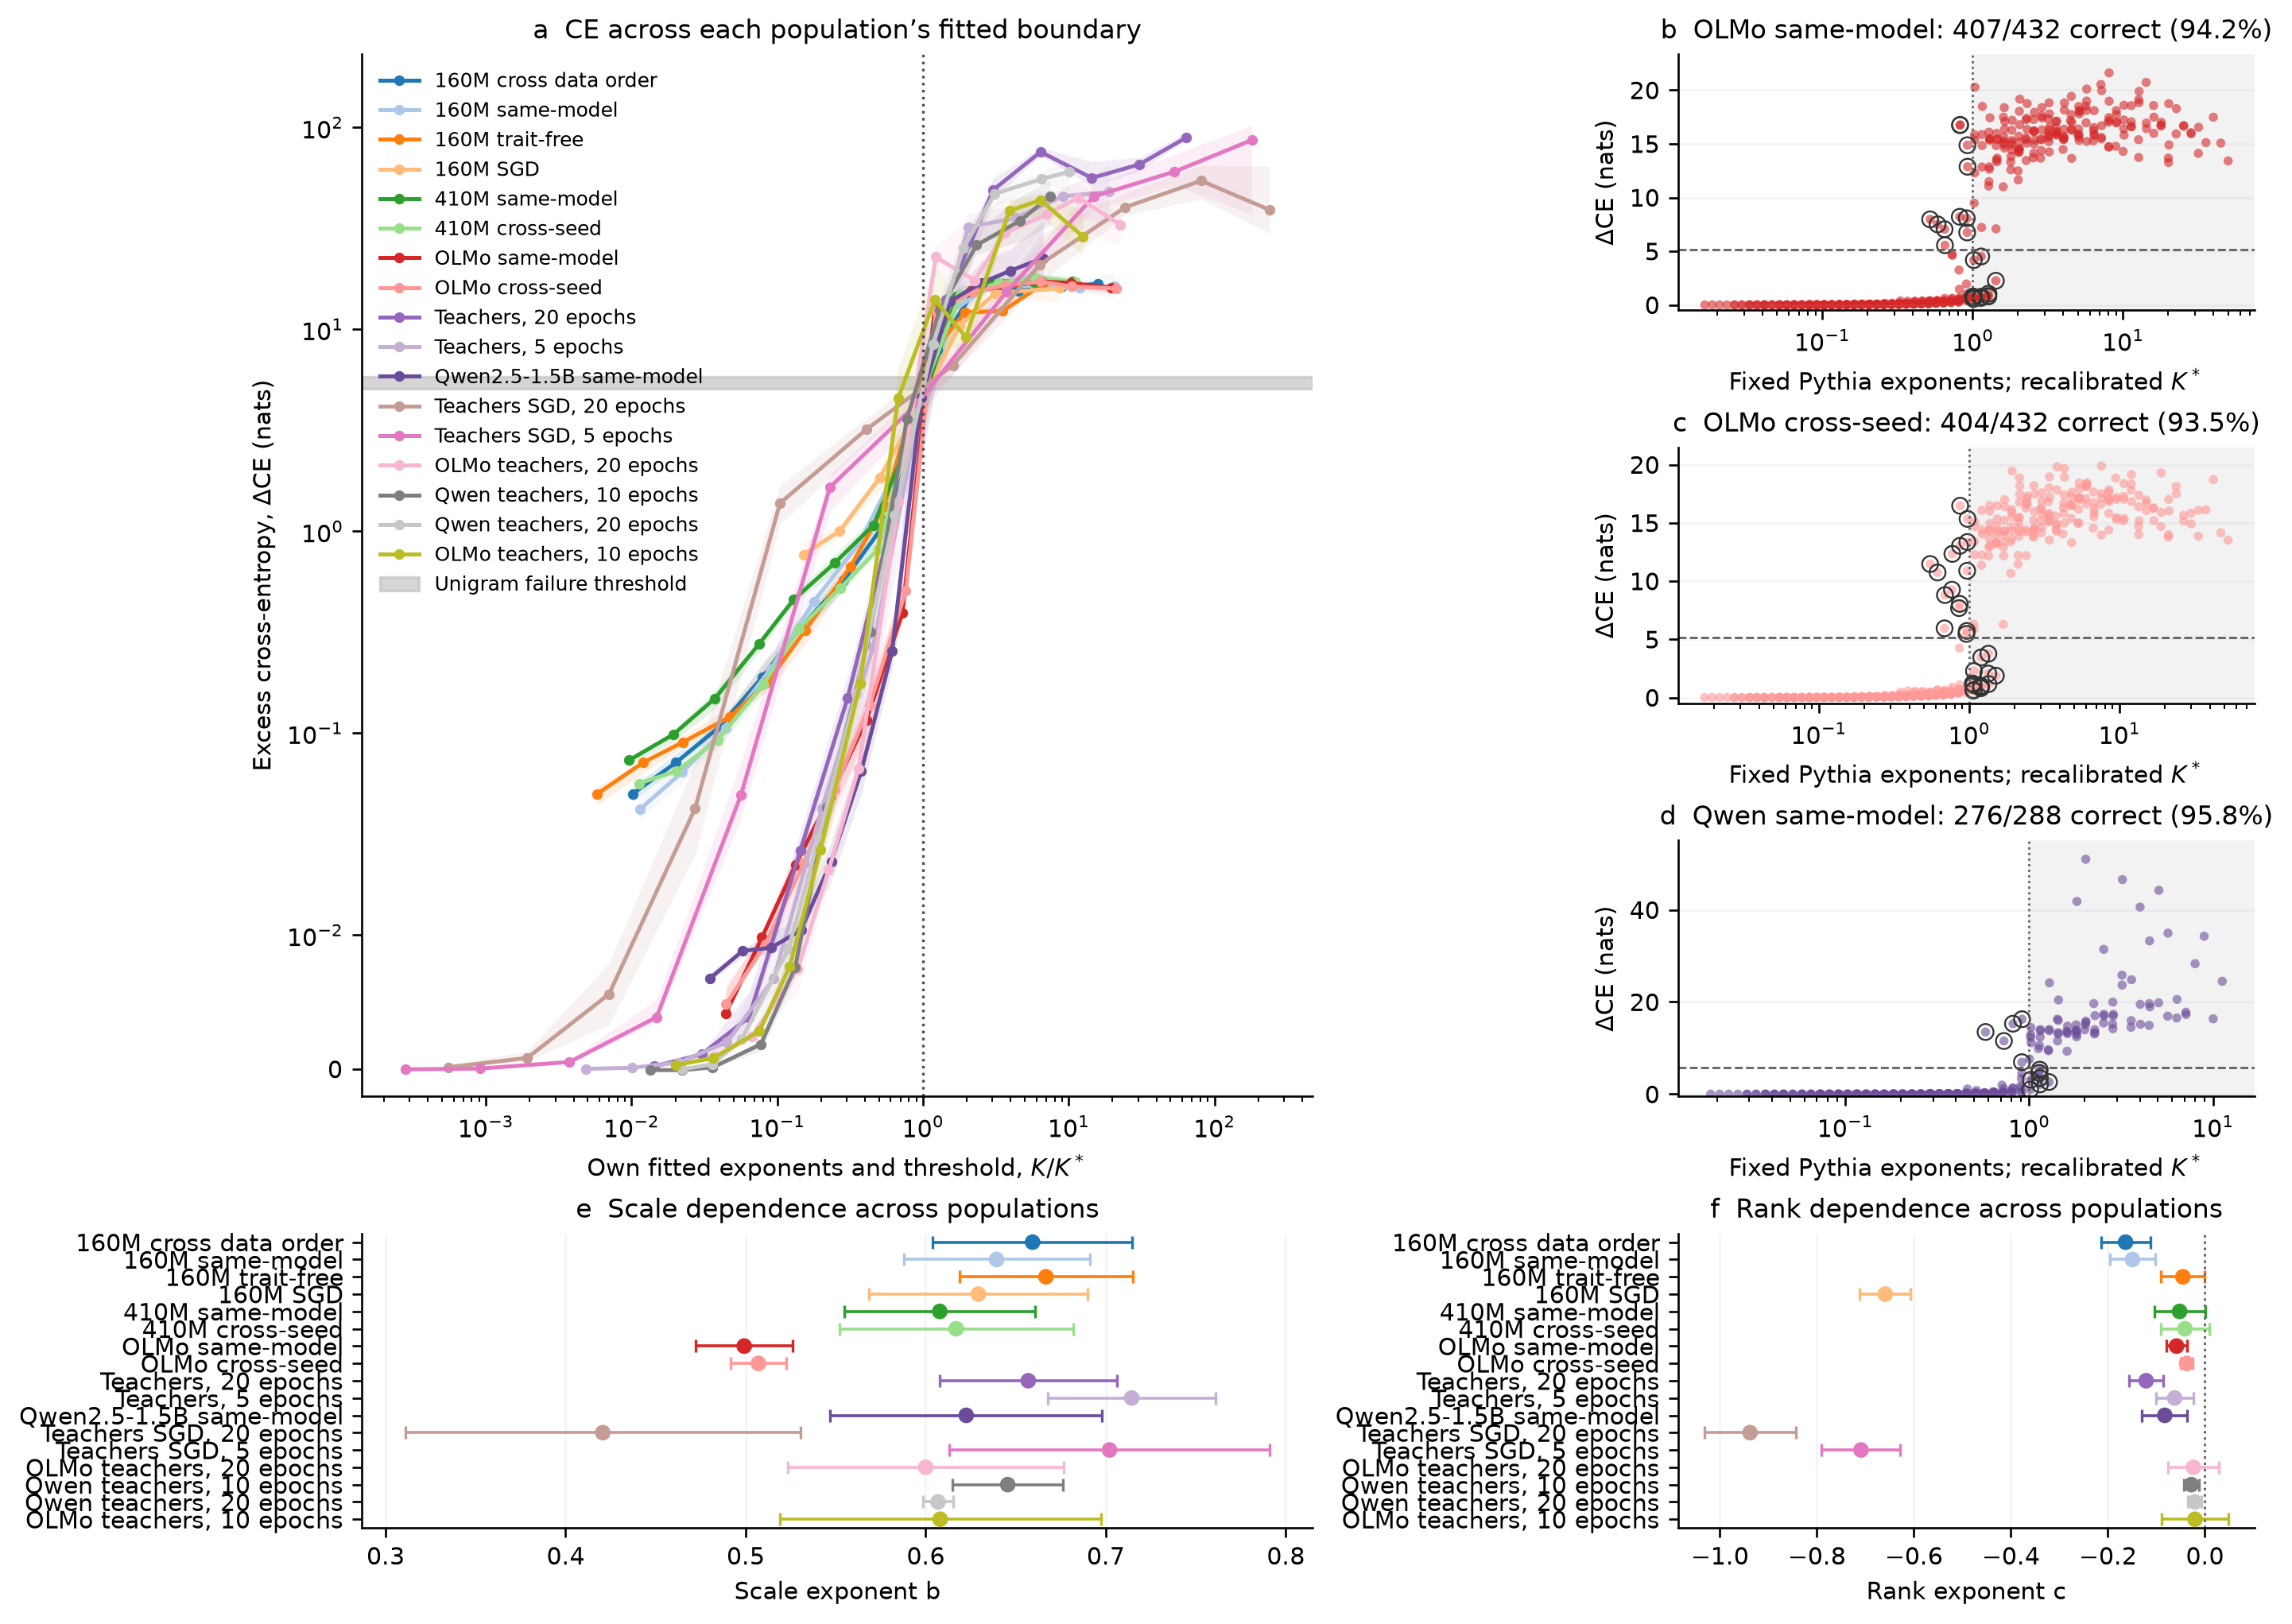

In [1]:
from IPython.display import Image, display
display(Image(filename=r'/home/angela/EleutherAI_subliminal_learning/docs/results/figures/iclr_20260909/fig01_boundary.png'))

Figure 2 — Boundary exponents are approximately stable through training while the failure threshold moves. Curves group experimental arms by model family, width, and training task: Pythia-160M students, Pythia-410M students, OLMo-1B students, Qwen-1.5B students, Pythia-160M animal-preference teachers under Adam and under plain SGD, and OLMo-1B and Qwen-1.5B animal-preference teachers. Fits are estimated separately in each arm using checkpoint-local failure labels. (a) Thresholds hold that arm's endpoint exponents fixed and are normalized by its endpoint threshold before aggregation. (b–c) Independent free fits estimate scale and rank exponents. Lines show equal-arm means at matched training percentages; shaded bands span the constituent arms, not confidence intervals. Pythia student groups and OLMo each combine two arms; Qwen and each teacher group contribute one; the Qwen teacher trajectory uses the 432-cell subset that has per-checkpoint measurements. Open squares mark checkpoints where an OLMo arm's logistic fit has no finite maximizer because all 432 measured outcomes are completely separated by a plane in the three log-hyperparameters. There the hard-margin separating plane is substituted for that arm before averaging, and the bar spans the exponents of every plane that perfectly separates the outcomes; these are not maximum-likelihood estimates. Where cells lie exactly on the plane, as at the 35% same-model OLMo checkpoint, they are excluded before the plane and range are computed. A substituted point is drawn only when its range is narrower than 0.1 in both exponents; the first teacher checkpoint fails this test, with admissible b from 0.33 to 3.3, and remains a gap. The fixed-exponent threshold in a remains estimable at all of these checkpoints. The right axis in a shows the normalized 5%-warm-up/cosine LR schedule, with warm-up shaded in all panels; K uses peak learning rate. Training budgets are 25,000 steps for Pythia students, 12,500 for OLMo, 6,250 for Qwen, and 60 for every 20-epoch teacher arm. The 5-epoch teacher arm lacks checkpoint CE measurements. Figure C2 shows individual arms and Appendix C gives coverage.

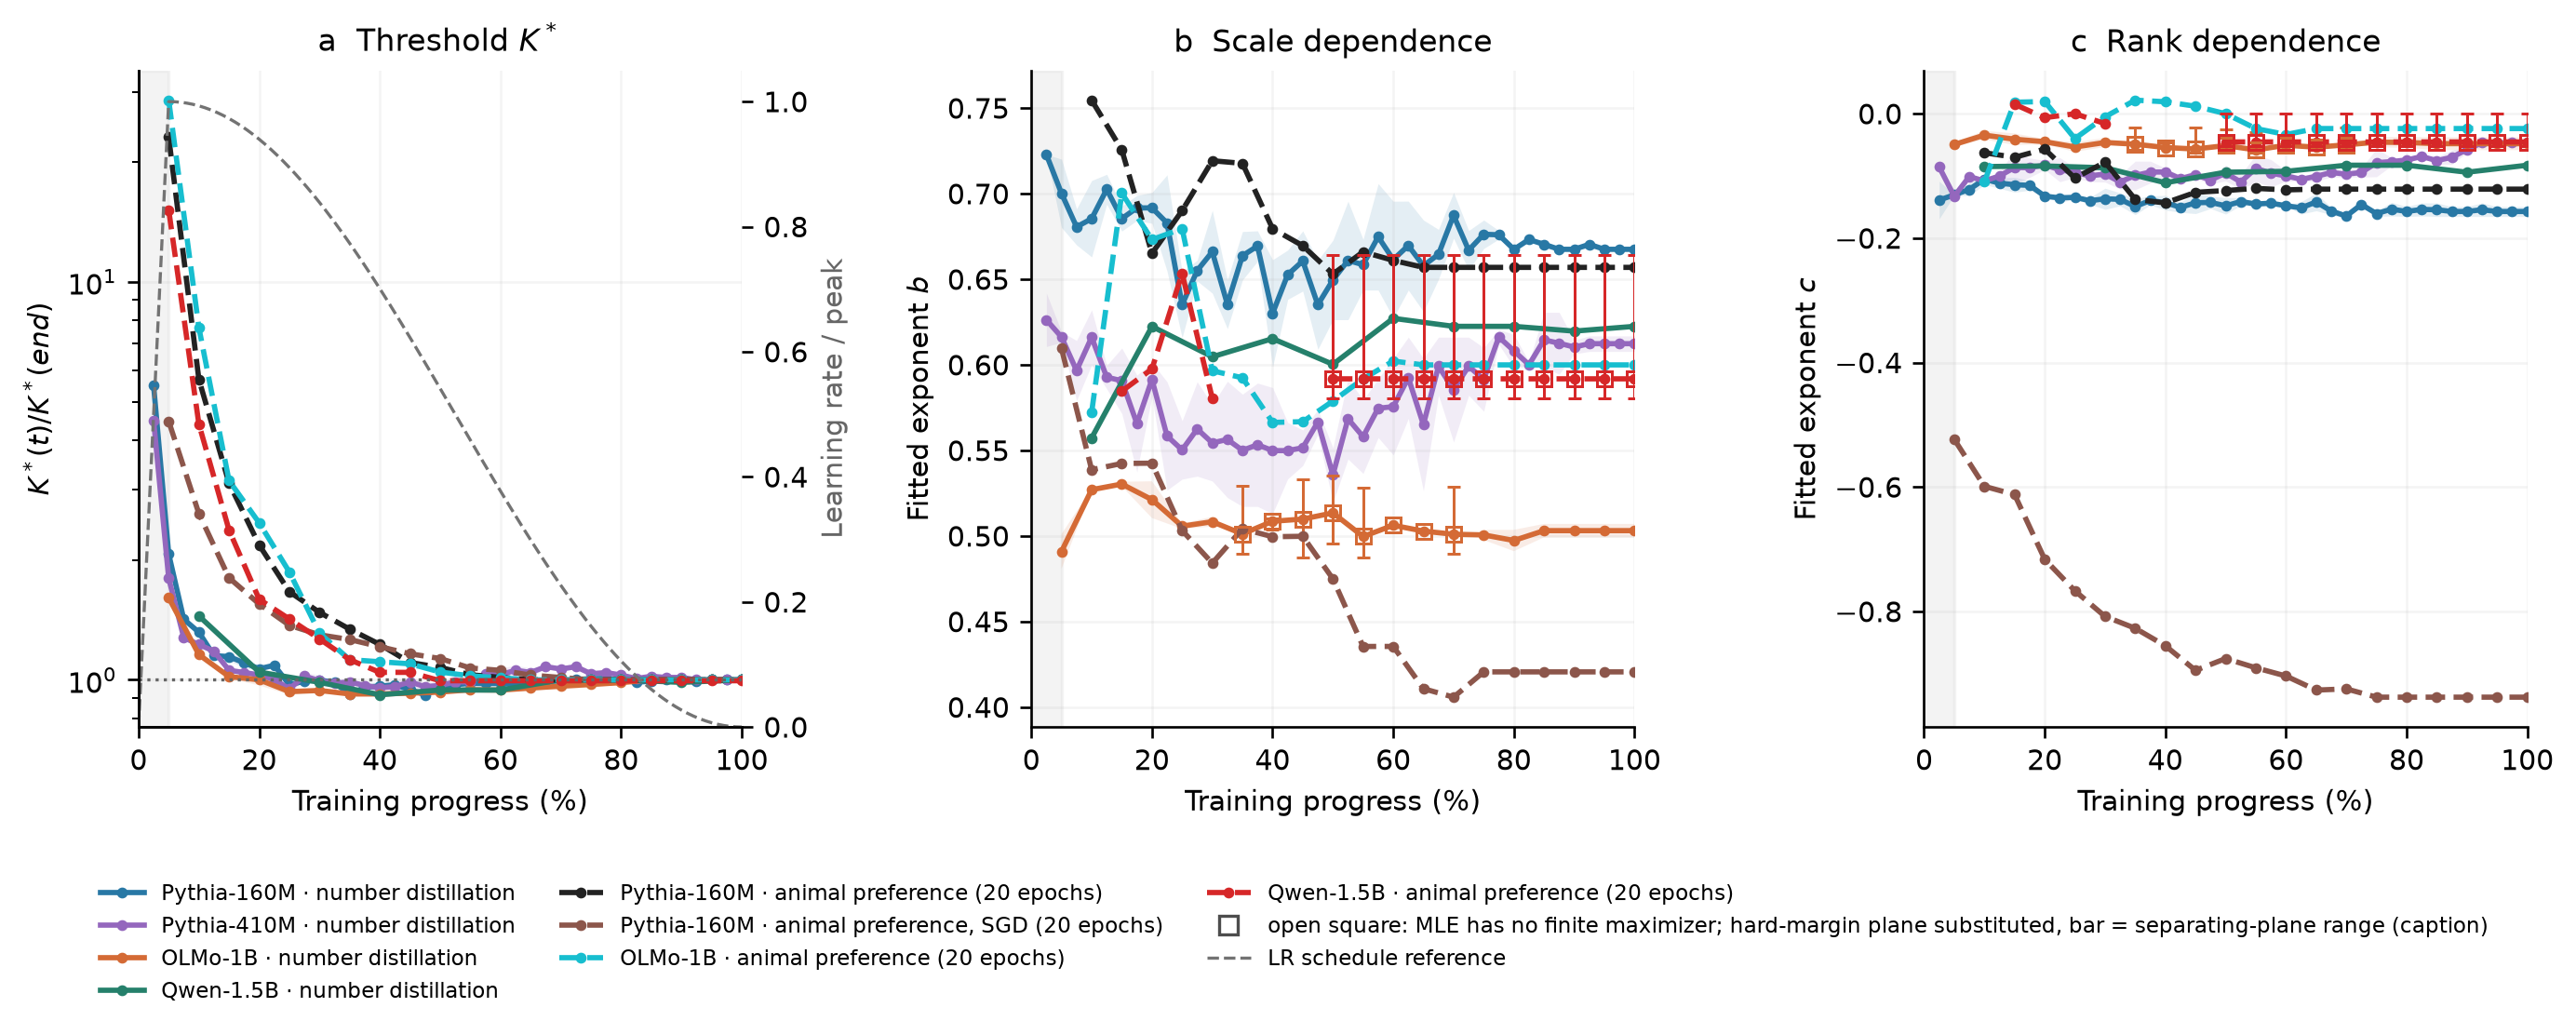

In [2]:
from IPython.display import Image, display
display(Image(filename=r'/home/angela/EleutherAI_subliminal_learning/docs/results/figures/iclr_20260909/fig03_training.png'))

Figure 3 — Optimizer choice shapes the forgetting boundary, and frozen/moved components partly explain its form under Adam. (a) Boundary scale and rank exponents, with 95% intervals, contrast same-model Pythia-160M Adam and SGD. (b) Learning-rate-normalized dose exponents show the same distinction in update magnitude; the dashed diagonal denotes equal and opposite scale and rank dependence. (c) Median moved/frozen norm ratio and interquartile range on the 890-run cross-data-order Adam support with alpha/r ≤ 64. (d) Fraction of component-only updates remaining above the failure threshold, conditional on the full update exceeding it, from evaluations of all 932 finite runs. Both components can be sufficient in the same run, so the fractions need not sum to one. The frozen term is (alpha/r) B A0 and the moved term is (alpha/r) B (A − A0). Component removal changes size and spectrum. Adam is implemented with adamw_torch and zero weight decay.

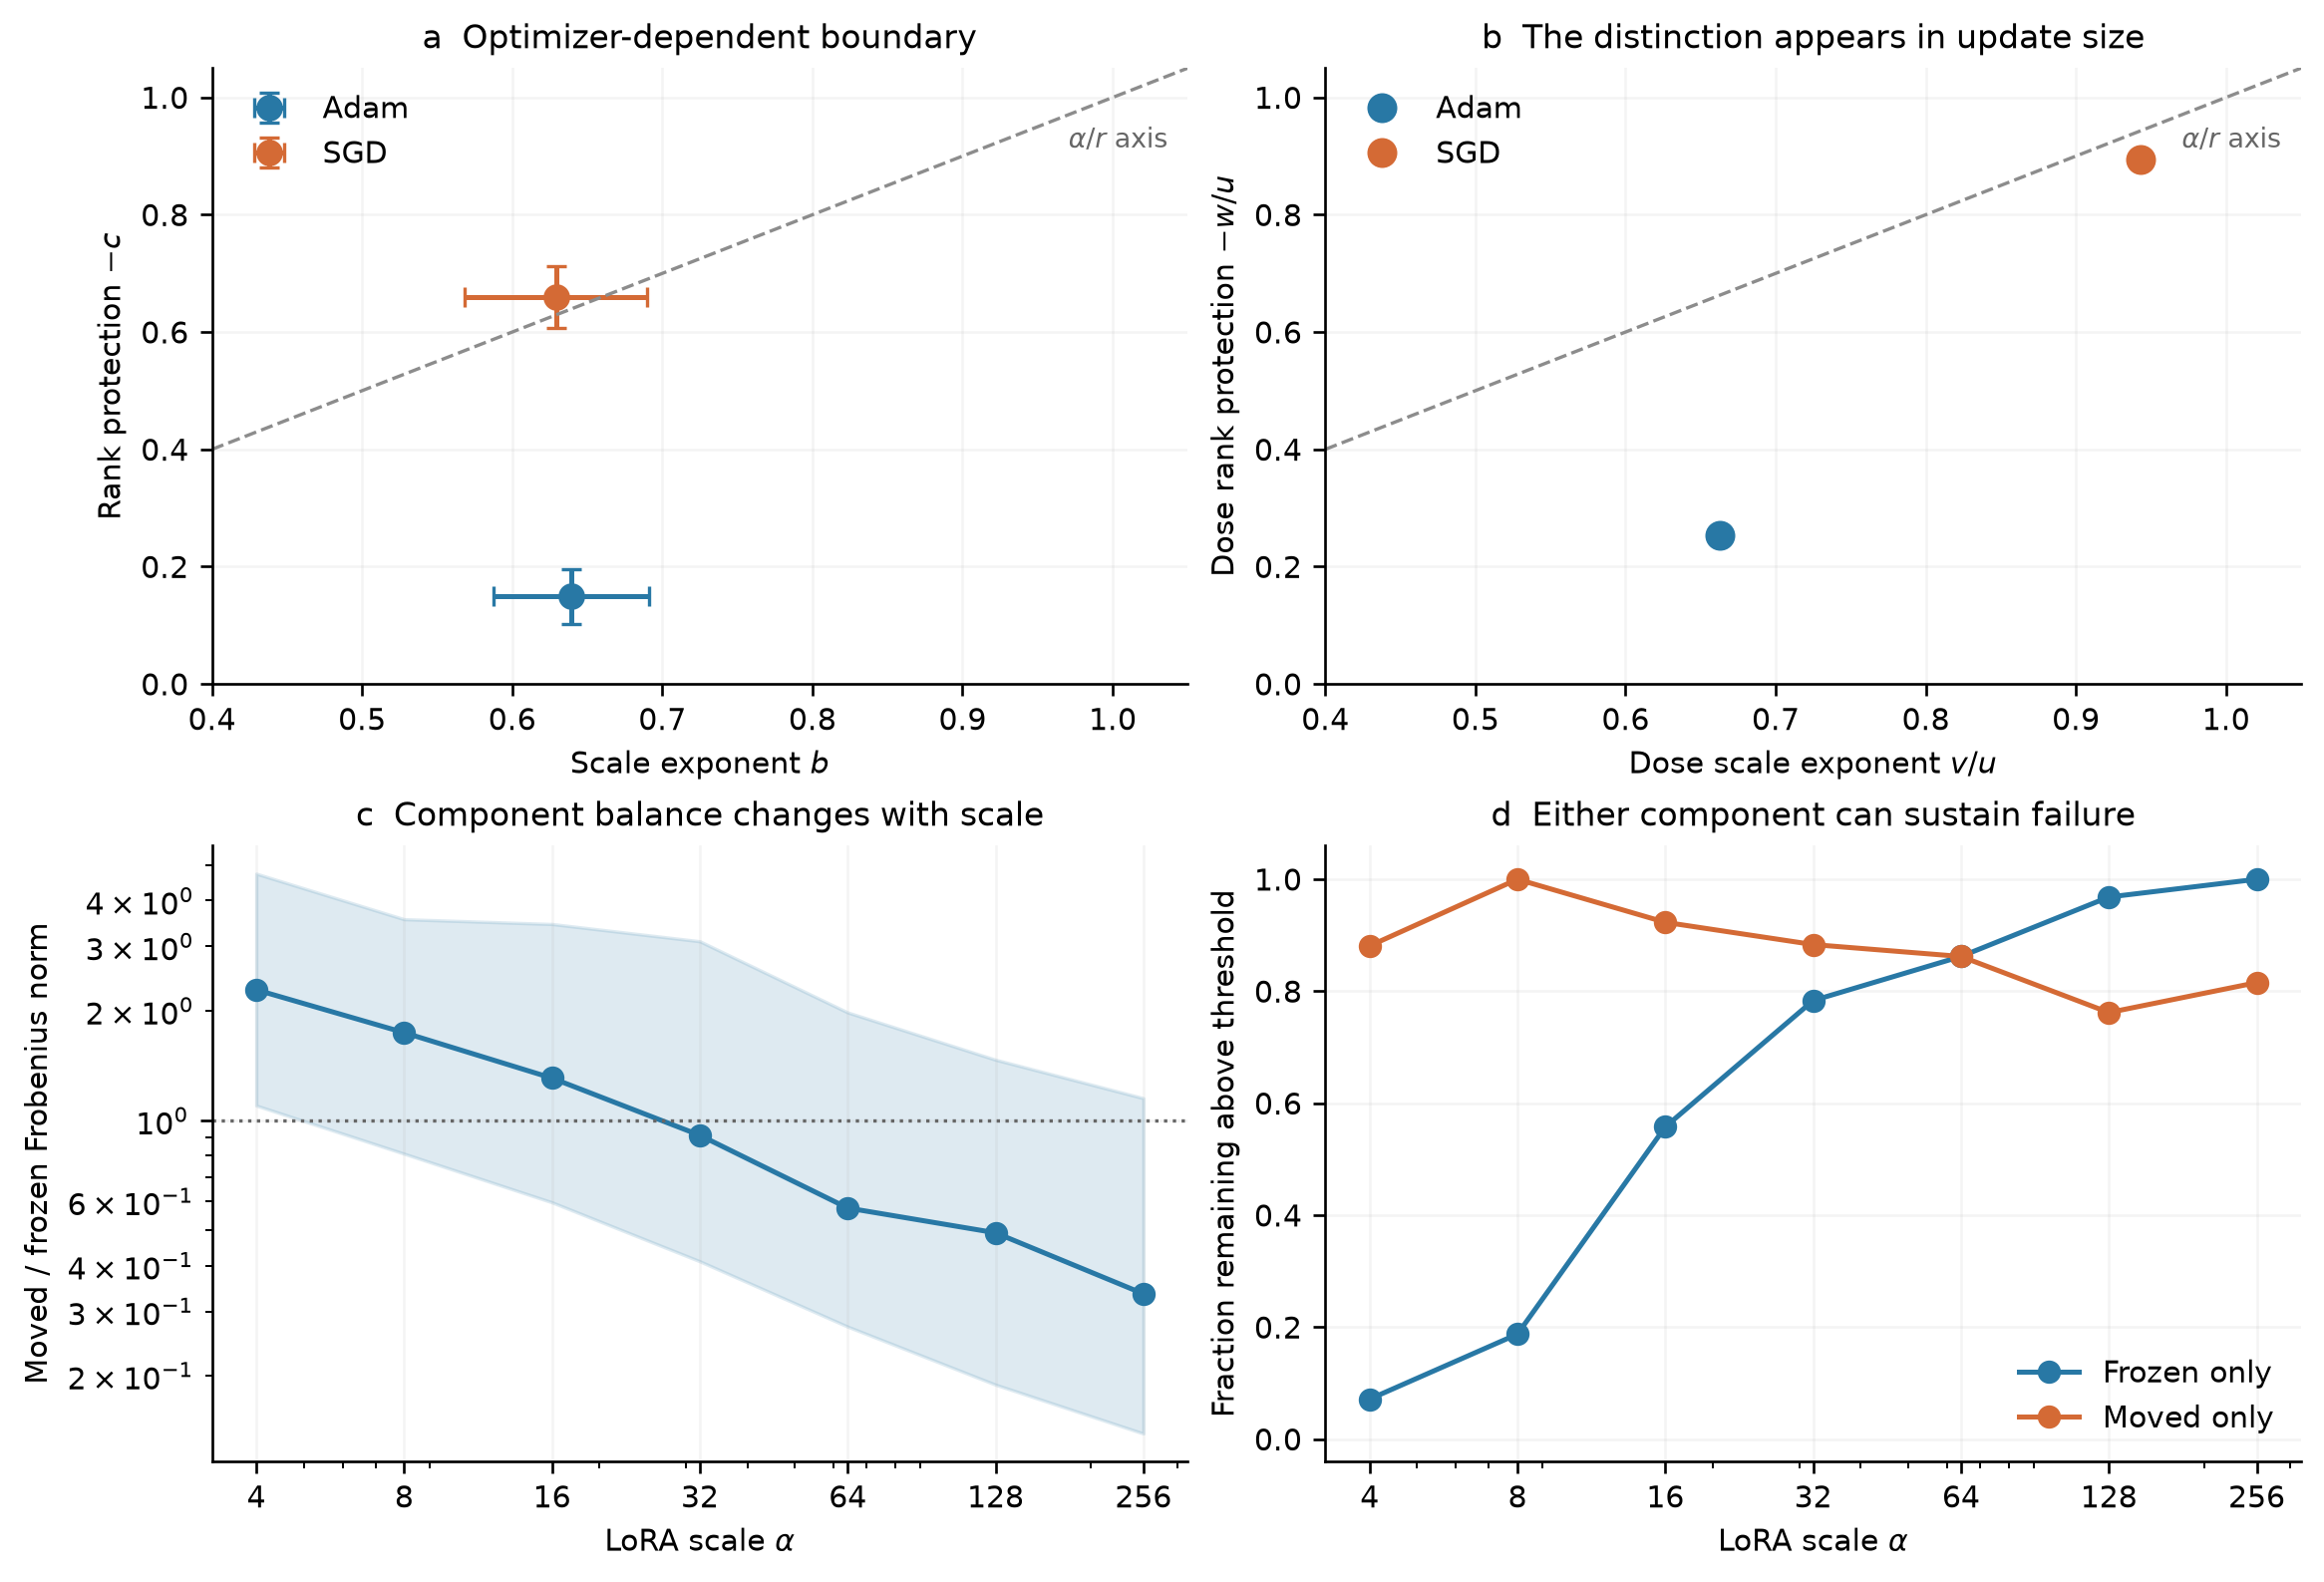

In [3]:
from IPython.display import Image, display
display(Image(filename=r'/home/angela/EleutherAI_subliminal_learning/docs/results/figures/iclr_20260909/fig02_optimizer_components.png'))

Skipped generator in display-only mode: `%run -i /home/angela/EleutherAI_subliminal_learning/docs/paper/plot_iclr_interventions.py`

Figure 4 — Strength and direction both affect forgetting. (a) Failure fractions across 13-dose rescaling ladders for 3,031 Pythia and 668 OLMo adapters. Each update retains its learned directions; g is realized Frobenius dose relative to the arm's endpoint-derived reference. (b–c) Native-dose learned–randomized pairs for all 2,501 finite Pythia adapters and all 432 configurations in each OLMo receiver. Direction replacement preserves every per-module singular value. Axes divide excess CE by the receiver-specific failure cutoff; the diagonal marks unchanged damage and lines at one mark failure. Axes are linear through ratio one and logarithmic above it. (d–e) Grouped bars compare learned and randomized failure percentages across shared doses g = 0.5 and 0.95 for the same-model and cross-seed OLMo receivers. Every bar uses the same 432 configurations; each learned–randomized pair is evaluated at the same dose and spectrum. Native doses vary across runs and are not plotted as a shared g. The population uses one random target per adapter, paired across doses, without selection for randomized recovery. Shared mean dose does not equalize spectra across different runs. Table E1 gives exact recovery denominators; Figure S1 shows the OLMo paired distributions.

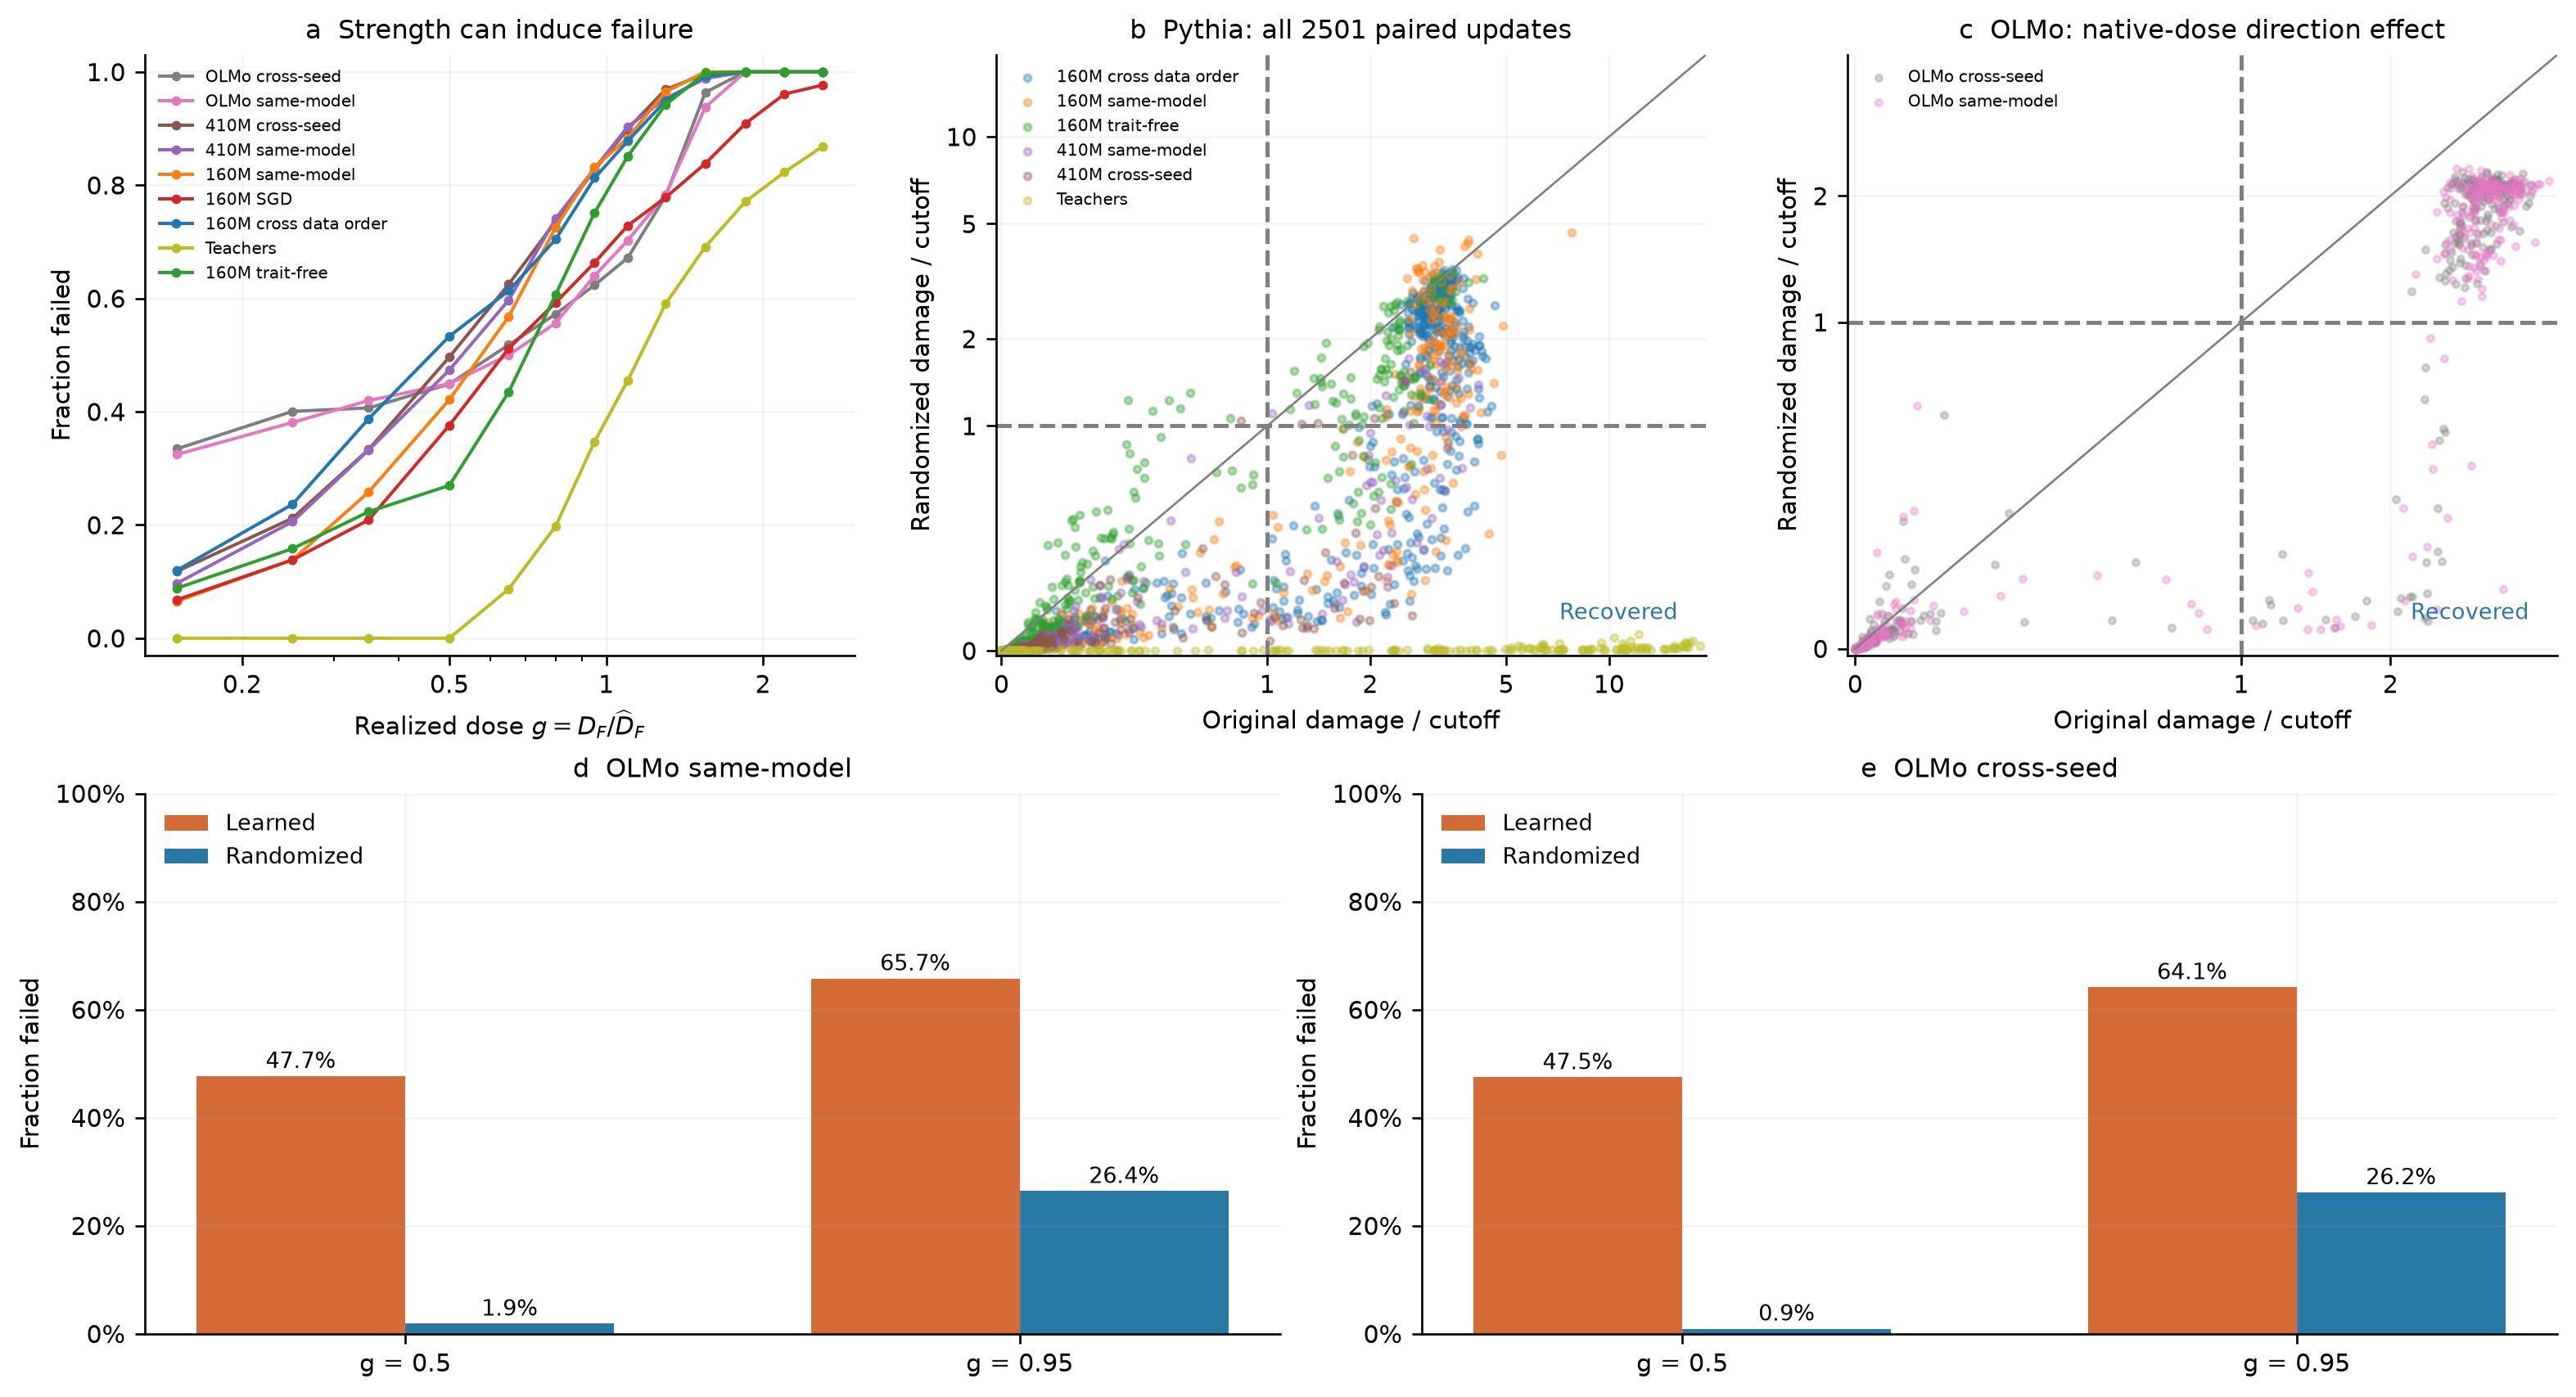

In [4]:
from IPython.display import Image, display
display(Image(filename=r'/home/angela/EleutherAI_subliminal_learning/docs/results/figures/iclr_20260909/fig04_dose_direction.png'))

Figure 5 — Measured intruders are neither required for nor sufficient to produce catastrophic failure. (a–b) Individual naturally trained teachers and trait-free students, grouped by measured intruder absence or presence. Excess CE is divided by the receiver-specific failure cutoff; the line at one marks catastrophic failure. Among failed teachers, 57/126 have no measured intruders. Among finite trait-free students below the cutoff, 178/233 contain them. The populations are displayed separately and are not a matched causal comparison. Exact duplicate scan rows are removed. (c) Constructive counterexamples: a base-aligned rank-one injection in every Pythia ds1 matrix at per-module Frobenius size 2 times its estimated formation scale causes failure with zero intruder-bearing matrices; random rank-one injections at one formation scale in each OLMo receiver produce widespread intruders with little damage. Counts cover all 48 Pythia or 64 OLMo adapted matrices. These are distinct counterexamples at specified doses, not matched cross-model source effects. Intruders are measured in resulting weights using Shuttleworth et al.'s (2024) top-ten left-vector overlap criterion at 0.5; random update vectors are not automatically intruders. The result concerns this detector and catastrophic failure, not the absence of smaller losses or causal effects of particular learned intruders. The injection design adapts Xie (2026, §4). Vertical axes are linear near zero and logarithmic for larger damage.

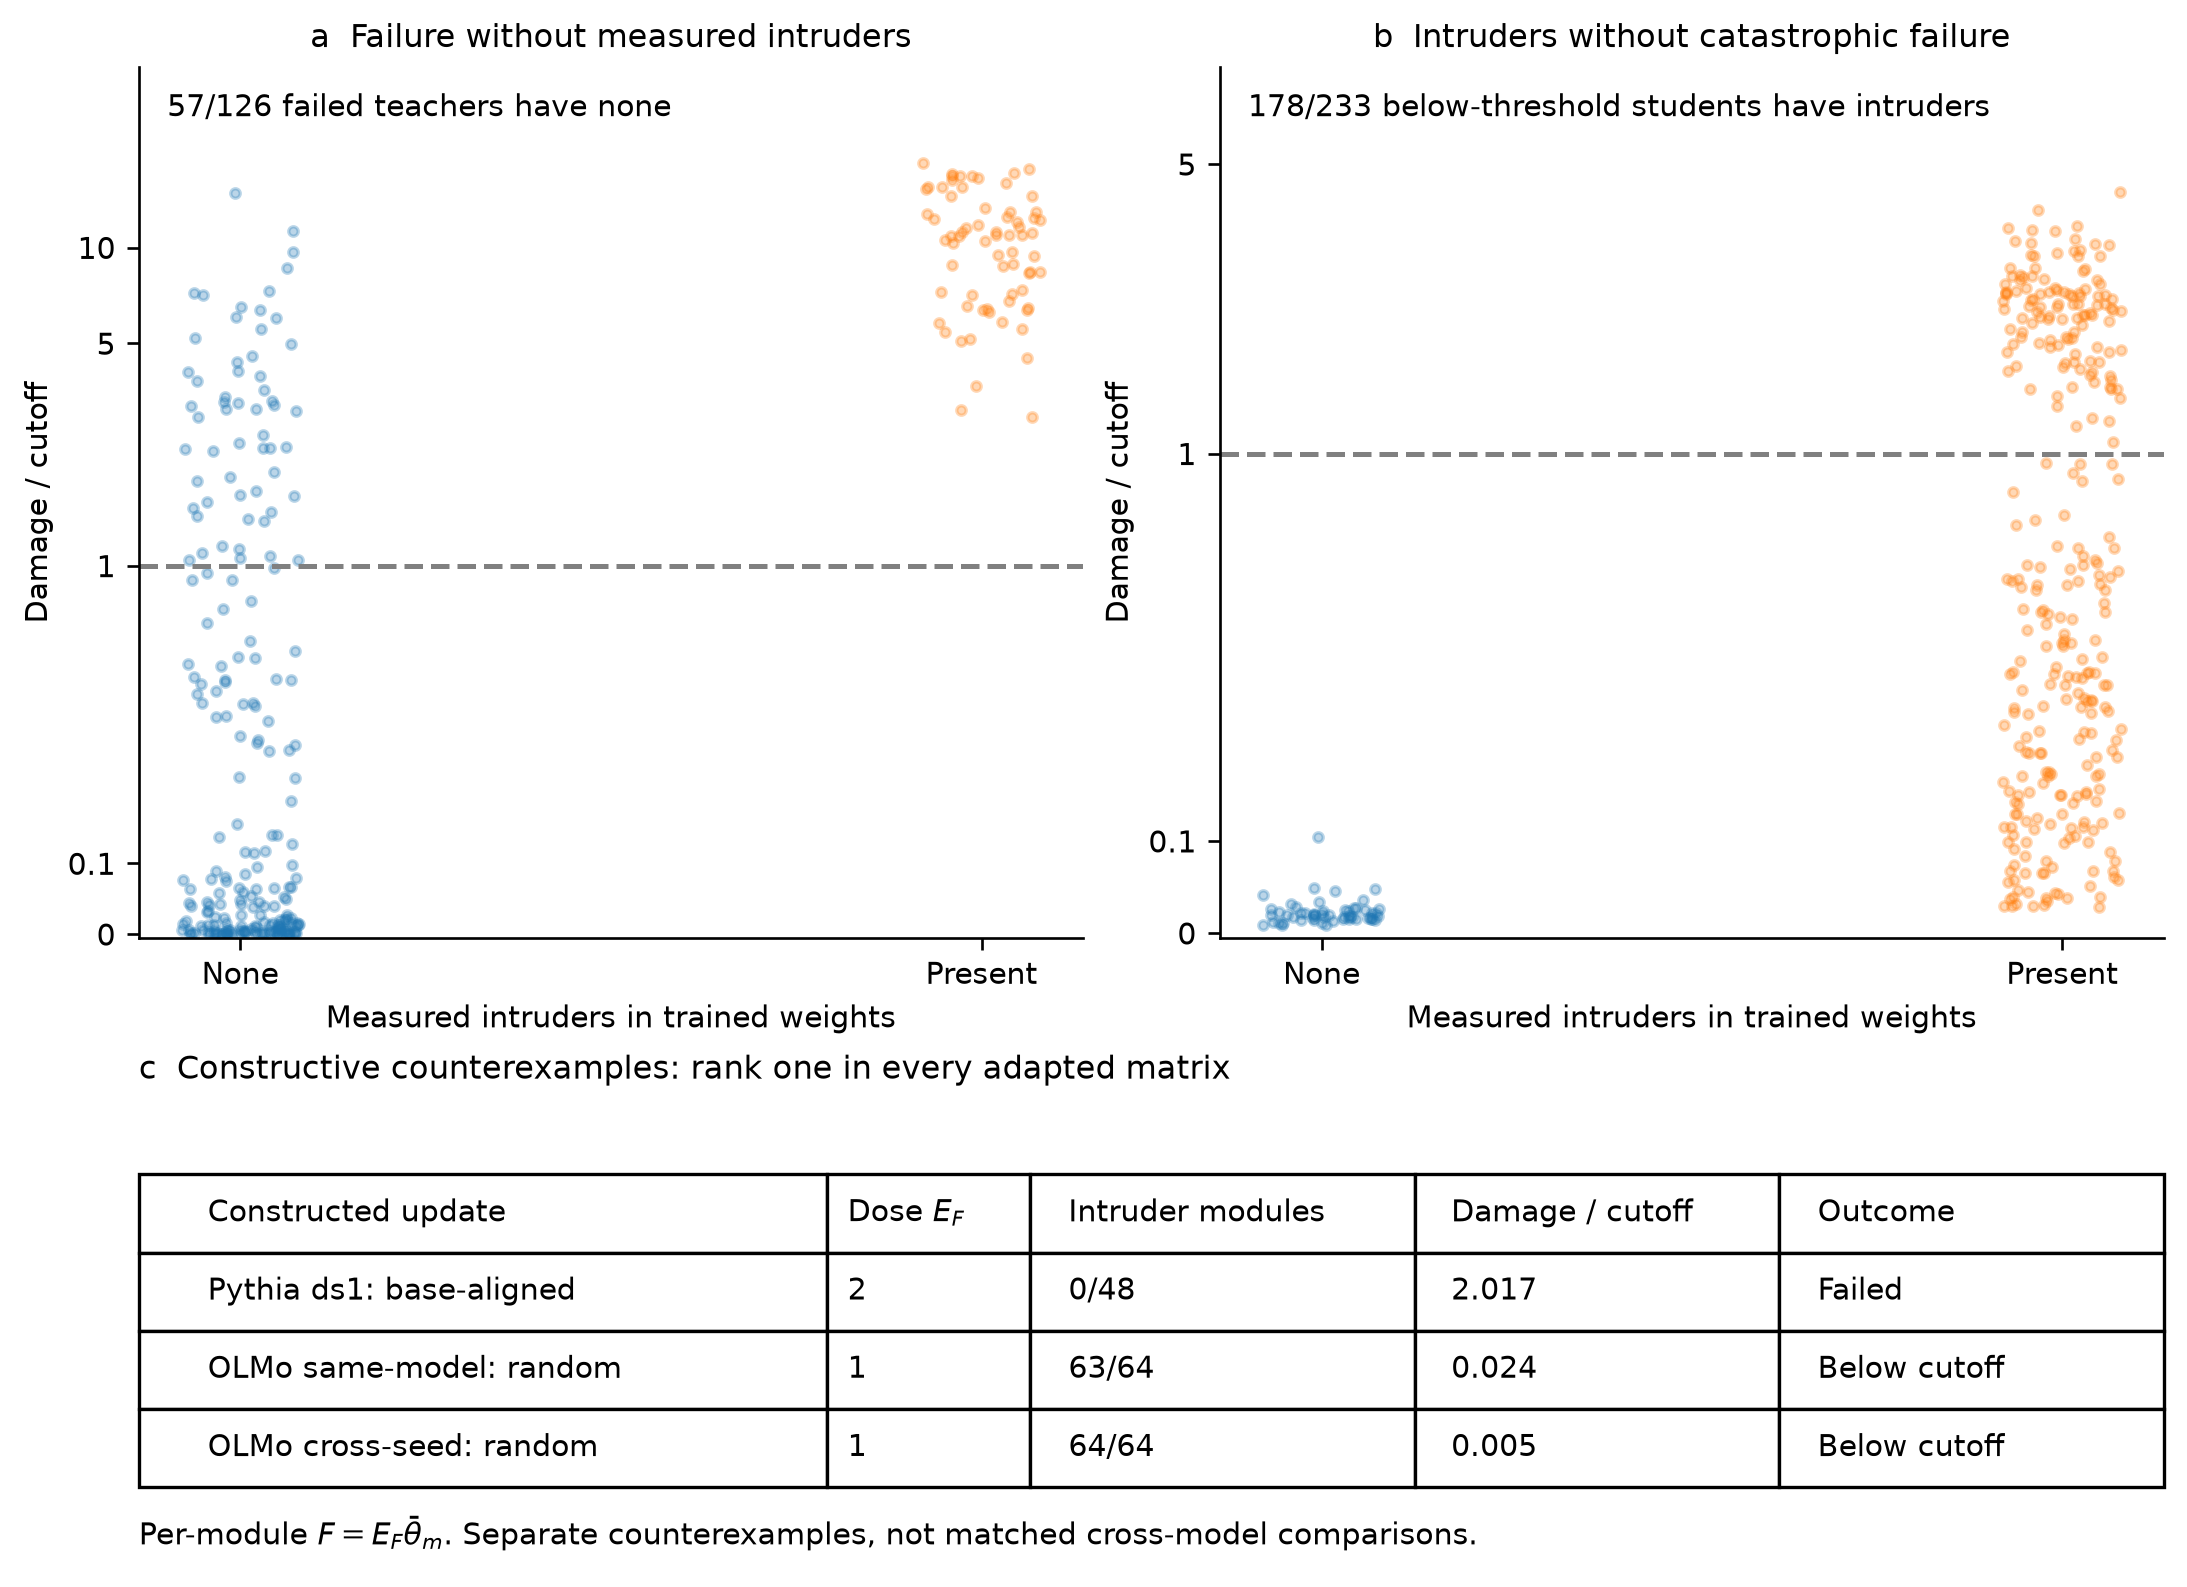

In [5]:
from IPython.display import Image, display
display(Image(filename=r'/home/angela/EleutherAI_subliminal_learning/docs/results/figures/iclr_20260909/fig05_intruders.png'))

Figure 6 — Replacing leading update directions can restore teacher prediction while preserving the acquired preference. The same 126 initially failed teachers are evaluated under five conditions: original, replacement of the strongest one, two, or four singular-vector pairs per matrix, and replacement of the complement of the strongest four. Every condition retains all singular values. (a) Predictive damage relative to the failure cutoff. Top-one replacement returns 123/126 teachers below it; top-four replacement recovers all 126, while replacing its complement recovers none. (b) Target-preference probability in those same teachers. Mean preference remains 0.914 after top-one replacement but falls to 0.176 and 0.026 after top-two and top-four replacement. Individual observations and distributions distinguish the population spread from these summaries. Replacing directions is not removing singular components. Recovery denotes crossing below the unigram reference, not necessarily restoring base-model performance. This teacher result does not establish preservation of student subliminal transfer, and localization is less uniform in student populations (Appendix E.4). Boxes show medians and interquartile ranges, with whiskers extending to observations within 1.5 interquartile ranges; all observations are overlaid. Diamonds mark mean preference. The damage axis is linear near zero and logarithmic for larger values.

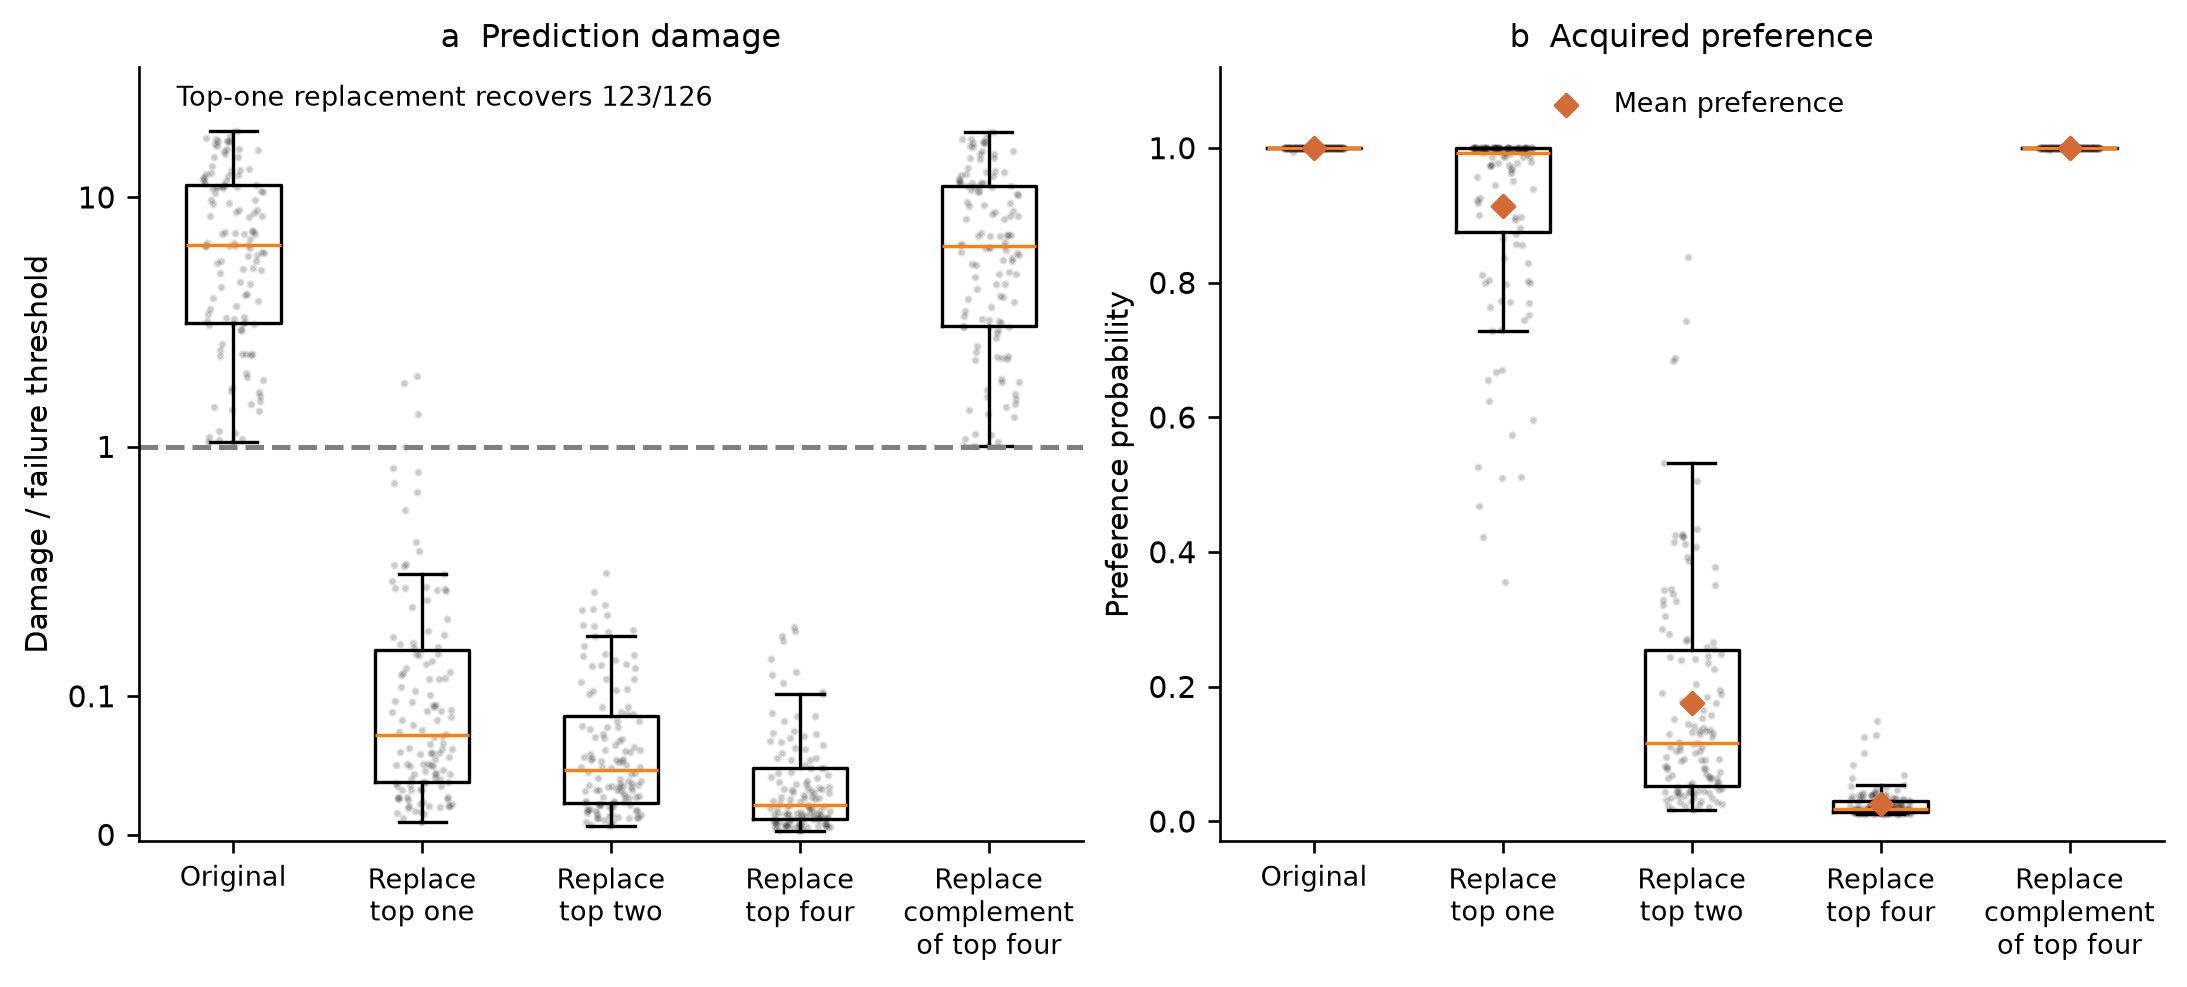

In [6]:
from IPython.display import Image, display
display(Image(filename=r'/home/angela/EleutherAI_subliminal_learning/docs/results/figures/iclr_20260909/fig06_trait_collapse.png'))

# Cross-population boundary transfer

**Table 3. Boundary transfer remains accurate across model families and training tasks after target calibration.** Ranges summarize directed source–target comparisons among the ten Adam populations, excluding each fit's own population. Every comparison retains the source exponents and recalibrates the threshold in the target population.

| Transfer comparison | Directed fit pairs | Accuracy range |
|---|---:|---:|
| All pairs | 90 | 93.5–99.1% |
| Within model family, same training task | 24 | 94.8–99.1% |
| Within model family | 44 | 94.8–99.1% |
| Across model families, same training task | 34 | 93.5–98.7% |
| Across model families | 46 | 93.5–98.7% |
| Across training tasks, Pythia only | 20 | 95.0–99.0% |

Model family means Pythia, OLMo, or Qwen; both Pythia sizes belong to the same family. Training task means animal-preference learning or number distillation. Rows without a same-task restriction include both same-task and cross-task pairs. Animal-preference teacher fits are all Pythia, so cross-family same-task pairs all concern number distillation. The final row includes both task-transfer directions within Pythia. Identical ranges do not imply identical comparisons: adding cross-task pairs leaves the within-family and cross-family extrema unchanged. Rows overlap and are not independent replications. Calibration and evaluation use the same target outcomes.

Figure C1 — Boundary coordinates transfer across the tested populations after threshold calibration, with weaker transfer across the optimizer change. Rows supply the source fit and columns identify the target population. Each cell reports classification accuracy (%) after fixing the source scale and rank exponents and fitting a logistic threshold and transition slope on the target outcomes. Outlined diagonal entries evaluate each fit on its own population. The full matrix includes all eleven finite-run populations, including SGD; Table 3 summarizes off-diagonal Adam-to-Adam comparisons only. P160 and P410 denote Pythia-160M and Pythia-410M; CDO is cross-data-order distillation, Same is same-model distillation, TF is trait-free distillation, and Cross is a different receiver pretraining seed. T20 and T5 denote direct animal-preference teacher training for 20 and 5 epochs. OLMo-Cross is receiver seed 2; Qwen is Qwen2.5-1.5B same-model distillation. Source exponents and population sizes are in Table D1 and Table 1. Target calibration and evaluation use the same outcomes, so these are not held-out accuracies. The diagonal need not maximize column accuracy because the fits optimize likelihood rather than classification count.

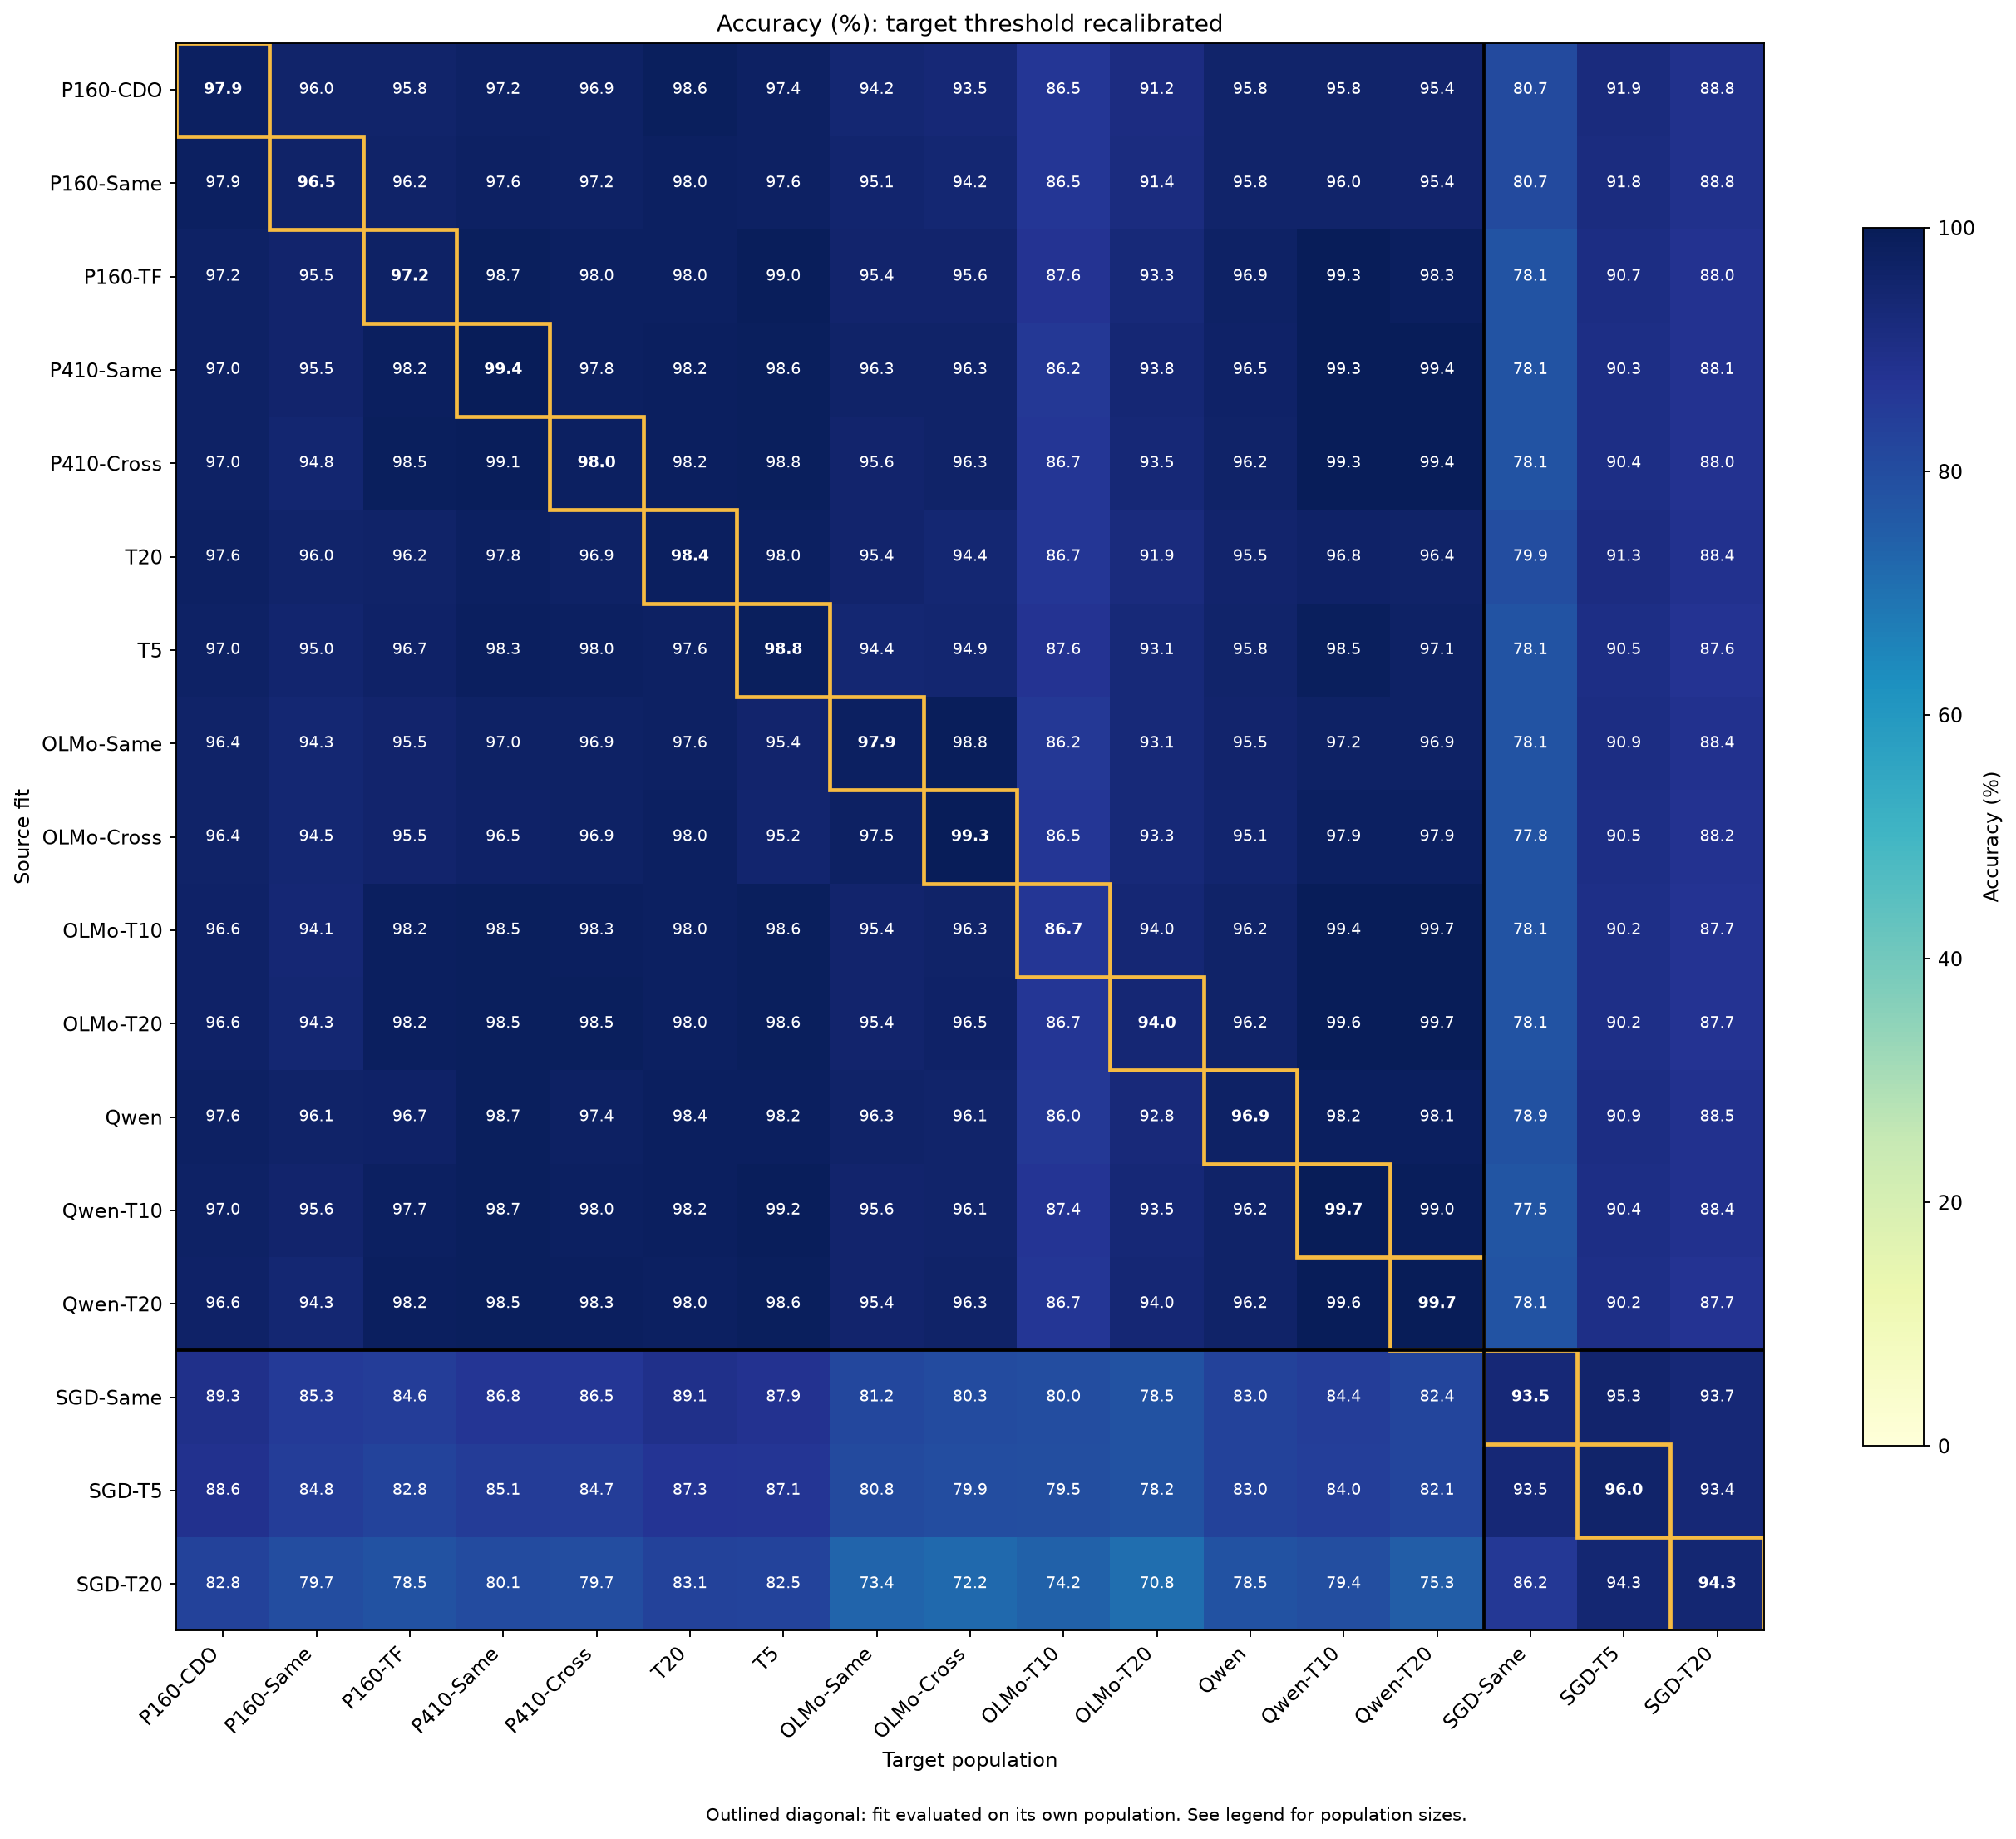

In [7]:
from IPython.display import Image, display
display(Image(filename=r'/home/angela/EleutherAI_subliminal_learning/docs/results/figures/boundary_transfer_matrix/boundary_transfer_accuracy.png'))

<!-- END GENERATED ICLR FIGURE SET -->

<!-- BEGIN VERIFIED DIRECTION ANALYSIS 20260914 -->
# Direction interventions: purpose and corrected evidence

The central question is: **does an update damage the model because of its size,
its directions, or specifically because it creates intruders?** Different
experiments address different parts of that question. They should not all be
presented as independent demonstrations of the same mechanism.

This block uses the corrected Pythia census and September 14 Pythia/OLMo
reassessments. It runs analysis only, not models. Full Pythia top/complement
replacement covers 2,501 finite adapters; its 546 threshold-selector runs retain
historical recovery-based selection. OLMo covers all 432 configurations per
receiver at each of three doses, with 77 structured detailed configurations per
receiver and three replacement draws. Other notebook cells are preserved; older
generated blocks are replaced rather than left as competing current summaries.

We distinguish **formation**, **prediction**, **causation**, and
**necessity/sufficiency**. Shuttleworth's intruder-specific singular-value scaling
motivates the causal question; our update-direction replacement is a different
intervention. Xie's formation scale and concentrated/diffuse × generic/aligned
injections motivate the threshold and injection controls. Their causal evidence
does not require intruders to be necessary or sufficient for every severe failure.
Our counterexamples constrain necessity and sufficiency, not every causal role.

Fixed-direction rescaling asks whether update strength changes damage. Replacing
directions at an identical spectrum tests whether that spectrum alone determines
damage. These are the primary controls. Top/complement replacement localizes
sensitivity, but unequal component counts and energy limit its interpretation.
Supercritical replacement does not directly remove intruders measured in the
resulting weights. Partial rotation tests a response path; monotonicity holds in
the twelve selected Pythia paths, not generally across OLMo.

Corrected random injections use `nested_signed_qr_v2`: one maximum-rank frame per
module and draw, with prefixes reused across rank and dose. Fixed F changes
spectral norm with rank; fixed S changes Frobenius norm with rank. Neither isolates
rank alone. At equal actual spectrum and allocation, changing direction source
tests direction identity. The donor pair remains a limited descriptive control,
not a donor-population ranking. OLMo has no fixed-spectral injection ladder.

OLMo native randomization usually lowers damage but seldom rescues severe
failures. Shared-dose comparisons demonstrate large direction effects without
selection on randomized recovery. Widespread measured intruders coexist with low
damage in corrected OLMo random injections, counted across all 64 matrices.
Unchanged OLMo aligned controls retain only eight-module intruder coverage.
Naturally trained intruder counterexamples are separate evidence from synthetic
random directions. Intruders without failure challenge sufficiency; failure
without intruders challenges necessity.

Full framing and interpretation:
`docs/results/direction_experiment_framing_original.md`,
`docs/results/pythia_direction_reassessment_20260914.md`, and
`docs/results/olmo_direction_reassessment_20260914.md`.


In [8]:
from pathlib import Path
import json, hashlib
import pandas as pd
from IPython.display import display, Image
root = Path('/home/angela/EleutherAI_subliminal_learning')
evidence = root / 'docs/paper/evidence'
pythia = evidence / 'direction_corrected_20260912'
supplement = evidence / 'pythia_corrected_20260914'
olmo = evidence / 'olmo_corrected_20260914'
assert json.loads((supplement / 'provenance.json').read_text())['pythia_supplement_complete']
assert json.loads((olmo / 'provenance.json').read_text())['olmo_complete']
# Every recorded source must match its hash: exact bytes, or a PEFT adapter_config.json that differs
# only in the order of set-valued fields (target_modules etc.). Lists every failure, not just the first.
from subliminal_learning.utils.provenance import verify_evidence_folder
for folder in (pythia, supplement, olmo):
    print(folder.name + ':', verify_evidence_folder(folder).summary())
def table(folder, name):
    return pd.read_csv(folder / (name + '.csv'))
print('Corrected measurements: 2,501 Pythia census runs; 864 OLMo runs at three doses.')
cs = table(pythia, 'census_summary')
display(cs[cs.original_failed & cs.variant.isin(['rand0', 'top1', 'top4', 'rest4'])])


direction_corrected_20260912: 2592 sources: 2592 exact, 0 set-order only, 0 missing, 0 changed


pythia_corrected_20260914: 27 sources: 27 exact, 0 set-order only, 0 missing, 0 changed


olmo_corrected_20260914: 988 sources: 988 exact, 0 set-order only, 0 missing, 0 changed
Corrected measurements: 2,501 Pythia census runs; 864 OLMo runs at three doses.


,arm,original_failed,variant,n,below_cut,median_ce,median_paired_change,mean_trait
9,m410cross,True,rand0,27,22,1.461257,-6.519778,3.911415e-03
12,m410cross,True,rest4,19,9,5.864057,-2.434401,2.845280e-03
13,m410cross,True,top1,24,17,4.158990,-4.492020,1.821765e-03
15,m410cross,True,top4,19,19,1.185215,-6.565724,6.182336e-03
25,m410same,True,rand0,60,41,4.058666,-8.497996,3.518371e-03
28,m410same,True,rest4,39,8,11.187907,-2.003174,1.324756e-02
29,m410same,True,top1,53,16,7.491408,-4.431261,3.186207e-03
31,m410same,True,top4,39,29,3.544664,-8.635722,5.353318e-03
41,samemodel,True,rand0,174,53,8.107367,-6.816644,6.987852e-04
44,samemodel,True,rest4,89,5,14.041480,-1.943789,9.473560e-02


In [9]:
fro = table(pythia, 'frobenius_injections')
spec = table(supplement, 'spectral_observations')
print('Pythia nested fixed-F endpoints; three random draws per receiver:')
display(table(pythia, 'frobenius_endpoints'))
print('Pythia nested fixed-S endpoints; three random draws on ds1:')
display(table(supplement, 'spectral_endpoints'))
print('Equal-strength spectra obey F=sqrt(k)*S; neither sweep isolates rank alone.')
print('Aligned controls preserve existing base directions; measured intruders are from resulting weights:')
display(fro[(fro['align'] == 'a') & (fro.k == 1)])


Pythia nested fixed-F endpoints; three random draws per receiver:


,receiver,seed,E,1,2,4,8,16,32,change_32_minus_1
0,EleutherAI/pythia-160m,0,0.5,6.671084,6.883596,6.318866,6.179373,6.640431,5.883563,-0.787522
1,EleutherAI/pythia-160m,0,1.0,12.460806,13.216606,10.767742,11.029302,12.334184,11.050780,-1.410026
2,EleutherAI/pythia-160m,0,2.0,17.855385,18.572232,16.562552,16.399336,17.489582,17.119632,-0.735753
3,EleutherAI/pythia-160m,0,4.0,21.620997,21.019605,21.110547,21.289015,20.390688,20.410341,-1.210656
4,EleutherAI/pythia-160m,1,0.5,8.908916,6.616233,6.569537,7.209695,6.628980,5.852931,-3.055985
5,EleutherAI/pythia-160m,1,1.0,11.875880,11.316391,12.112962,13.133587,11.820294,11.076701,-0.799179
6,EleutherAI/pythia-160m,1,2.0,17.867204,17.146822,17.876874,18.037504,18.453591,16.815671,-1.051534
7,EleutherAI/pythia-160m,1,4.0,23.173347,22.041087,23.974481,21.651597,21.965112,21.773348,-1.399999
8,EleutherAI/pythia-160m,2,0.5,9.395160,7.643928,6.995677,6.008829,5.840552,5.869327,-3.525832
9,EleutherAI/pythia-160m,2,1.0,15.415316,14.319286,11.201834,11.461549,11.547032,11.077984,-4.337331


Pythia nested fixed-S endpoints; three random draws on ds1:


,receiver,seed,E,1,4,16,32,change_32_minus_1
0,EleutherAI/pythia-160m-data-seed1,0,0.25,3.888705,6.217860,9.539476,10.946350,7.057645
1,EleutherAI/pythia-160m-data-seed1,0,0.50,6.978679,10.794631,13.900909,13.957579,6.978901
2,EleutherAI/pythia-160m-data-seed1,0,1.00,10.832928,14.066061,17.121873,15.878954,5.046026
3,EleutherAI/pythia-160m-data-seed1,0,2.00,14.576669,16.398380,17.042917,15.863052,1.286383
4,EleutherAI/pythia-160m-data-seed1,1,0.25,4.585699,7.507009,10.152089,12.671774,8.086076
5,EleutherAI/pythia-160m-data-seed1,1,0.50,8.816988,12.193827,13.850973,15.474226,6.657238
6,EleutherAI/pythia-160m-data-seed1,1,1.00,12.781962,15.805884,14.547910,16.531939,3.749977
7,EleutherAI/pythia-160m-data-seed1,1,2.00,15.309294,17.793599,15.663089,16.761881,1.452587
8,EleutherAI/pythia-160m-data-seed1,2,0.25,4.517120,8.060384,10.210442,12.683960,8.166840
9,EleutherAI/pythia-160m-data-seed1,2,0.50,8.626173,11.870693,13.595588,15.321923,6.695750


Equal-strength spectra obey F=sqrt(k)*S; neither sweep isolates rank alone.
Aligned controls preserve existing base directions; measured intruders are from resulting weights:


,align,k,E,F_over_theta,S_over_theta,kl,delta_ce,intruder_mods,intruder_n,intruder_total,receiver,seed,pool_sha,ce_base
24,a,1,0.5,0.5,0.5,0.905470,0.935515,0/48,0,48,EleutherAI/pythia-160m-data-seed1,0,9f509dde493c113bf531e1d0b982600ec0755e6558e959...,2.681188
25,a,1,1.0,1.0,1.0,3.706312,3.782167,0/48,0,48,EleutherAI/pythia-160m-data-seed1,0,9f509dde493c113bf531e1d0b982600ec0755e6558e959...,2.681188
26,a,1,2.0,2.0,2.0,10.274810,10.336183,0/48,0,48,EleutherAI/pythia-160m-data-seed1,0,9f509dde493c113bf531e1d0b982600ec0755e6558e959...,2.681188
27,a,1,4.0,4.0,4.0,13.862330,13.871371,0/48,0,48,EleutherAI/pythia-160m-data-seed1,0,9f509dde493c113bf531e1d0b982600ec0755e6558e959...,2.681188
120,a,1,0.5,0.5,0.5,0.968925,1.057260,0/48,0,48,EleutherAI/pythia-160m,0,9f509dde493c113bf531e1d0b982600ec0755e6558e959...,2.708218
121,a,1,1.0,1.0,1.0,3.739447,3.882332,0/48,0,48,EleutherAI/pythia-160m,0,9f509dde493c113bf531e1d0b982600ec0755e6558e959...,2.708218
122,a,1,2.0,2.0,2.0,13.047225,13.252293,0/48,0,48,EleutherAI/pythia-160m,0,9f509dde493c113bf531e1d0b982600ec0755e6558e959...,2.708218
123,a,1,4.0,4.0,4.0,18.146497,18.319341,0/48,0,48,EleutherAI/pythia-160m,0,9f509dde493c113bf531e1d0b982600ec0755e6558e959...,2.708218


In [10]:
print('Full OLMo populations; native and shared doses are distinct conditions:')
display(table(olmo, 'population_summary'))
print('Selected OLMo detail; 77 configurations per receiver, not selected on recovery:')
detail = table(olmo, 'detail_summary')
display(detail[detail.original_failed])
curves = table(olmo, 'detail_curves')
display(curves.groupby('arm').agg(n=('run', 'size'), monotone=('monotone_decreasing', 'sum'), draw_disagreement=('draw_failure_disagreement', 'sum'), median_draw_range=('draw_range', 'median')))
print('Corrected OLMo random injections: one draw per receiver, all 64 matrices measured:')
oi = table(olmo, 'injection_observations')
display(oi[oi.k.isin([1,32])][['arm','k','E','delta_ce','intruder_mods']])
print('Pythia interpolation: historical twelve-run cohort, separate from full census:')
display(table(supplement, 'progression_summary'))
print('Native intruder observations are unchanged, not synthesized random vectors:')
native = table(evidence / 'figures_20260909', 'fig05_native_intruders')
display(native.groupby('arm').apply(lambda g: pd.Series({'runs':len(g), 'failed_without_intruders':((g.delta_ce > g.cut) & (g['nl_t0.5'] == 0)).sum(), 'below_with_intruders':((g.delta_ce < g.cut) & (g['nl_t0.5'] > 0)).sum()}), include_groups=False))


Full OLMo populations; native and shared doses are distinct conditions:


,arm,condition,n,median_original,median_randomized,median_paired_change,originally_failed,revived,newly_failed,randomized_failed,randomized_lower
0,dd1b_cross_seed2,g0.5,432,2.802202,0.136142,-2.710167,205,201,0,4,415
1,dd1b_cross_seed2,g0.95,432,10.641078,0.975966,-6.762394,277,164,0,113,413
2,dd1b_cross_seed2,native,432,1.121229,0.526332,-0.551109,208,27,0,181,411
3,dd1b_same_model,g0.5,432,3.462219,0.125499,-3.255638,206,198,0,8,424
4,dd1b_same_model,g0.95,432,9.607589,1.182188,-6.282154,284,170,0,114,409
5,dd1b_same_model,native,432,0.768440,0.486089,-0.353135,203,22,0,181,419


Selected OLMo detail; 77 configurations per receiver, not selected on recovery:


,arm,original_failed,variant,n,below_cut,median_ce,median_paired_change,mean_trait
13,dd1b_cross_seed2,True,orig,38,0,14.918231,0.000000,0.000013
14,dd1b_cross_seed2,True,rand0,38,8,9.693163,-5.878538,0.002239
15,dd1b_cross_seed2,True,rand1,38,9,9.368604,-6.284996,0.003300
16,dd1b_cross_seed2,True,rand2,38,8,9.588087,-6.327254,0.002303
17,dd1b_cross_seed2,True,randt0.25,38,1,14.543688,-0.395371,0.000021
18,dd1b_cross_seed2,True,randt0.5,38,7,12.063644,-3.323880,0.000656
19,dd1b_cross_seed2,True,randt0.75,38,8,9.786226,-5.687150,0.002781
20,dd1b_cross_seed2,True,rest1,34,5,12.058378,-3.627249,0.000850
21,dd1b_cross_seed2,True,rest2,31,4,13.602492,-2.659452,0.000293
22,dd1b_cross_seed2,True,rest4,27,4,14.516382,-0.524280,0.000200


,n,monotone,draw_disagreement,median_draw_range
arm,,,,
dd1b_cross_seed2,77,39,1,0.277767
dd1b_same_model,77,40,1,0.224788


Corrected OLMo random injections: one draw per receiver, all 64 matrices measured:


,arm,k,E,delta_ce,intruder_mods
0,dd1b_cross_seed2,1,0.5,0.005596,14/64
1,dd1b_cross_seed2,1,1.0,0.027176,64/64
2,dd1b_cross_seed2,1,2.0,0.197056,64/64
3,dd1b_cross_seed2,1,4.0,4.470843,64/64
4,dd1b_cross_seed2,1,8.0,8.285751,64/64
25,dd1b_cross_seed2,32,0.5,0.008021,0/64
26,dd1b_cross_seed2,32,1.0,0.040304,0/64
27,dd1b_cross_seed2,32,2.0,0.338677,8/64
28,dd1b_cross_seed2,32,4.0,6.712797,64/64
29,dd1b_cross_seed2,32,8.0,8.450794,64/64


Pythia interpolation: historical twelve-run cohort, separate from full census:


,arm,original_failed,variant,n,below_cut,median_ce,median_paired_change,mean_trait
0,strip,False,orig,6,6,1.942214,0.000000,0.092831
1,strip,False,rand0,6,6,0.445057,-1.586308,0.010680
2,strip,False,randt0.25,6,6,1.624910,-0.393562,0.084136
3,strip,False,randt0.5,6,6,1.012746,-1.053390,0.030922
4,strip,False,randt0.75,6,6,0.661312,-1.404903,0.013496
5,strip,True,orig,6,0,8.714666,0.000000,0.000175
6,strip,True,rand0,6,6,1.268198,-7.053672,0.003380
7,strip,True,randt0.25,6,1,6.725492,-1.462386,0.000741
8,strip,True,randt0.5,6,6,3.210798,-4.761323,0.011119
9,strip,True,randt0.75,6,6,1.649804,-6.597169,0.005047


Native intruder observations are unchanged, not synthesized random vectors:


,runs,failed_without_intruders,below_with_intruders
arm,,,
teachers,288,57,0
traitfree,353,0,178


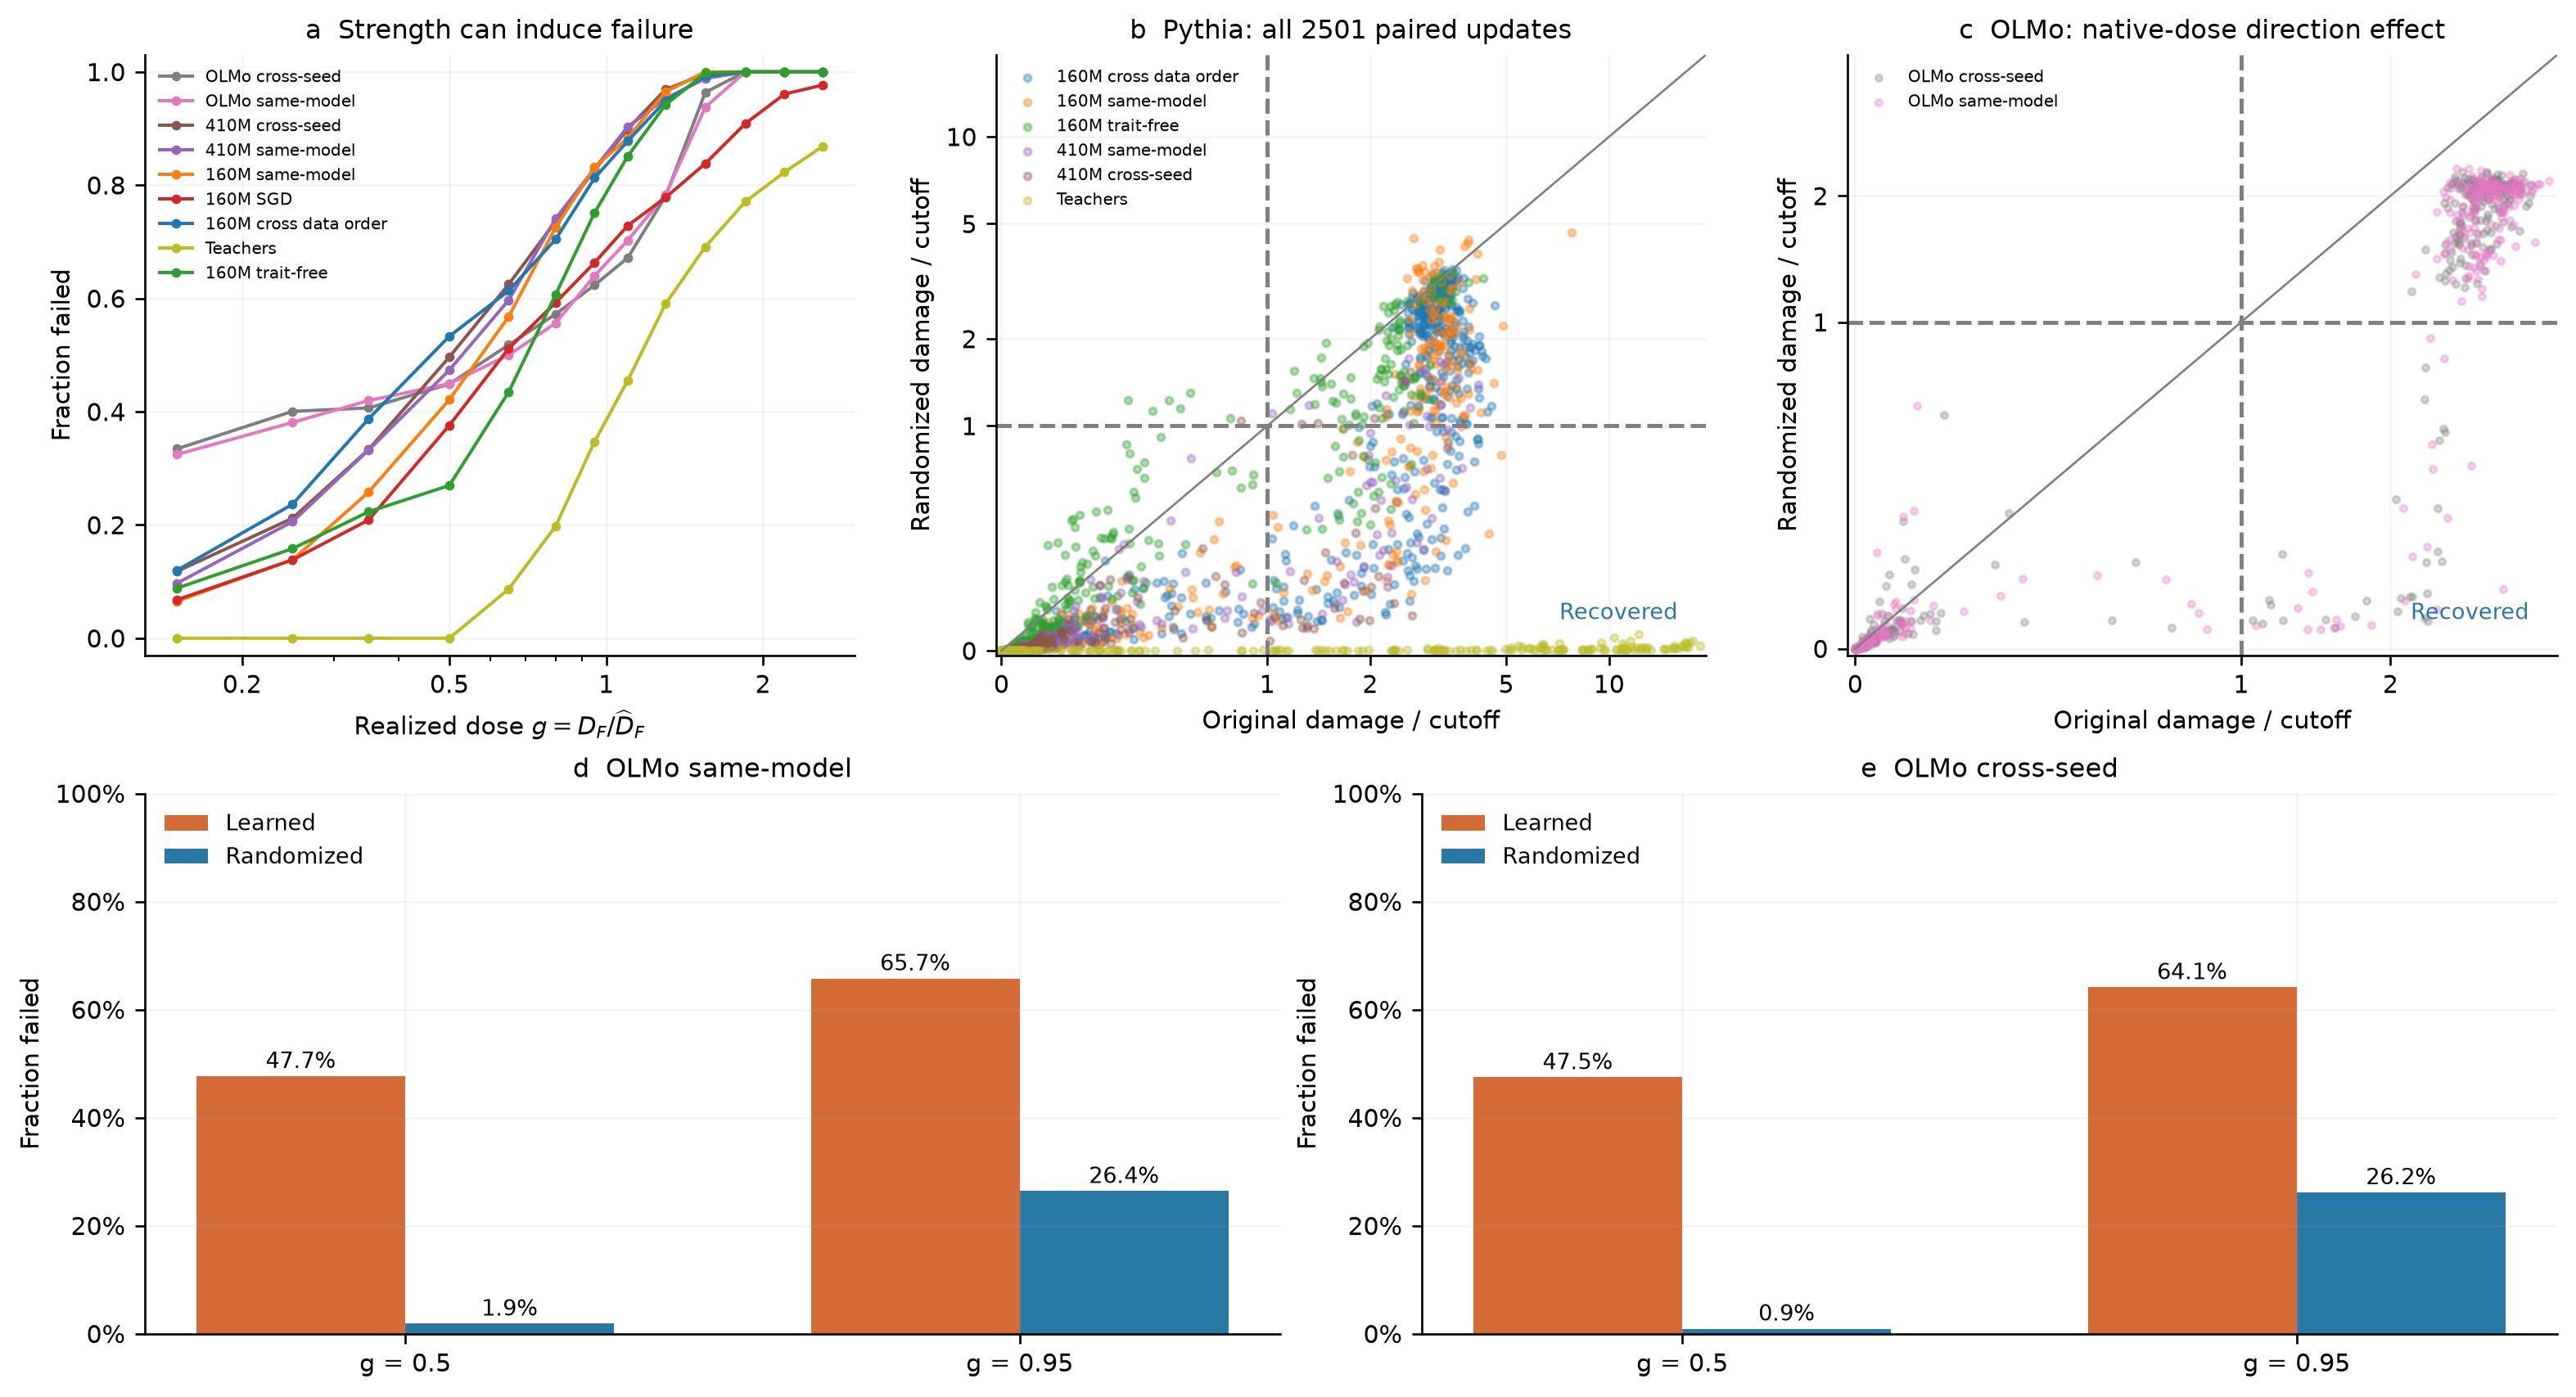

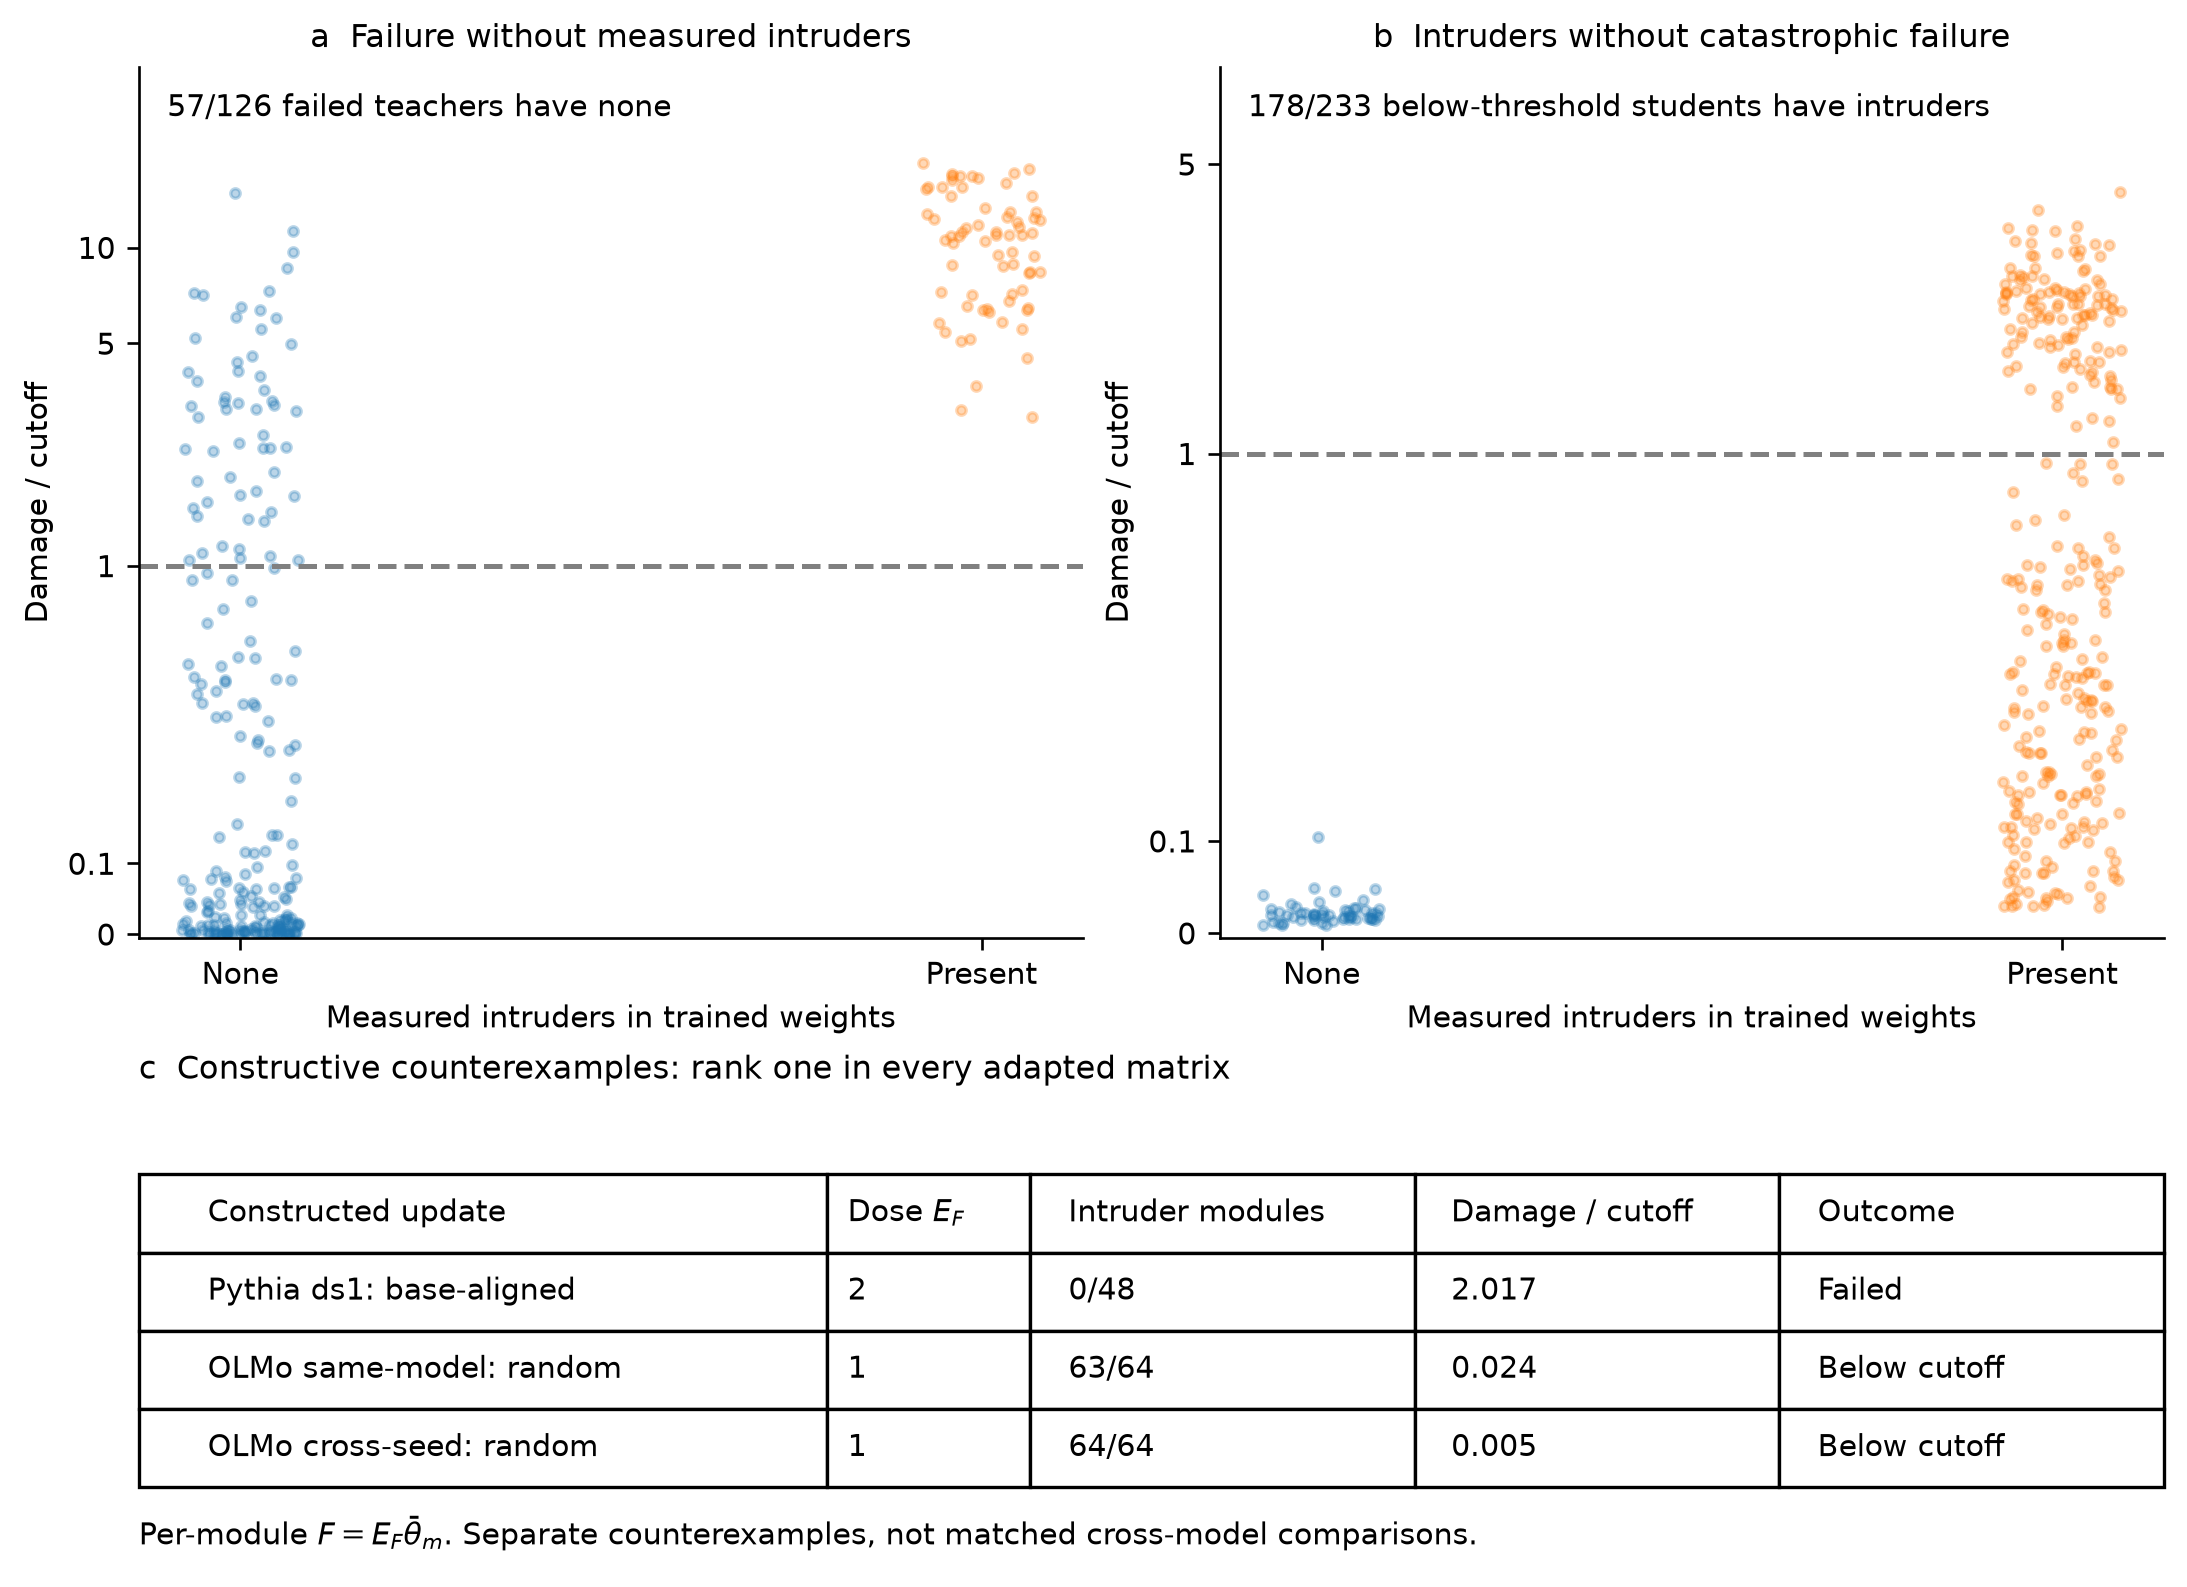

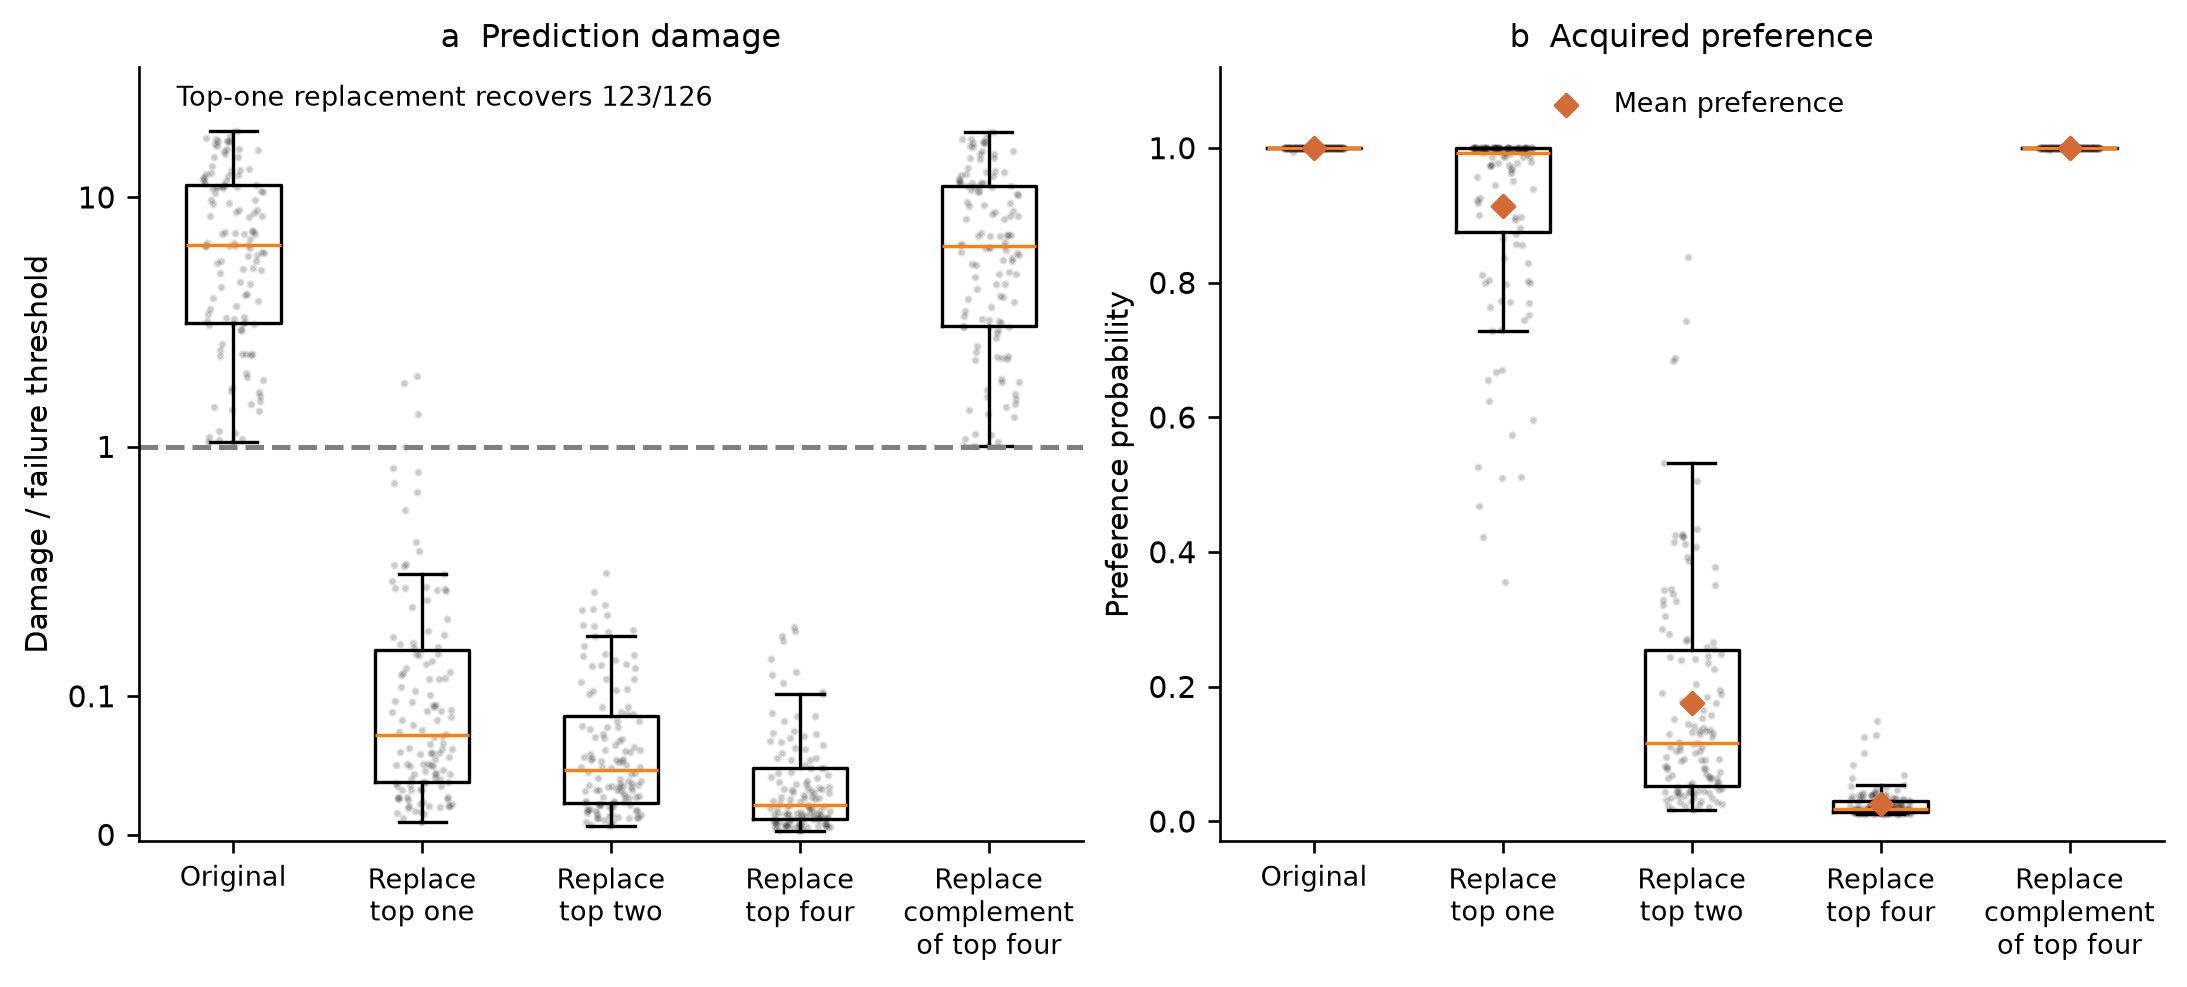

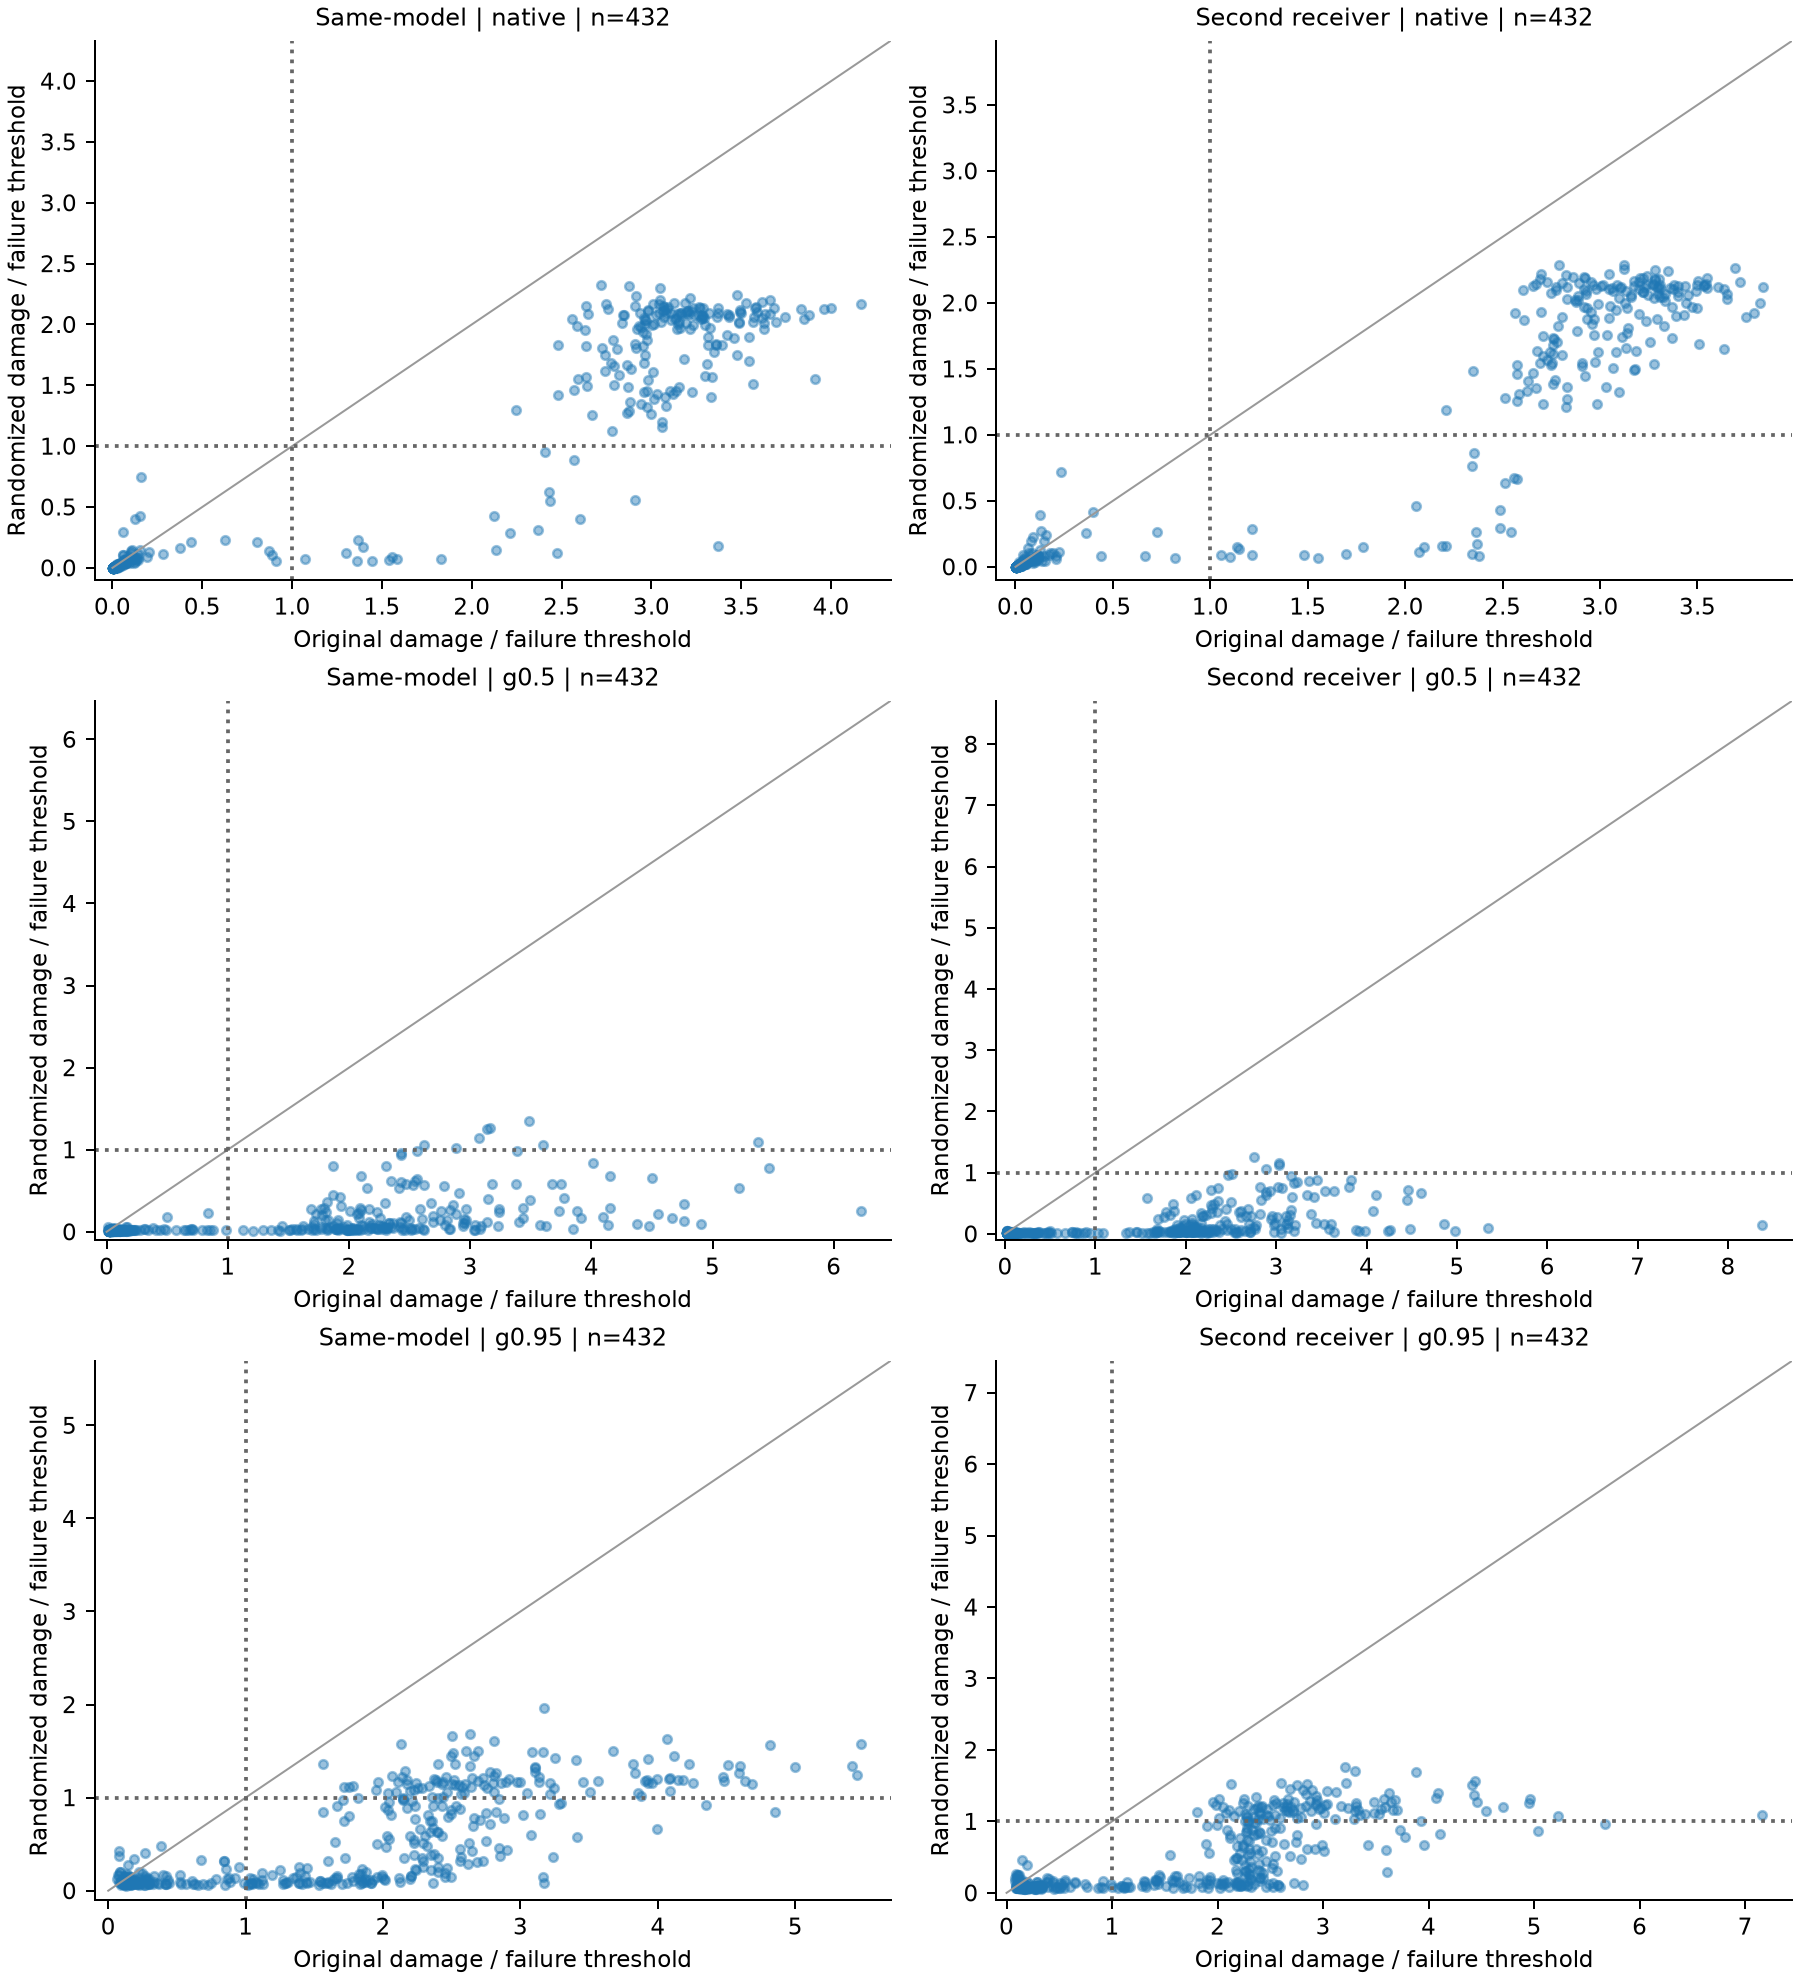

In [11]:
figures = root / 'docs/results/figures/iclr_20260909'
for name in ['fig04_dose_direction', 'fig05_intruders', 'fig06_trait_collapse', 'figS_olmo_direction']:
    display(Image(filename=str(figures / (name + '.png'))))


<!-- END VERIFIED DIRECTION ANALYSIS 20260914 -->

# Paper figures — *Hyperparameters Can Predetermine Where LoRA Starts Forgetting: Update Dose and Direction Content*

Companion to `docs/results/collapse_two_factor_iclr.md` (v10, 2026-09-01: Table 3d composition closure audit; v9: same-estimator teacher row at matched support in table3a; v8: table3b gains lr-normalized exponent columns; v7 2026-08-31: Figure 12a rebuilt on the census, six arms, valid runs; v6 2026-08-30: direction-family
sync — census / selector / prior-work-scan additions, stale quotes rewritten in place; the
notebook runs in the paper's narrative order). Every item is built as an executed cell from
the dated artifacts under `{output_root}/analysis/` and from run-dir records — never from
session memory. Each section states the paper section it serves and its construction. The
ANCHORED unigram cut is the operative dead label throughout (`probe_io.anchored_dead_cut`;
declared KL > 4.0 appears only as a stated comparison). **CE-primary convention (Angela,
2026-08-27)**: the displayed readout is ΔCE = ce_run − ce_base on pp1's realized tokens —
the coordinate in which the unigram bar is exact — with the distributional Pile-KL twin
computed and stored alongside it everywhere (they agree to ≤0.21 nats, zero label churn).
Loaders prefer the `*_ce` artifacts (queues ce-wave1/ce-wave2, 08-27) per arm and fall back
to legacy KL-only artifacts where a re-run has not landed, labeling axes accordingly (the
frozen/moved component splices of Fig 8c were not re-run and stay KL). **Terminology
(registry, 2026-08-28)**: the intervention is the **direction surgery** (legacy "position
surgery"; artifact names keep the legacy stem), the statistic the **direction effect**
(legacy "toxicity"); every surgery variant is a *selector* (which singular-vector pairs are
replaced) × a *rotation amount t*. Tables are color-graded pandas tables (notebook-native),
with CSVs in `paper_figures/` for typesetting; figure PNGs are written there too.

| item | paper § | content |
|---|---|---|
| Fig 1 | §4.1 | endpoint ΔCE vs K/K* per arm (own exponents, own K*, own probe pool): median curves with 95% CI bands, solid alive / dashed dead; teachers ep20 + ep5 as their own curves |
| Fig 2 | §4.2 (size), §4.6 | λ-rescaling: all 230 CE-primary curves + kill/revive hysteresis |
| Fig 3 | §4.2 (size), §4.6 | training-time clamp: survival vs ceiling; matched-final-size comparison |
| Table 1 | §4.2 (direction) | direction surgery (Randomized): color-graded table, arm × singular-vector source × depth band |
| Fig 11 | §4.2 (direction) | census-scale healing: trained vs Randomized ΔCE, all six arms |
| Table 1b | §4.2 (direction) | selector endpoints: median ΔCE + revival % on dead runs, arm × selector |
| Fig 4 | §4.2 (direction) | rotation amount t: all-pairs progression + per-selector medians (strip, teachers) |
| Fig 5 | §4.2 (direction) | injection ladders: matched-F vs matched-σ; donor ladders at k=16 and k=32 |
| Table 2 | §4.2, §5.2 | ladder damage vs intruder counts, k × E color tables (the dissociation) |
| Fig 12 | §4.3 | direction-effect dispersion by arm + census validity / depth-independence |
| Fig 6 | §4.3 | λ-crossing: per-arm median curves with shaded 95% CIs + crossing summary |
| Fig 7 | §4.3, §4.4 | the dose map (colored by α; cross-data-order arm) + per-cell size→fate |
| Fig 8 | §4.4 | frozen/learned: share of full update norm; trait retention + Pile-KL box plots |
| Table 3 | §4.4 | boundary exponents (full grid + matched cells), free dose-map fits, thresholds |
| Fig 9 | §4.7 | two-curve figure (orig same-model) |
| Fig 10 | §4.7 | randomizing directions returns the trait to ≤ prior in every run |
| Fig 13 | §4.7 | single-direction separability on dead teachers: damage needs dir 1, trait rides dirs 1–2 |
| Fig 14 + Table 4 | §5.2 | supercritical vs subcritical revival; intruder counts by fate; s\* AUC table |
| Fig 15 + Table 5 | §4.4 | the structure of K\*: slice K\* by student base / teacher / trait incl. full-seed arms; sequential + partial R², per-arm free (b, c) |

Figure numbers 1–10 are historical and fixed; 11–14 were appended 2026-08-30 (15 on 2026-09-02), and because
the notebook runs in narrative order the appended numbers appear interleaved. The 08-26
λ-crossing extension campaign (`lambda-ext-crossing`) drained and is folded into Fig 6.
Dropped 08-26 (Angela): the spread splice (orig/top1/flat) figure — visually inconclusive;
artifacts remain in `spread_ladder_*.json`. The population-scale donor-potency sweep
(`donor_potency_ce_*`) is on disk but NOT claim-bearing (its fixed-size probe confounds
direction identity with dose–response position) and is deliberately not rendered. Paper
numbers are quoted from `collapse_claims_v2.md`; stats printed here are recomputed and
should agree up to the documented anchored/declared differences.


In [12]:
import glob as _glob, json, re, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from sklearn.metrics import roc_auc_score
warnings.filterwarnings('ignore')
pd.set_option('display.width', 160)

import subliminal_learning
from subliminal_learning.config import resolve_roots
REPO = Path(subliminal_learning.__file__).resolve().parents[2]
OUT, _ = resolve_roots(None, None)
A = OUT / 'analysis'
FIGDIR = A / 'paper_figures'; FIGDIR.mkdir(exist_ok=True)
from subliminal_learning.analysis import frames as aframes
from subliminal_learning.analysis.frames import parse_param_tag
from subliminal_learning.analysis.norms import load_adapter_norm_runs
from subliminal_learning.analysis.stats import interp_crossing
from subliminal_learning.coherence.probe_io import DEAD_KL_CUT, anchored_dead_cut, load_probe
def read_jsonl(p):
    return pd.DataFrame(aframes.read_jsonl(p))
def read_json(p):
    return json.loads(Path(p).read_text())
DCX = {k: anchored_dead_cut(OUT, k) for k in
       ('pythia-160m', 'pythia-160m-data-seed1', 'pythia-160m-weight-seed1',
        'pythia-160m-weight-seed2', 'pythia-410m', 'pythia-410m-seed1')}
# OLMo-1B (DataDecide) receivers sit on the dp1 (Dolma) anchor -- a different H_uni, never mixed with pp1.
DCX.update({k: anchored_dead_cut(OUT, k, pool='dp1') for k in
            ('DataDecide-dolma1_7-1B-seed-default', 'DataDecide-dolma1_7-1B-seed-large-aux-2')})
# Qwen2.5-1.5B (panda) sits on its own frozen pool (pp1t-qwen25) -- teacher sets 2026-09-14.
DCX['Qwen2.5-1.5B'] = anchored_dead_cut(OUT, 'Qwen2.5-1.5B', pool='pp1t-qwen25')
DC_ORIG, DC_DS1 = DCX['pythia-160m'], DCX['pythia-160m-data-seed1']
KL_LAB = 'pp1 ΔCE vs base (nats)'   # CE-primary display (2026-08-27); KL stored as twin
def pooled_terms(rd):
    """Pooled Frobenius dose of one run dir + its two components:
    total s*||B*A_final||, frozen s*||B*A_init||, learned s*||B*dA|| (all /||W0||, mean over modules).
    Slim-schema records lack the component fields -> NaN there."""
    an = json.loads((Path(rd)/'eval'/'adapter_norms.json').read_text())
    s_ = an['alpha']/an['rank']
    it = list(an['modules'].values() if isinstance(an['modules'], dict) else an['modules'])
    def _mean(key):
        vals = [s_*m_.get(key, np.nan)/m_['W0_fro'] for m_ in it]
        return float(np.nanmean(vals)) if np.isfinite(vals).any() else np.nan
    return _mean('B_Afinal_fro'), _mean('B_Ainit_fro'), _mean('B_dA_fro')
def pooled_dose(rd):
    return pooled_terms(rd)[0]
rngb = np.random.default_rng(0)
def med_ci(v, n=2000):
    v = np.asarray(v); meds = [np.median(rngb.choice(v, len(v), replace=True)) for _ in range(n)]
    return np.median(v), np.percentile(meds, 2.5), np.percentile(meds, 97.5)
print('output root:', OUT)
print('anchored cuts (operative; declared 4.0 = comparison):', {k: round(v, 3) for k, v in DCX.items()})

output root: /mnt/cold-1/soar-subliminal/angela/outputs
anchored cuts (operative; declared 4.0 = comparison): {'pythia-160m': 5.096, 'pythia-160m-data-seed1': 5.123, 'pythia-160m-weight-seed1': 5.055, 'pythia-160m-weight-seed2': 5.169, 'pythia-410m': 5.474, 'pythia-410m-seed1': 5.466, 'DataDecide-dolma1_7-1B-seed-default': 5.186, 'DataDecide-dolma1_7-1B-seed-large-aux-2': 5.189, 'Qwen2.5-1.5B': 5.802}


## Strip population loader (used by Figs 1, 3, 7, 8)

Row unit: one strip run (calibrated strip: orig-teacher numbers → ds1 receiver, ep20 grid,
all ftseeds). Per run: pp1 Pile-KL vs its own base (nats; = ΔCE on this pool), pooled
Frobenius dose dw_fro, its frozen (s·B·A₀) and learned (s·B·ΔA) components, and the
hyperparameters. Selection: finite KL and dose only.

In [13]:
strip_list = OUT/'students/dog/pythia-160m-data-seed1/teacher-pythia-160m/ep2_lr5e-4_r32a64_tseed1/ex10-20_prefix_n100k'
# Population of record = the non-adaptive 8x7x9 grid (504 cells x ftseed{1,2}); the tree also hosts
# bandext/focus/band cells, ftseed3-5 ensembles and 901+ seeds, which are NOT part of this arm.
CDO_POP = {f"{r['tag']}/ftseed{int(r['seed'])}"
           for r in json.loads((A/'nonadaptive_8x7_harvest.json').read_text())}
rows = []
for an_p in strip_list.glob('ep20_*/ftseed*/eval/adapter_norms.json'):
    rd = an_p.parent.parent
    if f'{rd.parent.name}/{rd.name}' not in CDO_POP: continue
    try:
        dw, dwf, dwm = pooled_terms(rd)
        pp_ = json.loads((rd/'eval'/'pile_probe.json').read_text())
    except FileNotFoundError:
        continue
    kl = pp_.get('kl_base_student'); dce = pp_.get('delta_ce')
    if dce is None or kl is None or not np.isfinite(dce) or not np.isfinite(dw): continue
    pt = parse_param_tag(rd.parent.name)
    rows.append(dict(tag=rd.parent.name, seed=rd.name, dw=dw, dw_frozen=dwf, dw_learned=dwm,
                     dce=dce, kl=kl, lr=pt['lr'], rank=pt['rank'], alpha=pt['alpha']))
sd = pd.DataFrame(rows)
sd['dead'] = sd.dce > DC_DS1
print(f"CE-primary: labels/plots on delta_ce; KL twin max|kl-dce| = {float((sd.kl-sd.dce).abs().max()):.3f} nats")
print(f"cross-data-order runs (designed population {len(CDO_POP)}) with norms+probe: {len(sd)}  (healthy {int((~sd.dead).sum())}, collapsed {int(sd.dead.sum())})")
print(f"component coverage (full two-term schema): {int(np.isfinite(sd.dw_frozen).sum())}/{len(sd)}")

CE-primary: labels/plots on delta_ce; KL twin max|kl-dce| = 0.209 nats
cross-data-order runs (designed population 1008) with norms+probe: 932  (healthy 544, collapsed 388)
component coverage (full two-term schema): 278/932


## Figure 1 — §4.1 *One boundary picture per arm: endpoint ΔCE against K/K\**

**Construction.** One curve per experimental arm.  x = K/K\* with `K = lr·α^b·r^c` on the
**arm's own** fitted exponents (`cl.fit_collapse_law`, seed-level logit, cluster-robust by cell)
and the arm's own logistic-50 % K\* (`cl.kstar_logistic`) — the same estimators and the same
populations as Table 3a, so the exponents printed below are the ones the paper quotes.  y =
endpoint ΔCE over the receiver's base on **the arm's own probe pool** (pp1 = Pile for the Pythia
arms, dp1 = Dolma for the OLMo arms; CE-primary).  Each run is one point (not drawn); runs are
binned in log10(K/K\*) (12 equal-width bins over the arm's own range, ≥ 5 runs per bin), the
solid/dashed line is the per-bin **median** ΔCE and the light band its bootstrap 95 % CI (2,000
resamples).  The line is **solid where the bin median sits below the arm's anchored cut (alive)
and dashed once it exceeds it (dead)**; a bin whose median is +∞ (a majority of diverged /
non-finite-adapter runs, dead by definition) is drawn as an open triangle at the top of the
axis; the y axis is symlog (linear below 0.01 nats) so the near-zero ΔCE of the smallest-lr
teachers reads as ~0 rather than as a clipped floor; every arm's cut is its receiver's own Δ_cross (5.06–5.47
nats on pp1, 5.19 on dp1), drawn as one grey band.  Row unit of the table: one arm.  Arms:
cross data order (strip: orig teacher → ds1, the designed 504 × 2 population), orig same-model,
trait-free (untuned-base numbers → ds1), SGD (its own coordinate, c ≈ −b), the two Pythia-410m
arms (nonadaptive lattice, ftseed 1), and the two OLMo-1B arms (the 432-cell OLMo nonadaptive
set: 6 lr × 9 ranks × 8 α, ep10, ftseed 1).  The teacher stage enters as two
curves, the **ep20** and **ep5** slices of the dog|orig wide tree restricted to the **teacher
nonadaptive set** — the 504-cell strip lattice (9 lr {5e-6 … 2e-3} × 7 α {4 … 256} × 8 ranks
{1 … 128}) at that epoch, ftseed 1; the ~87 refinement cells per epoch on off-lattice lr and α
values are excluded — so that each curve has a single-number K\* (the teacher K\* is budget-dependent,
`collapse_teachers` §3); where a teacher slice's logit is near-separable the exponents come from the
ridge-stabilised GLM of Table 3a's teacher rows (point ratios, no CI; the table's `estimator`
column says which).  CSV: `fig01_arms.csv` (per-arm fit, cut, n) and
`fig01_curves.csv` (per-bin medians and CIs).


,pool,estimator,runs,cells,dead,b,b_lo,b_hi,c,c_lo,c_hi,kstar,cut,krel_min,krel_max,first_dead_bin_krel
arm,,,,,,,,,,,,,,,,
cross data order,pp1,MLE (cluster-robust CI),1008,504,464,0.659,0.60,0.71,-0.164,-0.21,-0.11,8.79e-04,5.12,0.006,88.0,1.13
orig same-model,pp1,MLE (cluster-robust CI),637,554,322,0.639,0.59,0.69,-0.149,-0.20,-0.10,8.00e-04,5.10,0.007,143.2,1.52
trait-free,pp1,MLE (cluster-robust CI),651,527,242,0.667,0.62,0.71,-0.045,-0.09,-0.00,2.15e-03,5.12,0.005,82.8,1.96
SGD,pp1,MLE (cluster-robust CI),862,862,381,0.626,0.58,0.67,-0.661,-0.70,-0.62,1.01e-01,5.10,0.002,316.8,1.31
410M same-model,pp1,MLE (cluster-robust CI),462,462,175,0.608,0.55,0.66,-0.052,-0.10,0.00,1.18e-03,5.47,0.008,15.5,1.70
410M cross-seed,pp1,MLE (cluster-robust CI),459,459,177,0.617,0.55,0.68,-0.041,-0.09,0.01,1.17e-03,5.47,0.008,16.0,1.80
OLMo-1B same-model,dp1,MLE (cluster-robust CI),432,432,203,0.499,0.47,0.53,-0.059,-0.08,-0.04,4.33e-03,5.19,0.033,26.0,1.20
OLMo-1B cross-seed 2,dp1,MLE (cluster-robust CI),432,432,208,0.507,0.49,0.52,-0.038,-0.05,-0.03,4.53e-03,5.19,0.036,26.1,1.23
teachers ep20 (dog|orig),pp1,MLE (cluster-robust CI),616,616,250,0.753,0.51,1.00,-0.147,-0.35,0.06,4.00e-03,5.10,0.002,32.6,0.36


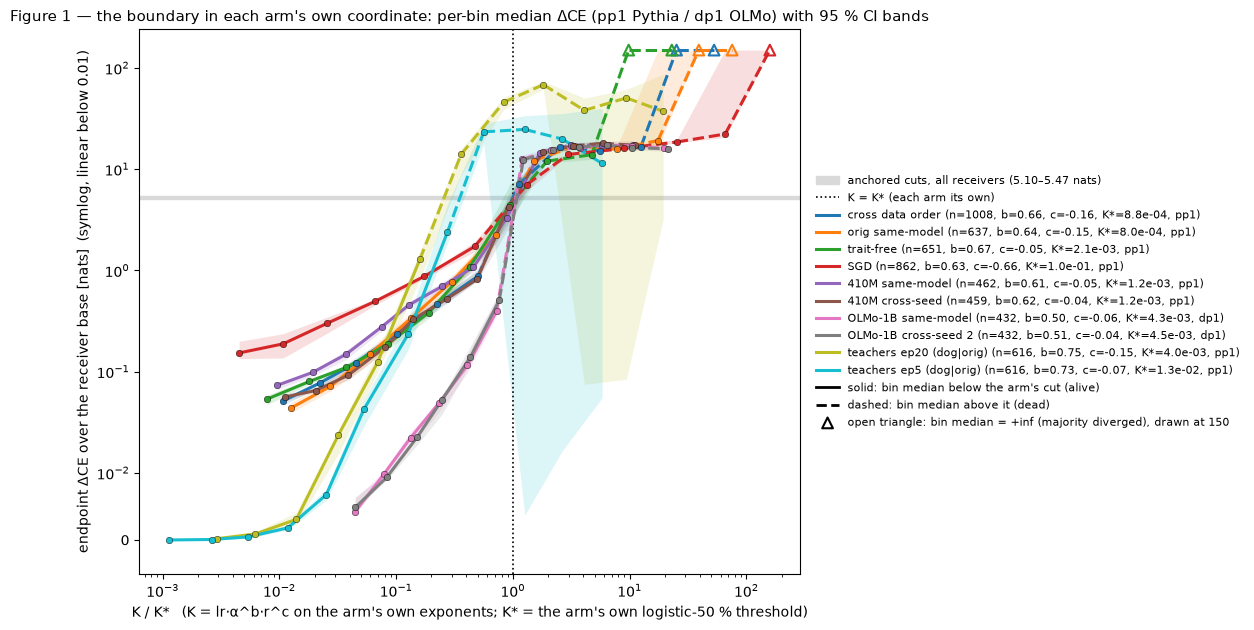

Read: every arm is graded below its own K* and jumps to the 10-20 nat plateau within a factor ~2 above it; the
arms differ in where K* sits (Table 3c) and in their exponents (Table 3a), not in the shape of the crossing.


In [14]:
from subliminal_learning.stats import collapse_law as cl
F1_LAT_LR = {5e-6, 1e-5, 2e-5, 5e-5, 1e-4, 2e-4, 5e-4, 1e-3, 2e-3}      # Pythia nonadaptive lr rungs
F1_ARMS = {   # arm -> (tree, receiver anchor key, leaf glob, pool label, population filter)
    'cross data order': ('students/dog/pythia-160m-data-seed1/teacher-pythia-160m/ep2_lr5e-4_r32a64_tseed1/ex10-20_prefix_n100k',
                         'pythia-160m-data-seed1', 'ep20_*/ftseed*', 'pp1', 'cdo'),
    'orig same-model': ('students/dog/pythia-160m/teacher-pythia-160m/ep2_lr5e-4_r32a64_tseed1/ex10-20_prefix_n100k',
                        'pythia-160m', 'ep20_*/ftseed*', 'pp1', None),
    'trait-free': ('students/controls/base/pythia-160m-data-seed1/teacher-pythia-160m/ex10-20_prefix_n100k',
                   'pythia-160m-data-seed1', 'ep20_*/ftseed*', 'pp1', None),
    'SGD': ('students/sgd/dog/pythia-160m/teacher-pythia-160m/ep2_lr5e-4_r32a64_tseed1/ex10-20_prefix_n100k',
            'pythia-160m', 'ep20_*/ftseed*', 'pp1', None),
    '410M same-model': ('students/dog/pythia-410m/teacher-pythia-410m/ep2_lr5e-4_r32a64_tseed1/ex10-20_prefix_n100k',
                        'pythia-410m', 'ep20_*/ftseed1', 'pp1', 'lattice'),
    '410M cross-seed': ('students/dog/pythia-410m-seed1/teacher-pythia-410m/ep2_lr5e-4_r32a64_tseed1/ex10-20_prefix_n100k',
                        'pythia-410m-seed1', 'ep20_*/ftseed1', 'pp1', 'lattice'),
    'OLMo-1B same-model': ('students/elephant/DataDecide-dolma1_7-1B-seed-default/teacher-DataDecide-dolma1_7-1B-seed-default/ep10_lr5e-4_r64a128_tseed0/ex10-20_prefix_n100k',
                           'DataDecide-dolma1_7-1B-seed-default', 'ep10_*/ftseed1', 'dp1', None),
    'OLMo-1B cross-seed 2': ('students/elephant/DataDecide-dolma1_7-1B-seed-large-aux-2/teacher-DataDecide-dolma1_7-1B-seed-default/ep10_lr5e-4_r64a128_tseed0/ex10-20_prefix_n100k',
                             'DataDecide-dolma1_7-1B-seed-large-aux-2', 'ep10_*/ftseed1', 'dp1', None),
    # teacher stage: the dog|orig wide tree (the one identifiability-adequate teacher support), one epoch slice per
    # curve so that K* is a single number (teacher K* is budget-dependent -- collapse_teachers section 3)
    'teachers ep20 (dog|orig)': ('teachers/dog/pythia-160m', 'pythia-160m', 'ep20_*/ftseed1', 'pp1', 'lattice'),
    'teachers ep5 (dog|orig)': ('teachers/dog/pythia-160m', 'pythia-160m', 'ep5_*/ftseed1', 'pp1', 'lattice'),
}
def _f1_ridge_bc(df):
    # near-separable teacher logit: ridge-stabilised GLM (as Table 3a's teacher rows); point ratios only
    X = sm.add_constant(np.c_[np.log(df.lr), np.log(df.alpha), np.log(df['rank'])])
    r = sm.GLM(df.collapsed.to_numpy(), X, family=sm.families.Binomial()).fit_regularized(alpha=1e-3, L1_wt=0.0)
    pr = np.asarray(r.params); return pr[2] / pr[1], pr[3] / pr[1]
def _f1_keep(pt, pop, leaf):
    if pop == 'cdo':
        return leaf in CDO_POP
    if pop == 'lattice':
        return (any(abs(pt['lr'] - x) / x < 1e-9 for x in F1_LAT_LR) and pt['alpha'] in (4, 8, 16, 32, 64, 128, 256)
                and pt['rank'] in (1, 2, 4, 8, 16, 32, 64, 128))
    return True
def _f1_load(rel, base, pat, pop):
    cut, rows = DCX[base], []
    for pp_p in (OUT / rel).glob(pat + '/eval/pile_probe.json'):
        rd = pp_p.parent.parent
        try:
            pp = json.loads(pp_p.read_text())
        except Exception:
            continue
        dce = pp.get('delta_ce')
        pt = parse_param_tag(rd.parent.name)
        if not _f1_keep(pt, pop, f'{rd.parent.name}/{rd.name}'):
            continue
        if dce is None or not np.isfinite(dce):
            dce = np.inf if (rd / 'train_diverged.json').exists() or pp.get('nonfinite_adapter') else np.nan
        if not np.isfinite(dce) and not np.isinf(dce):
            continue
        rows.append(dict(student_tag=rd.parent.name, seed=rd.name, lr=float(pt['lr']), rank=int(pt['rank']),
                         alpha=int(pt['alpha']), dce=dce, collapsed=int(dce > cut)))
    return pd.DataFrame(rows), cut
F1, f1_rows, f1_curves = {}, [], []
NB1 = 12
for arm, (rel, base, pat, pool, pop) in F1_ARMS.items():
    df, cut = _f1_load(rel, base, pat, pop)
    if df.empty or df.collapsed.nunique() < 2:
        print(f'{arm}: no usable population -- skipped'); continue
    est = 'MLE (cluster-robust CI)'
    try:
        fit = cl.fit_collapse_law(df)
        b_, c_, bci, cci = fit.b, fit.c, fit.b_ci, fit.c_ci
        if not (np.isfinite(b_) and np.isfinite(c_) and abs(b_) < 5 and abs(c_) < 5):
            raise ValueError('non-finite or runaway ratios')
    except Exception:
        b_, c_ = _f1_ridge_bc(df); bci = cci = (np.nan, np.nan); est = 'ridge GLM (near-separable; no CI)'
    fit = type('F', (), dict(b=b_, c=c_, b_ci=bci, c_ci=cci))()
    ks = cl.kstar_logistic(df, fit.b, fit.c)['kstar']
    df['krel'] = cl.K_of(df.lr, df.alpha, df['rank'], b=fit.b, c=fit.c) / ks
    df['lk'] = np.log10(df.krel)
    edges = np.linspace(df.lk.min(), df.lk.max() + 1e-9, NB1 + 1)
    df['bin'] = np.clip(np.digitize(df.lk, edges) - 1, 0, NB1 - 1)
    pts = []
    for b_, g in df.groupby('bin'):
        if len(g) < 5: continue
        y = g.dce.to_numpy()          # may hold +inf (diverged / non-finite adapter = dead)
        m, lo, hi = med_ci(np.where(np.isinf(y), 1e6, y))   # bootstrap on a finite sentinel, so the CI is defined
        m, lo, hi = [np.inf if v >= 1e5 else v for v in (m, lo, hi)]   # sentinel back to +inf
        pts.append(dict(arm=arm, bin=int(b_), krel=float(10 ** g.lk.median()), n=len(g), n_inf=int(np.isinf(y).sum()),
                        dce_med=m, dce_lo=lo, dce_hi=hi, frac_dead=float(g.collapsed.mean()), dead=bool(m > cut)))
    cur = pd.DataFrame(pts).sort_values('krel')
    F1[arm] = dict(df=df, fit=fit, kstar=ks, cut=cut, cur=cur, pool=pool)
    f1_curves.append(cur)
    xk = cur[cur.dead].krel
    f1_rows.append(dict(arm=arm, pool=pool, estimator=est, runs=len(df), cells=df.student_tag.nunique(), dead=int(df.collapsed.sum()),
                        b=fit.b, b_lo=fit.b_ci[0], b_hi=fit.b_ci[1], c=fit.c, c_lo=fit.c_ci[0], c_hi=fit.c_ci[1],
                        kstar=ks, cut=cut, krel_min=float(df.krel.min()), krel_max=float(df.krel.max()),
                        first_dead_bin_krel=float(xk.min()) if len(xk) else np.nan))
f1t = pd.DataFrame(f1_rows).set_index('arm')
f1t.to_csv(FIGDIR / 'fig01_arms.csv'); pd.concat(f1_curves).to_csv(FIGDIR / 'fig01_curves.csv', index=False)
display(f1t.style.format({'b': '{:.3f}', 'b_lo': '{:.2f}', 'b_hi': '{:.2f}', 'c': '{:.3f}', 'c_lo': '{:.2f}', 'c_hi': '{:.2f}',
                          'kstar': '{:.2e}', 'cut': '{:.2f}', 'krel_min': '{:.3f}', 'krel_max': '{:.1f}', 'first_dead_bin_krel': '{:.2f}'}, na_rep='—'))

fig, ax = plt.subplots(figsize=(12, 6.4))
cmap = plt.get_cmap('tab10')
cuts = [v['cut'] for v in F1.values()]
Y_INF = 150.0   # bins whose median is +inf (majority diverged) are drawn as open triangles at this ceiling
LIN = 1e-2      # symlog: linear below this so near-zero dCE (teachers at tiny lr) reads as ~0, not as a floor
ax.axhspan(min(cuts), max(cuts), color='0.85', zorder=0, label=f'anchored cuts, all receivers ({min(cuts):.2f}–{max(cuts):.2f} nats)')
ax.axvline(1.0, color='k', ls=':', lw=1.2, label='K = K* (each arm its own)')
for i, (arm, v) in enumerate(F1.items()):
    cur, col = v['cur'], cmap(i % 10)
    if cur.empty: continue
    x, y, dd = cur.krel.to_numpy(), cur.dce_med.to_numpy(), cur.dead.to_numpy()
    inf_ = np.isinf(y)
    yv = np.where(inf_, Y_INF, y); lo_ = np.minimum(np.nan_to_num(cur.dce_lo.to_numpy(), posinf=Y_INF), Y_INF)
    hi_ = np.minimum(np.nan_to_num(cur.dce_hi.to_numpy(), posinf=Y_INF), Y_INF)
    ax.fill_between(x, lo_, hi_, color=col, alpha=0.15, lw=0)
    for j in range(len(x) - 1):
        ax.plot(x[j:j + 2], yv[j:j + 2], ls='--' if (dd[j] or dd[j + 1]) else '-', color=col, lw=2.2)
    ax.scatter(x[~inf_], yv[~inf_], s=22, color=col, edgecolor='k', linewidth=0.3, zorder=4)
    if inf_.any():
        ax.scatter(x[inf_], yv[inf_], s=60, marker='^', facecolor='none', edgecolor=col, linewidth=1.5, zorder=5)
    ax.plot([], [], '-', color=col, lw=2.2,
            label=f"{arm} (n={len(v['df'])}, b={v['fit'].b:.2f}, c={v['fit'].c:.2f}, K*={v['kstar']:.1e}, {v['pool']})")
ax.plot([], [], '-', color='k', lw=2, label='solid: bin median below the arm\'s cut (alive)')
ax.plot([], [], '--', color='k', lw=2, label='dashed: bin median above it (dead)')
ax.scatter([], [], s=60, marker='^', facecolor='none', edgecolor='k', linewidth=1.5, label=f'open triangle: bin median = +inf (majority diverged), drawn at {Y_INF:g}')
ax.set_xscale('log'); ax.set_yscale('symlog', linthresh=LIN, linscale=0.6)
ax.set_ylim(-LIN / 2, Y_INF * 1.6)
ax.set_xlabel('K / K*   (K = lr·α^b·r^c on the arm\'s own exponents; K* = the arm\'s own logistic-50 % threshold)')
ax.set_ylabel(f'endpoint ΔCE over the receiver base [nats]  (symlog, linear below {LIN:g})')
ax.set_title('Figure 1 — the boundary in each arm\'s own coordinate: per-bin median ΔCE (pp1 Pythia / dp1 OLMo) with 95 % CI bands', fontsize=10.5)
ax.legend(fontsize=8, frameon=False, loc='center left', bbox_to_anchor=(1.01, 0.5))
plt.tight_layout(); fig.savefig(FIGDIR / 'fig01_kk_vs_dce_all_arms.png', dpi=180, bbox_inches='tight'); plt.show()
print('Read: every arm is graded below its own K* and jumps to the 10-20 nat plateau within a factor ~2 above it; the')
print('arms differ in where K* sits (Table 3c) and in their exponents (Table 3a), not in the shape of the crossing.')


### Figure 1 companion — the teacher boundary at each epoch (dog|orig, teacher nonadaptive set)

**Construction.** Row unit: one teacher epoch budget (steps = 3 × epochs), epochs {3, 5, 7, 10, 15, 20}. Population: the dog|orig
teacher tree restricted to the 504-cell teacher nonadaptive set (9 lr {5e-6 … 2e-3} × 7 α {4 … 256}
× 8 ranks {1 … 128}), ftseed 1, anchored pp1 label (Δ_cross of pythia-160m). ep5 and ep20 are complete
(504/504 since the 2026-09-14 fill); the other epochs lack the same 33 high-dose cells (lr 1e-3/2e-3 ×
α ≥ 64) plus 7 low-lr r = α cells, so `cells` < 504 there and their dead count is a lower bound on
the corner. Columns: `b`, `c` = the same seed-level cluster-robust logit as Figure 1
(`cl.fit_collapse_law`; `converged` = False means near-separation, ratios still reported); ep1 and ep2 are not fitted (16 and 56 dead cells, fully separable);
`kstar` = logistic-50 % K\* on the row's own exponents (`cl.kstar_logistic`) with its
misclassification rate `err`; `kstar_ref` = K\* re-placed on the epoch-pooled coordinate (the ep20
row's b, c) so the budget dependence of the threshold reads at fixed exponents;
`theta` = logistic-50 % crossing on the realised dose dw_fro (`cl.theta_dose`) with its AUC.
**Within-run comparison (orange):** the same 504 ep20 runs read at each epoch-boundary checkpoint
(checkpoint-3k, `{run}/eval/pile_kl_traj.json`) — one 20-epoch cosine schedule cut early rather than a run
whose schedule ends at that epoch; epochs with < 20 dead cells are not fitted. CSVs: `fig01b_teacher_epochs.csv`,
`fig01b_teacher_within_run_ckpts.csv`.

,steps,cells,dead,b,b_lo,b_hi,c,c_lo,c_hi,converged,kstar,err,theta,theta_auc,dose_n,kstar_ref
epochs,,,,,,,,,,,,,,,,
3,9,464,88,0.774,0.74,0.81,-0.074,-0.10,-0.05,True,7.15e-03,0.009,0.0149,0.973,464,4.30e-03
5,15,504,165,0.714,0.67,0.76,-0.062,-0.10,-0.02,True,3.37e-03,0.012,0.0119,0.975,504,2.39e-03
7,21,464,159,0.657,0.62,0.69,-0.063,-0.09,-0.03,True,1.91e-03,0.013,0.0110,0.968,464,1.67e-03
10,30,464,185,0.711,0.66,0.76,-0.091,-0.13,-0.05,True,1.53e-03,0.017,0.0103,0.971,464,1.17e-03
15,45,464,201,0.684,0.61,0.75,-0.142,-0.18,-0.10,True,9.71e-04,0.015,0.0109,0.972,464,9.31e-04
20,60,504,249,0.657,0.61,0.71,-0.121,-0.16,-0.09,True,7.56e-04,0.016,0.0106,0.970,504,7.56e-04


,steps,cells,dead,b,b_lo,b_hi,c,c_lo,c_hi,converged,kstar,kstar_ref
epochs,,,,,,,,,,,,
1,3,504,39,0.856,0.86,0.86,-0.057,-0.06,-0.06,False,5.33e-02,1.75e-02
2,6,504,121,0.755,0.71,0.80,-0.063,-0.09,-0.04,True,6.82e-03,4.30e-03
3,9,504,166,0.726,0.68,0.77,-0.070,-0.11,-0.03,True,3.39e-03,2.36e-03
4,12,504,193,0.665,0.64,0.69,-0.057,-0.08,-0.03,True,1.96e-03,1.65e-03
5,15,504,213,0.690,0.65,0.73,-0.103,-0.14,-0.07,True,1.48e-03,1.26e-03
6,18,504,222,0.719,0.67,0.77,-0.078,-0.11,-0.05,True,1.54e-03,1.12e-03
7,21,504,229,0.718,0.66,0.78,-0.138,-0.18,-0.10,True,1.20e-03,1.01e-03
8,24,504,235,0.680,0.61,0.74,-0.143,-0.18,-0.10,True,9.50e-04,9.28e-04
9,27,504,242,0.670,0.61,0.73,-0.126,-0.17,-0.08,True,8.62e-04,8.36e-04


separate runs (trained to E epochs) vs within-run checkpoint at epoch E of the 20-epoch schedule:
        dead_separate  b_separate  c_separate  kstar_separate  dead_within  b_within  c_within  kstar_within
epochs                                                                                                      
3                  88      0.7740     -0.0737          0.0072          166    0.7256   -0.0701        0.0034
5                 165      0.7144     -0.0623          0.0034          213    0.6901   -0.1035        0.0015
7                 159      0.6571     -0.0632          0.0019          229    0.7177   -0.1377        0.0012
10                185      0.7110     -0.0910          0.0015          244    0.6530   -0.1235        0.0008
15                201      0.6838     -0.1418          0.0010          249    0.6569   -0.1212        0.0008
20                249      0.6569     -0.1212          0.0008          249    0.6569   -0.1212        0.0008


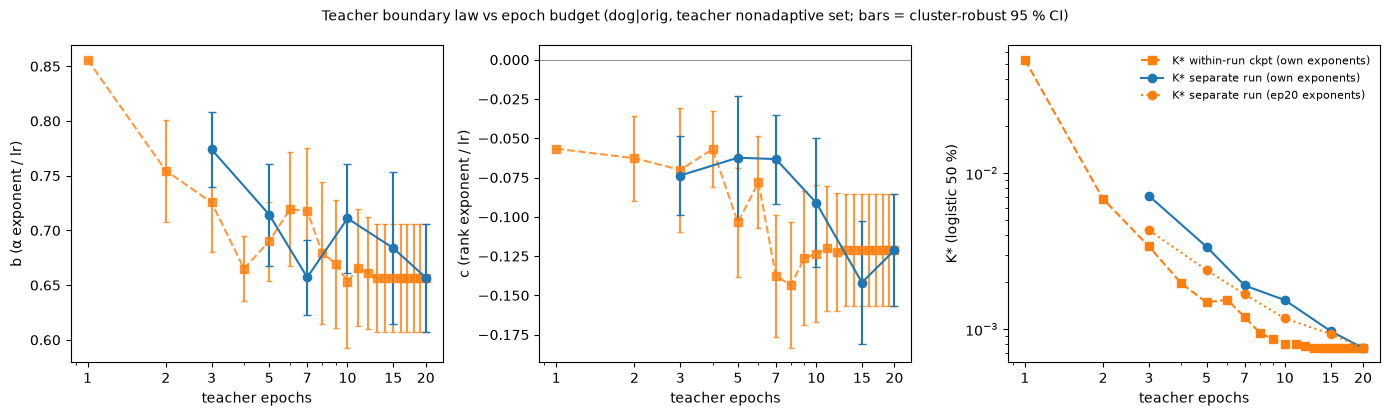

K* (ep20 exponents) vs steps: log-log slope -0.91 over 6 epoch budgets


In [15]:
from subliminal_learning.param_tags import is_canonical_tag
# Figure 1 companion: teacher boundary fit + threshold per epoch on the teacher nonadaptive set
T_EPOCHS = [3, 5, 7, 10, 15, 20]   # ep1/ep2 not fitted: too few dead cells (16 / 56), fully separable
_tcut = DCX['pythia-160m']
def _tep_load(ep):
    rows = []
    for pp_p in (OUT / 'teachers/dog/pythia-160m').glob(f'ep{ep}_*/ftseed1/eval/pile_probe.json'):
        rd = pp_p.parent.parent
        if not is_canonical_tag(rd.parent.name):
            continue  # SGD (`_sgd`) / noeos / early-stop arm teachers share this tree (2026-09-15 guard)
        pt = parse_param_tag(rd.parent.name)
        if not _f1_keep(pt, 'lattice', None):
            continue
        pp = json.loads(pp_p.read_text())
        dce = pp.get('delta_ce')
        if dce is None or not np.isfinite(dce):
            dce = np.inf if (rd / 'train_diverged.json').exists() or pp.get('nonfinite_adapter') else np.nan
        if not np.isfinite(dce) and not np.isinf(dce):
            continue
        try:
            dw = pooled_dose(rd)
        except Exception:
            dw = np.nan
        rows.append(dict(student_tag=rd.parent.name, lr=float(pt['lr']), rank=int(pt['rank']), alpha=int(pt['alpha']),
                         dce=dce, dw_fro=dw, collapsed=int(dce > _tcut)))
    return pd.DataFrame(rows)
TEP = {ep: _tep_load(ep) for ep in T_EPOCHS}
tep_rows = []
for ep, df in TEP.items():
    row = dict(epochs=ep, steps=3 * ep, cells=len(df), dead=int(df.collapsed.sum()))
    if df.collapsed.nunique() < 2:
        tep_rows.append(row); continue
    f = cl.fit_collapse_law(df)
    row.update(b=f.b, b_lo=f.b_ci[0], b_hi=f.b_ci[1], c=f.c, c_lo=f.c_ci[0], c_hi=f.c_ci[1],
               converged=f.converged)
    ks = cl.kstar_logistic(df, row['b'], row['c'])
    row.update(kstar=ks['kstar'], err=ks['err'])
    dd = df[np.isfinite(df.dw_fro) & (df.dw_fro > 0)]
    if dd.collapsed.nunique() == 2:
        th = cl.theta_dose(dd)
        row.update(theta=th['theta'], theta_auc=th['auc'], dose_n=len(dd))
    tep_rows.append(row)
tep = pd.DataFrame(tep_rows).set_index('epochs')
_ref = tep.loc[20]
tep['kstar_ref'] = [cl.kstar_logistic(TEP[ep], _ref.b, _ref.c)['kstar'] if TEP[ep].collapsed.nunique() == 2 else np.nan
                    for ep in tep.index]
tep.to_csv(FIGDIR / 'fig01b_teacher_epochs.csv')
display(tep.style.format({'b': '{:.3f}', 'b_lo': '{:.2f}', 'b_hi': '{:.2f}', 'c': '{:.3f}', 'c_lo': '{:.2f}', 'c_hi': '{:.2f}',
                          'kstar': '{:.2e}', 'kstar_ref': '{:.2e}', 'err': '{:.3f}', 'theta': '{:.4f}', 'theta_auc': '{:.3f}'},
                         na_rep='—')
        .set_caption('Teacher boundary per epoch — dog|orig, 504-cell teacher nonadaptive set, ftseed 1, anchored pp1 label'))
# Within-run checkpoints: the SAME 504 ep20 runs read at every epoch boundary (checkpoint-3k, k = 1..20;
# {run}/eval/pile_kl_traj.json, 2026-09-14) -- one 20-epoch cosine schedule cut early, vs a separate run
# trained to that epoch budget. Same anchored pp1 label and estimator; epochs with < 20 dead not fitted.
wr_rows = []
for ep in range(1, 21):
    rows_ = []
    for pp_p in (OUT / 'teachers/dog/pythia-160m').glob('ep20_*/ftseed1/eval/pile_kl_traj.json'):
        tag_ = pp_p.parent.parent.parent.name
        if not is_canonical_tag(tag_):
            continue  # same guard for the within-run checkpoint records
        pt = parse_param_tag(tag_)
        if not _f1_keep(pt, 'lattice', None):
            continue
        pts = [q for q in json.loads(pp_p.read_text())['points'] if q['step'] == 3 * ep and q['checkpoint'] != 'checkpoints']
        if not pts:
            continue
        v = pts[0].get('delta_ce')
        v = np.inf if (pts[0].get('nonfinite') or v is None or not np.isfinite(v)) else v
        rows_.append(dict(student_tag=tag_, lr=float(pt['lr']), rank=int(pt['rank']), alpha=int(pt['alpha']),
                          collapsed=int(v > _tcut)))
    g = pd.DataFrame(rows_)
    row = dict(epochs=ep, steps=3 * ep, cells=len(g), dead=int(g.collapsed.sum()))
    if row['dead'] >= 20 and g.collapsed.nunique() == 2:
        f = cl.fit_collapse_law(g)
        row.update(b=f.b, b_lo=f.b_ci[0], b_hi=f.b_ci[1], c=f.c, c_lo=f.c_ci[0], c_hi=f.c_ci[1], converged=f.converged,
                   kstar=cl.kstar_logistic(g, f.b, f.c)['kstar'], kstar_ref=cl.kstar_logistic(g, _ref.b, _ref.c)['kstar'])
    wr_rows.append(row)
wr = pd.DataFrame(wr_rows).set_index('epochs')
wr.to_csv(FIGDIR / 'fig01b_teacher_within_run_ckpts.csv')
display(wr.style.format({'b': '{:.3f}', 'b_lo': '{:.2f}', 'b_hi': '{:.2f}', 'c': '{:.3f}', 'c_lo': '{:.2f}', 'c_hi': '{:.2f}',
                         'kstar': '{:.2e}', 'kstar_ref': '{:.2e}'}, na_rep='—')
        .set_caption('Within-run checkpoints of the ep20 teachers (504 runs, checkpoint every epoch) — same label and estimator'))
_cmp = tep[['dead', 'b', 'c', 'kstar']].join(wr[['dead', 'b', 'c', 'kstar']], lsuffix='_separate', rsuffix='_within')
print('separate runs (trained to E epochs) vs within-run checkpoint at epoch E of the 20-epoch schedule:')
print(_cmp.round(4).to_string())

fig, axes = plt.subplots(1, 3, figsize=(14, 4.2))
_wx = wr.dropna(subset=['b']).index.to_numpy()
for ax, col in zip(axes[:2], ['b', 'c']):
    _w = wr.loc[_wx]
    ax.errorbar(_wx, _w[col], yerr=[_w[col] - _w[f'{col}_lo'], _w[f'{col}_hi'] - _w[col]], fmt='s--', capsize=2,
                color='tab:orange', alpha=0.8, label='within-run checkpoint of the ep20 runs')
axes[2].plot(_wx, wr.loc[_wx, 'kstar'], 's--', color='tab:orange', label='K* within-run ckpt (own exponents)')
x = tep.index.to_numpy()
for ax, (col, lo, hi, lab) in zip(axes[:2], [('b', 'b_lo', 'b_hi', 'b (α exponent / lr)'), ('c', 'c_lo', 'c_hi', 'c (rank exponent / lr)')]):
    ax.errorbar(x, tep[col], yerr=[(tep[col] - tep[lo]).fillna(0), (tep[hi] - tep[col]).fillna(0)], fmt='o-', capsize=3)
    ax.set_xscale('log'); ax.set_xticks([1, 2, 3, 5, 7, 10, 15, 20]); ax.set_xticklabels([1, 2, 3, 5, 7, 10, 15, 20]); ax.set_xlabel('teacher epochs'); ax.set_ylabel(lab)
axes[1].axhline(0, color='0.6', lw=0.8)
axes[2].plot(x, tep.kstar, 'o-', label='K* separate run (own exponents)')
axes[2].plot(x, tep.kstar_ref, 'o:', label='K* separate run (ep20 exponents)')
axes[2].set_xscale('log'); axes[2].set_yscale('log'); axes[2].set_xticks([1, 2, 3, 5, 7, 10, 15, 20]); axes[2].set_xticklabels([1, 2, 3, 5, 7, 10, 15, 20])
axes[2].set_xlabel('teacher epochs'); axes[2].set_ylabel('K* (logistic 50 %)'); axes[2].legend(fontsize=8, frameon=False)
fig.suptitle('Teacher boundary law vs epoch budget (dog|orig, teacher nonadaptive set; bars = cluster-robust 95 % CI)', fontsize=10)
plt.tight_layout(); fig.savefig(FIGDIR / 'fig01b_teacher_epochs.png', dpi=180, bbox_inches='tight'); plt.show()
_ok = tep.dropna(subset=['kstar_ref'])
_sl = np.polyfit(np.log(_ok.steps), np.log(_ok.kstar_ref), 1)[0]
print(f"K* (ep20 exponents) vs steps: log-log slope {_sl:+.2f} over {len(_ok)} epoch budgets")


## Figure 2 — §4.2 (size experiments) / §4.6 *λ-rescaling: the full curve families, and the hysteresis*

**Construction.** The λ-rescale campaign (`frozen_a_ablation_{scale,revival,lamstrat,
lamstrat_s2,shellext_s1,shellext_s2,ws1lam}_lam*_pp1.json`): each curve is one finished strip
run whose update is scaled by a ladder of λ values and re-evaluated on pp1 (receiver = ds1
except the ws1lam family). **(a)** every curve's ΔCE vs its dose λ·dw_fro, colored by the
run's own trained fate — the integrity event is monotone in λ on every curve. **(b)** the
kill/revive hysteresis on the calibrated families (lamstrat/shellext): the dose at which
trained-healthy curves cross the cut scaling up vs the dose at which trained-collapsed curves
re-cross scaling down. Paper (anchored, CE-primary, 230 curves): kill 0.158 vs revive 0.125, hysteresis
1.29× [1.23, 1.35] adjusted for α and rank, 1.12× [1.05, 1.20] after further adjusting
for training dose (the KL-era calibrated set gave 0.147/0.115, 1.26×); this cell
recomputes at the anchored cut. Labels and
crossings use each curve's own receiver's translated bar (ds1 Δ_cross 5.123 for all
families except ws1lam, whose receiver is ws1, Δ_cross 5.055); the drawn line is the ds1
value — the 0.07-nat difference is within line width at this scale.

adapter_norms cache: 73618 rows of 82727 cached (0 added, 0 refreshed, 52 inventory paths without a record, 0 unreadable/kept)


λ curves: 230 from 12 lambda_families_ce chunks (ΔCE readout, unified 15-λ grid) | with dose: 230 | monotone integrity event: 230/230


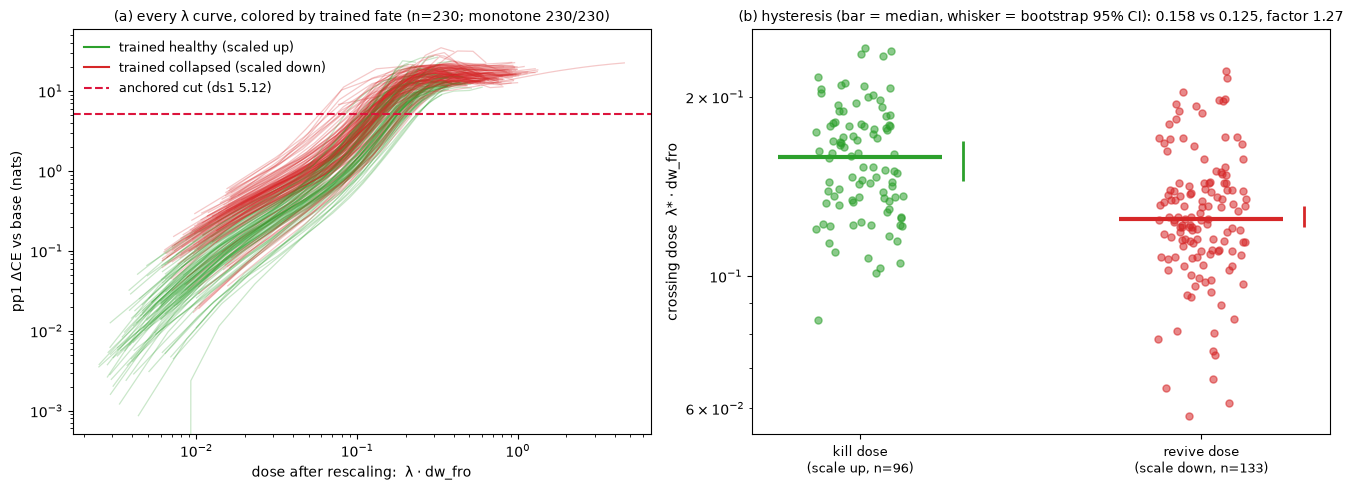

kill median 0.1583 | revive median 0.1246 | raw factor 1.27 (paper, anchored CE-primary: 0.158 / 0.125; 1.29x [1.23,1.35] adjusted, 1.12x [1.05,1.20] after training-dose adjustment)


In [16]:
nrm = load_adapter_norm_runs(OUT)
nrm = nrm[nrm.student_tag.str.startswith('ep20_') & (nrm.teacher == 'ep2_lr5e-4_r32a64_tseed1')]
dwkey = nrm.groupby(['student_base', 'student_tag', 'ftseed']).dw_fro.first()
def run_dir(b, t, s):
    return OUT/'students'/'dog'/b/'teacher-pythia-160m'/'ep2_lr5e-4_r32a64_tseed1'/'ex10-20_prefix_n100k'/t/f'ftseed{s}'
cef2 = sorted(A.glob('lambda_families_ce_*.jsonl'))
USED_CE2 = bool(cef2)
rows = []
if USED_CE2:
    fam_df = pd.concat([read_jsonl(f) for f in cef2], ignore_index=True)
    fam_df['bkey'] = fam_df.base.str.split('/').str[-1]
    for run, g in fam_df.groupby('run'):
        g = g.sort_values('lam'); b = g.bkey.iloc[0]; cut = DCX[b]
        tag = Path(run).parent.name; seed = int(Path(run).name.replace('ftseed', ''))
        lams = list(g.lam.values); kls = g.delta_ce.values.astype(float)
        pp0 = load_probe(Path(run)) or {}
        kl_run = pp0.get('delta_ce', pp0.get('kl_base_student'))
        fate = np.where(np.isfinite(kls) & (kls <= cut), 'A', 'D')
        rows.append(dict(fam='ce', tag=tag, seed=seed, base=b, cut=cut,
                         dw=dwkey.get((b, tag, seed), np.nan), lams=lams, kls=kls,
                         kl_run=kl_run, mono=re.fullmatch(r'A*D*', ''.join(fate)) is not None,
                         lam_cross=interp_crossing(lams, list(kls), cut, rising=True)))
    SRC2 = f'{len(cef2)} lambda_families_ce chunks (ΔCE readout, unified 15-λ grid)'
else:
    FAMS = {'scale': 'frozen_a_ablation_scale_lam*_pp1.json', 'revival': 'frozen_a_ablation_revival_lam*_pp1.json',
            'lamstrat': 'frozen_a_ablation_lamstrat_lam*_pp1.json', 'lamstrat_s2': 'frozen_a_ablation_lamstrat_s2_lam*_pp1.json',
            'shellext_s1': 'frozen_a_ablation_shellext_s1_lam*_pp1.json', 'shellext_s2': 'frozen_a_ablation_shellext_s2_lam*_pp1.json',
            'ws1lam': 'frozen_a_ablation_ws1lam_lam*_pp1.json'}
    curves, cbase = {}, {}
    for fam, pat in FAMS.items():
        for f in _glob.glob(str(A/pat)):
            d = read_json(f); lin = d['lineage']
            for x in d['results']:
                k = (fam, x['student_tag'], x['ftseed'])
                cbase[k] = lin['student_base'] if isinstance(lin, dict) and 'student_base' in lin else 'pythia-160m-data-seed1'
                curves.setdefault(k, {})[d['scale_lambda']] = x['pile_kl_base_ablated']
    for k, cdict in curves.items():
        fam, tag, seed = k; b = cbase[k]; cut = DCX[b]
        lams = sorted(cdict); kls = np.array([cdict[v] for v in lams], float)
        pp0 = load_probe(run_dir(b, tag, seed)) or {}
        kl_run = pp0.get('kl_base_student')
        fate = np.where(np.isfinite(kls) & (kls <= cut), 'A', 'D')
        rows.append(dict(fam=fam, tag=tag, seed=seed, base=b, cut=cut,
                         dw=dwkey.get((b, tag, seed), np.nan), lams=lams, kls=kls,
                         kl_run=kl_run, mono=re.fullmatch(r'A*D*', ''.join(fate)) is not None,
                         lam_cross=interp_crossing(lams, kls, cut, rising=True)))
    SRC2 = 'legacy frozen_a family files (KL readout)'
cv = pd.DataFrame(rows)
cv['trained_dead'] = pd.to_numeric(cv.kl_run, errors='coerce') > cv.cut
have = cv.dropna(subset=['dw'])
YLAB2 = KL_LAB if USED_CE2 else 'pp1 Pile-KL vs base (nats)'
print(f"λ curves: {len(cv)} from {SRC2} | with dose: {len(have)} | "
      f"monotone integrity event: {int(cv.mono.sum())}/{len(cv)}")

fig, axes = plt.subplots(1, 2, figsize=(13.5, 5.0))
for _, r in have.iterrows():
    axes[0].plot(np.array(r.lams)*r.dw, r.kls, '-', color=('tab:red' if r.trained_dead else 'tab:green'),
                 alpha=0.25, lw=0.9)
axes[0].axhline(DC_DS1, color='crimson', ls='--', lw=1.5)
axes[0].set_xscale('log'); axes[0].set_yscale('log')
axes[0].set_xlabel('dose after rescaling:  λ · dw_fro'); axes[0].set_ylabel(YLAB2)
axes[0].set_title(f'(a) every λ curve, colored by trained fate (n={len(have)}; '
                  f'monotone {int(cv.mono.sum())}/{len(cv)})', fontsize=10)
h = [plt.Line2D([], [], color='tab:green', label='trained healthy (scaled up)'),
     plt.Line2D([], [], color='tab:red', label='trained collapsed (scaled down)'),
     plt.Line2D([], [], color='crimson', ls='--', label=f'anchored cut (ds1 {DC_DS1:.2f})')]
axes[0].legend(handles=h, fontsize=9, frameon=False, loc='upper left')
cal = (have if USED_CE2 else have[have.fam.isin(['lamstrat', 'lamstrat_s2', 'shellext_s1', 'shellext_s2'])]).dropna(subset=['lam_cross'])
kill = (cal[~cal.trained_dead].lam_cross * cal[~cal.trained_dead].dw).dropna()
revi = (cal[cal.trained_dead].lam_cross * cal[cal.trained_dead].dw).dropna()
rj = np.random.default_rng(1)
for j, (v, col) in enumerate(((kill, 'tab:green'), (revi, 'tab:red'))):
    axes[1].scatter(j + rj.uniform(-0.13, 0.13, len(v)), v, s=26, alpha=0.55, color=col)
    m, lo, hi = med_ci(v.values)
    axes[1].hlines(m, j-0.24, j+0.24, color=col, lw=3)
    axes[1].vlines(j+0.3, lo, hi, color=col, lw=2)
axes[1].set_xticks([0, 1])
axes[1].set_xticklabels([f'kill dose\n(scale up, n={len(kill)})', f'revive dose\n(scale down, n={len(revi)})'], fontsize=9)
axes[1].set_yscale('log'); axes[1].set_ylabel('crossing dose  λ* · dw_fro')
axes[1].set_title(f'(b) hysteresis (bar = median, whisker = bootstrap 95% CI): '
                  f'{np.median(kill):.3f} vs {np.median(revi):.3f}, factor {np.median(kill)/np.median(revi):.2f}', fontsize=10)
plt.tight_layout(); fig.savefig(FIGDIR/'fig02_lambda_families.png', dpi=180, bbox_inches='tight'); plt.show()
print(f'kill median {np.median(kill):.4f} | revive median {np.median(revi):.4f} | raw factor {np.median(kill)/np.median(revi):.2f}'
      ' (paper, anchored CE-primary: 0.158 / 0.125; 1.29x [1.23,1.35] adjusted, 1.12x [1.05,1.20] after training-dose adjustment)')

## Figure 3 — §4.2 (size experiments) / §4.6 *The training-time clamp*

**Construction.** Clamp runs (`{output_root}/clamp_students/fro-c<ratio>/…`) train at
otherwise-lethal strip hyperparameters with the update's Frobenius norm capped at
ratio × the per-rank θ̂; once a run's update reaches the cap it stays there for the rest of
training. A free-running strip run that *ends* at the same size spent most of training below
it and merely arrived there. **(a)** alive fraction vs clamp ceiling. **(b)** P(collapsed)
at matched *final* size (per-rank anchored θ̂ from the strip's dead-edge; shaded band =
0.7–1.0×θ̂): at the same endpoint size, the held-at-size runs die far more often than the
arrived-at-size runs — the training-time dose is path-dependent. Paper: 19/38 vs 6/72.

clamp runs (fro): 124 probed 124 | unclamped comparison runs: 349


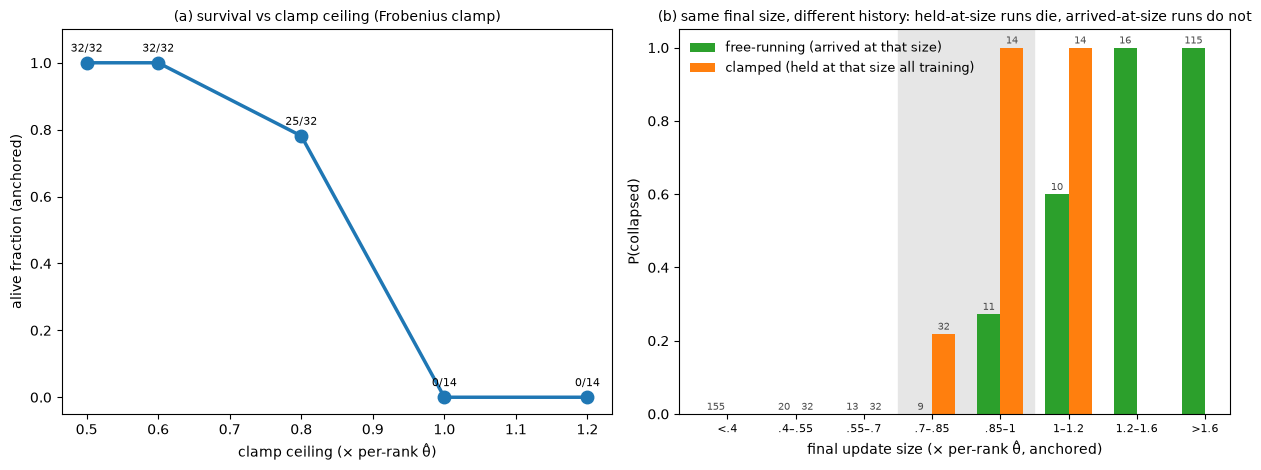

0.7–1.0×θ̂ band: clamped 21/46 dead vs free 0/17 (paper: 19/38 vs 6/72)
ceiling 0.5×θ̂: 32/32 alive | ceiling ≥1.0×θ̂: 0/28 alive (paper: 32/32 and 0/28)


In [17]:
def dead_edge(x, y):
    o = np.argsort(x); x, y = np.asarray(x)[o], np.asarray(y)[o]
    N = len(x); cum = np.r_[0, np.cumsum(y)]
    acc = np.array([((i - cum[i]) + (cum[-1] - cum[i])) / N for i in range(N + 1)])
    i = int(np.argmax(acc)); return float(x[i]) if i < N else np.nan
theta_rank = {rk: dead_edge(g.dw, g.dead.astype(int)) for rk, g in sd.groupby('rank')}
rows = []
for labdir in sorted((OUT/'clamp_students').iterdir()):
    lab = labdir.name
    if lab == 'ckpt-replay' or '-c' not in lab: continue
    norm, c = lab.split('-c'); ratio = float(c.replace('p', '.'))
    for mf in _glob.glob(str(labdir/'*/*/*/*/*/*/*/train_manifest.json')):
        rd = Path(mf).parent
        pr = load_probe(rd) or {}
        try:
            log = [json.loads(l) for l in (rd/'clamp_log.jsonl').read_text().splitlines()]
        except FileNotFoundError:
            continue
        tag = rd.parent.name; mrank = int(re.search(r'_r(\d+)a', tag).group(1))
        rows.append(dict(norm=norm, ratio=ratio, tag=tag, rank=mrank,
                         dce=pr.get('delta_ce', pr.get('kl_base_student')), dose_final=log[-1]['dose']))
clamp = pd.DataFrame(rows)
clamp['dce'] = pd.to_numeric(clamp.dce, errors='coerce')
clamp['dead'] = (~np.isfinite(clamp.dce)) | (clamp.dce > DC_DS1)
cf = clamp[clamp.norm == 'fro'].copy()
cf['x'] = cf.dose_final / cf['rank'].map(theta_rank)
su = sd[sd['rank'].isin(sorted(cf['rank'].unique()))].copy()
su['x'] = su.dw / su['rank'].map(theta_rank)
print(f"clamp runs (fro): {len(cf)} probed {int(cf.dce.notna().sum())} | unclamped comparison runs: {len(su)}")

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.8))
ag = cf.groupby('ratio').agg(alive=('dead', lambda s: 1 - s.mean()), n=('dead', 'size')).reset_index()
axes[0].plot(ag.ratio, ag.alive, 'o-', color='tab:blue', lw=2.5, ms=9)
for _, r in ag.iterrows():
    axes[0].annotate(f"{int(round(r.alive*r.n))}/{int(r.n)}", (r.ratio, r.alive), textcoords='offset points',
                     xytext=(0, 8), ha='center', fontsize=8)
axes[0].set_xlabel('clamp ceiling (× per-rank θ̂)'); axes[0].set_ylabel('alive fraction (anchored)')
axes[0].set_ylim(-0.05, 1.1); axes[0].set_title('(a) survival vs clamp ceiling (Frobenius clamp)', fontsize=10)
bins = [0, 0.4, 0.55, 0.7, 0.85, 1.0, 1.2, 1.6, 100]
bl = ['<.4', '.4–.55', '.55–.7', '.7–.85', '.85–1', '1–1.2', '1.2–1.6', '>1.6']
for d, lab, col, off in ((su, 'free-running (arrived at that size)', 'tab:green', -0.17),
                         (cf, 'clamped (held at that size all training)', 'tab:orange', 0.17)):
    g = d.groupby(pd.cut(d.x, bins), observed=False).dead.agg(['mean', 'size'])
    xs = np.arange(len(g))
    axes[1].bar(xs + off, g['mean'], 0.34, color=col, label=lab)
    for xi, (m, n_) in zip(xs, g.values):
        if n_ > 0: axes[1].annotate(int(n_), (xi + off, m), textcoords='offset points', xytext=(0, 3),
                                    ha='center', fontsize=7, color='0.3')
axes[1].axvspan(2.5, 4.5, color='0.9', zorder=0)
axes[1].set_xticks(np.arange(len(bl))); axes[1].set_xticklabels(bl, fontsize=8)
axes[1].set_xlabel('final update size (× per-rank θ̂, anchored)'); axes[1].set_ylabel('P(collapsed)')
axes[1].set_title('(b) same final size, different history: held-at-size runs die, arrived-at-size runs do not', fontsize=10)
axes[1].legend(fontsize=9, frameon=False, loc='upper left')
plt.tight_layout(); fig.savefig(FIGDIR/'fig03_clamp.png', dpi=180, bbox_inches='tight'); plt.show()
b1 = cf[(cf.x >= 0.7) & (cf.x < 1.0)]; b2 = su[(su.x >= 0.7) & (su.x < 1.0)]
print(f'0.7–1.0×θ̂ band: clamped {int(b1.dead.sum())}/{len(b1)} dead vs free {int(b2.dead.sum())}/{len(b2)} (paper: 19/38 vs 6/72)')
lo = cf[np.isclose(cf.ratio, 0.5)]; hi = cf[cf.ratio >= 1.0]
print(f'ceiling 0.5×θ̂: {int((~lo.dead).sum())}/{len(lo)} alive | ceiling ≥1.0×θ̂: {int((~hi.dead).sum())}/{len(hi)} alive '
      '(paper: 32/32 and 0/28)')

## Table 1 + Figure 11 — §4.2 (direction experiments) *The direction surgery, Randomized variant: the color-graded table, and census-scale healing*

Historical section. Its interpretation and displayed results are superseded by the executed direction-analysis block above. Source code is retained below with execution disabled by default.

In [ ]:
from subliminal_learning.weightspace.deltas import surgery_original_delta_ce

ce_main = [f for f in sorted(A.glob('position_surgery_ce_*.jsonl')) if not f.name.endswith('_prog.jsonl')]
USED_CES = bool(ce_main)
df = (pd.concat([read_jsonl(f) for f in ce_main], ignore_index=True) if USED_CES
      else read_jsonl(A/'position_surgery_v2.jsonl'))
df['val'] = df['delta_ce'] if 'delta_ce' in df.columns else df['pile_kl']
YLABS = KL_LAB if USED_CES else 'pp1 Pile-KL vs base (nats)'
print('surgery source:', f'{len(ce_main)} position_surgery_ce arms (ΔCE)' if USED_CES else 'position_surgery_v2 (KL)')
def surg_arm(r):
    if '/teachers/' in r: return 'teacher(orig)'
    if '/controls/' in r: return 'traitfree(ds1)'
    if '/students/dog/pythia-160m/' in r: return 'samemodel(orig)'
    return 'strip(ds1)'
df['arm'] = df.run.map(surg_arm)
pv = df.pivot_table(index=['arm', 'run'], columns='variant', values='val').reset_index()
pv['randm'] = pv[['rand0', 'rand1']].mean(axis=1)
pv['dc'] = np.where(pv.arm.str.contains('orig'), DC_ORIG, DC_DS1)
pv['dead'] = pv['orig'] > pv['dc']
pp = df.pivot_table(index=['arm', 'run'], columns='variant', values='p_target').reset_index()
pp['randm'] = pp[['rand0', 'rand1']].mean(axis=1)
mm = pv.merge(pp, on=['arm', 'run'], suffixes=('_kl', '_p'))
ARMS = ['strip(ds1)', 'samemodel(orig)', 'teacher(orig)', 'traitfree(ds1)']
dead = pv[pv.dead].copy()
dead['band'] = pd.cut(dead.orig, [0, 9, 12, np.inf], labels=['cut–9 nats', '9–12 nats', '>12 nats'])
POSL = {'orig': 'trained', 'align': 'W0-aligned', 'randm': 'randomized'}
long = dead.melt(id_vars=['arm', 'band'], value_vars=['orig', 'align', 'randm'],
                 var_name='source', value_name='kl')
long['source'] = long.source.map(POSL)
tab = long.pivot_table(index='arm', columns=['band', 'source'], values='kl', aggfunc='median', observed=True)
cols = pd.MultiIndex.from_product([['cut–9 nats', '9–12 nats', '>12 nats'],
                                   ['trained', 'W0-aligned', 'randomized']], names=['band', 'source'])
tab = tab.reindex(index=ARMS, columns=cols)
cnt = dead.groupby(['arm', 'band'], observed=True).size().unstack().reindex(index=ARMS)
DCROW = {'strip(ds1)': DC_DS1, 'samemodel(orig)': DC_ORIG, 'teacher(orig)': DC_ORIG, 'traitfree(ds1)': DC_DS1}
sty = (tab.style.background_gradient(cmap='RdYlGn_r', axis=None, vmin=0.0, vmax=15.0)
       .format('{:.1f}', na_rep='—')
       .apply(lambda row: ['font-weight: bold' if pd.notna(v) and v < DCROW[row.name] else '' for v in row], axis=1)
       .set_caption('Table 1 — anchored-dead runs (158-run ce-wave campaign): median pp1 ΔCE vs base (nats), '
                    'arm × singular-vector source, one column block per collapse-depth band. '
                    'Bold = healed below its own receiver bar.'))
display(sty)
print('n (anchored-dead runs) per arm × band:')
display(cnt)
tab.to_csv(FIGDIR/'table1_surgery_medians.csv'); cnt.to_csv(FIGDIR/'table1_surgery_counts.csv')
print('anchored-dead median ΔCE per arm (paper §4.2: 9.9→1.7 / 11.7→3.0 / 6.9→0.00 / 9.0→6.9):')
print(pv[pv.dead].groupby('arm')[['orig', 'align', 'randm']].median().round(2).loc[ARMS].to_string())

# ---- Figure 11: the 08-28 census (Randomized + W0-aligned, all six arms) ----
CEN_ARMS = {'strip': ('strip (ds1)', 'pythia-160m-data-seed1'),
            'samemodel': ('orig same-model', 'pythia-160m'),
            'traitfree': ('trait-free (ds1)', 'pythia-160m-data-seed1'),
            'teachers': ('teachers (orig)', 'pythia-160m'),
            'm410same': ('410M same-model', 'pythia-410m'),
            'm410cross': ('410M cross-seed', 'pythia-410m-seed1')}
CEN = {}
for a_, (lab_, b_) in CEN_ARMS.items():
    d_ = pd.concat([read_jsonl(f) for f in sorted(A.glob(f'position_surgery_cen_{a_}_s*.jsonl'))],
                   ignore_index=True)
    c_ = d_.pivot_table(index='run', columns='variant', values='delta_ce', aggfunc='first')
    base_, src_ = surgery_original_delta_ce(d_.to_dict('records'))
    c_['stored'] = pd.Series(base_).reindex(c_.index)
    c_['baseline_src'] = pd.Series(src_).reindex(c_.index)
    c_ = c_[np.isfinite(c_['stored'])]
    c_['cut'] = DCX[b_]
    CEN[a_] = c_
    n_ = c_.baseline_src.value_counts()
    print(f"{a_}: baseline source paired {int(n_.get('paired', 0))} / "
          f"stored_probe {int(n_.get('stored_probe', 0))} / "
          f"missing {int((pd.Series(src_) == 'missing').sum())}")
aud = pd.concat([read_jsonl(f) for f in sorted(A.glob('position_surgery_cen_*_audit.jsonl'))], ignore_index=True)
AUD_BASE, AUD_SRC = surgery_original_delta_ce(aud.to_dict('records'))
_as = pd.Series(AUD_SRC).value_counts()
print(f"audit: baseline source paired {int(_as.get('paired', 0))} / "
      f"stored_probe {int(_as.get('stored_probe', 0))} / missing {int(_as.get('missing', 0))}")
ao = aud[aud.variant == 'orig']
_ad = (ao.delta_ce - ao.run.map(AUD_BASE)).abs()
print(f"census on disk: {sum(len(c) for c in CEN.values())} runs with both variants (2,618-run frozen lists); "
      f"audit |orig − baseline ΔCE|: median {float(_ad[np.isfinite(_ad)].median()):.4f} nats over "
      f"{int(np.isfinite(_ad).sum())} re-runs with a finite baseline")
fig, axes = plt.subplots(2, 3, figsize=(13.5, 8.2))
for ax, (a_, (lab_, b_)) in zip(axes.ravel(), CEN_ARMS.items()):
    c_ = CEN[a_]; cut_ = c_.cut.iloc[0]
    dead_ = c_.stored > cut_
    ax.plot(c_.stored[~dead_], c_.rand0[~dead_], 'o', color='tab:green', ms=4, alpha=0.45, label='healthy (trained)')
    ax.plot(c_.stored[dead_], c_.rand0[dead_], 'o', color='tab:red', ms=4, alpha=0.45, label='collapsed (trained)')
    lim = float(np.nanmax([c_.stored.max(), c_.rand0.max()])) * 1.05
    ax.plot([0, lim], [0, lim], '-', color='0.6', lw=1)
    ax.axhline(cut_, color='crimson', ls='--', lw=1.2); ax.axvline(cut_, color='crimson', ls='--', lw=1.2)
    rev = float((c_.rand0[dead_] < cut_).mean()) if dead_.any() else np.nan
    ax.set_title(f'{lab_} (n={len(c_)}; dead {int(dead_.sum())}, randomized revives {rev:.0%})', fontsize=10)
    ax.set_xlabel('trained damage (baseline ΔCE, nats)')
axes[0, 0].set_ylabel('Randomized-variant ΔCE (nats)'); axes[1, 0].set_ylabel('Randomized-variant ΔCE (nats)')
axes[0, 0].legend(fontsize=8, frameon=False, loc='upper left')
fig.suptitle('Figure 11 — census-scale direction dependence: same strengths, randomized singular vectors',
             fontsize=11, y=1.0)
plt.tight_layout(); fig.savefig(FIGDIR/'fig11_census_healing.png', dpi=180, bbox_inches='tight'); plt.show()
cenmed = pd.DataFrame({lab_: {'trained (baseline)': CEN[a_].loc[CEN[a_].stored > CEN[a_].cut.iloc[0], 'stored'].median(),
                              'W0-aligned': CEN[a_].loc[CEN[a_].stored > CEN[a_].cut.iloc[0], 'align'].median(),
                              'randomized': CEN[a_].loc[CEN[a_].stored > CEN[a_].cut.iloc[0], 'rand0'].median()}
                       for a_, (lab_, b_) in CEN_ARMS.items()}).T.round(2)
print('census anchored-dead medians (nats), trained / W0-aligned / randomized per arm\n'
      '(the 158-campaign reading "aligned intermediate" holds on four of six arms at census depth;\n'
      ' same-model and trait-free dead medians have aligned ≈ randomized):')
print(cenmed.to_string())
cenmed.to_csv(FIGDIR/'fig11_census_medians.csv')


## Table 1b — §4.2 (direction experiments) *Selector endpoints: the content sits in the strongest few directions*

Historical section. Its interpretation and displayed results are superseded by the executed direction-analysis block above. Source code is retained below with execution disabled by default.

In [ ]:
SEL_ARMS = CEN_ARMS  # same six arms / receiver bases as the census
SELDF, SELT = {}, {}
for a_, (lab_, b_) in SEL_ARMS.items():
    s_ = pd.concat([read_jsonl(f) for f in sorted(A.glob(f'position_surgery_sub_{a_}_s*.jsonl'))], ignore_index=True)
    t_ = pd.concat([read_jsonl(f) for f in sorted(A.glob(f'position_surgery_subt_{a_}_s*.jsonl'))], ignore_index=True)
    for d_ in (s_, t_):
        d_['sel'] = d_.variant.str.split('@').str[0]
        d_['t'] = d_.variant.str.split('@').str[1].astype(float).fillna(1.0)
        b_, sb_ = surgery_original_delta_ce(d_.to_dict('records'))
        d_['stored'] = d_.run.map(b_)
        d_['baseline_src'] = d_.run.map(sb_)
    n_ = pd.concat([s_.baseline_src, t_.baseline_src]).value_counts()
    print(f"{a_}: baseline source paired {int(n_.get('paired', 0))} / "
          f"stored_probe {int(n_.get('stored_probe', 0))} / missing {int(n_.get('missing', 0))} (rows)")
    s_['cut'] = DCX[b_]; t_['cut'] = DCX[b_]
    SELDF[a_], SELT[a_] = s_, t_
SELS = ['top1', 'top2', 'top4', 'rest1', 'rest2', 'rest4']
rows_, revs_, ns_ = {}, {}, {}
for a_, (lab_, b_) in SEL_ARMS.items():
    s_ = SELDF[a_]; cut_ = DCX[b_]
    dd = s_[(s_.stored > cut_) & s_.sel.isin(SELS)]
    rows_[lab_] = dd.groupby('sel')['delta_ce'].median()
    revs_[lab_] = dd.groupby('sel')['delta_ce'].apply(lambda v: float((v < cut_).mean()))
    ns_[lab_] = dd.groupby('sel')['run'].nunique()
t1b = pd.DataFrame(rows_).T.reindex(columns=SELS)
t1b_rev = pd.DataFrame(revs_).T.reindex(columns=SELS)
t1b_n = pd.DataFrame(ns_).T.reindex(columns=SELS)
sty = (t1b.style.background_gradient(cmap='RdYlGn_r', axis=None, vmin=0.0, vmax=15.0)
       .format('{:.1f}', na_rep='—')
       .set_caption('Table 1b — anchored-dead runs of the 546-run selector subset: median pp1 ΔCE vs base (nats) '
                    'after randomizing ONLY the selected singular-vector pairs (Top-k = k strongest randomized; '
                    'Rest-k = all but the k strongest randomized, top-k kept trained). Row = arm.'))
display(sty)
sty2 = (t1b_rev.style.background_gradient(cmap='RdYlGn', axis=None, vmin=0.0, vmax=1.0)
        .format('{:.0%}', na_rep='—')
        .set_caption('Table 1b companion — revival fraction: share of those anchored-dead runs brought below their '
                     'receiver bar by the selector alone (n per cell in the counts CSV).'))
display(sty2)
t1b.to_csv(FIGDIR/'table1b_selector_medians.csv'); t1b_rev.to_csv(FIGDIR/'table1b_selector_revival.csv')
t1b_n.to_csv(FIGDIR/'table1b_selector_counts.csv')
print('paper spot-checks — Top-4 revival per student arm 85–100%, Rest-4 16–47%; teachers Top-1 97%, Rest-4 0%:')
print(t1b_rev[['top4', 'rest4', 'top1']].round(2).to_string())
print('denominator-valid subset runs per arm (paper: 141/83/61/147/67/47):',
      {lab: int(SELDF[a].run.nunique()) for a, (lab, b) in SEL_ARMS.items()})


## Figure 4 — §4.2 (direction experiments) *The rotation amount t: graded, no threshold in direction space*

Historical section. Its interpretation and displayed results are superseded by the executed direction-analysis block above. Source code is retained below with execution disabled by default.

In [ ]:
pr = read_jsonl(A/'position_surgery_ce_prog.jsonl')
from subliminal_learning.weightspace.deltas import surgery_record_is_current
if not all(surgery_record_is_current(r, require_keyed_targets=True) for r in pr.to_dict("records")):
    raise ValueError("Legacy randt records: rerun position_surgery with the original t_ladder before plotting.")
pr['val'] = pr['delta_ce']
def t_of(v): return 0.0 if v == 'orig' else (1.0 if v == 'rand0' else (float(v[5:]) if v.startswith('randt') else np.nan))
pr['t'] = pr.variant.map(t_of); pr = pr.dropna(subset=['t'])
prp = pr.pivot_table(index='run', columns='t', values='val'); pdead = prp[0.0] > DC_DS1
fig, axes = plt.subplots(1, 3, figsize=(15.0, 4.8))
ax = axes[0]
for _, row in prp.iterrows():
    ax.plot(prp.columns, row.values, '-', color=('tab:red' if row[0.0] > DC_DS1 else 'tab:green'), alpha=0.3, lw=1)
ax.plot(prp.columns, prp[pdead].median(), 'o-', color='tab:red', lw=2.5, ms=8, label='collapsed runs (median)')
ax.plot(prp.columns, prp[~pdead].median(), 's-', color='tab:green', lw=2.5, ms=8, label='healthy runs (median)')
ax.axhline(DC_DS1, color='crimson', ls='--', lw=1.5)
ax.set_xlabel('rotation amount t (0 = trained, 1 = random)'); ax.set_ylabel(KL_LAB)
ax.set_title('(a) all pairs (Randomized), 12 strip runs', fontsize=10)
ax.legend(fontsize=8, frameon=False)
SEL_ORDER = ['top1', 'top2', 'top4', 'rest1', 'rest2', 'rest4', 'sub', 'super']
SELC = dict(zip(SEL_ORDER, plt.cm.tab10.colors))
for ax, a_, pl_ in ((axes[1], 'strip', '(b) selectors, strip (ds1)'), (axes[2], 'teachers', '(c) selectors, teachers (orig)')):
    cut_ = SELT[a_].cut.iloc[0]
    both = pd.concat([SELT[a_], SELDF[a_]], ignore_index=True)
    dd = both[both.stored > cut_]
    for sel in SEL_ORDER:
        pt_ = dd[dd.sel == sel].pivot_table(index='run', columns='t', values='delta_ce').dropna()
        if len(pt_) < 5: continue  # empty-selection selectors (supercritical on teachers) have no populated ladder
        med = pt_.median(axis=0)
        ax.plot(med.index, med.values, 'o-', color=SELC[sel], lw=2, ms=6, label=sel)
    ax.axhline(cut_, color='crimson', ls='--', lw=1.5)
    ax.set_xlabel('rotation amount t'); ax.set_title(f'{pl_}, anchored-dead runs', fontsize=10)
h4, l4 = axes[1].get_legend_handles_labels()
axes[2].legend(h4, l4, fontsize=8, frameon=False, loc='center left', bbox_to_anchor=(1.01, 0.5),
               title='selector', title_fontsize=9)  # legend from the strip panel — the superset of drawn selectors; per-panel n in the CSV
plt.tight_layout(); fig.savefig(FIGDIR/'fig04_rotation_progression.png', dpi=180, bbox_inches='tight'); plt.show()
allb4 = []
for a_, (lab_, b_) in SEL_ARMS.items():
    b4 = pd.concat([SELT[a_], SELDF[a_]], ignore_index=True)
    allb4.append(b4[b4.stored > DCX[b_]].assign(armlab=lab_))
allb4 = pd.concat(allb4, ignore_index=True)
def _mono_fracs(pt_):
    vals = pt_.values
    return (float(np.mean([np.all(np.diff(r) <= 0.05 * np.maximum(r[:-1], 1e-6)) for r in vals])),
            float(np.mean([np.all(np.diff(r) <= 0.05) for r in vals])))
mono_rows = []
for sel in SEL_ORDER:
    pt_ = allb4[allb4.sel == sel].pivot_table(index=['armlab', 'run'], columns='t', values='delta_ce').dropna()
    if len(pt_) < 5 or pt_.shape[1] < 3: continue
    rel_, abs_ = _mono_fracs(pt_)
    mono_rows.append({'selector': sel, 'n (pooled)': len(pt_),
                      'monotone, 5% rel tol': rel_, 'monotone, 0.05-nat abs tol': abs_})
mono = pd.DataFrame(mono_rows).set_index('selector')
print('fraction of anchored-dead runs monotone non-increasing along t, POOLED across the six arms '
      '(row unit = one selector; a run enters with a complete t ladder; two tolerance conventions '
      '— the 5%-relative column is the convention that reproduces the ledger reading):')
print(mono.round(2).to_string())
per_arm4 = []
for (al_, sel), g4 in allb4.groupby(['armlab', 'sel']):
    pt_ = g4.pivot_table(index='run', columns='t', values='delta_ce').dropna()
    if len(pt_) < 5 or pt_.shape[1] < 3: continue
    rel_, abs_ = _mono_fracs(pt_)
    per_arm4.append({'arm': al_, 'selector': sel, 'n': len(pt_), 'rel5pct': rel_, 'abs0.05': abs_})
pa4 = pd.DataFrame(per_arm4)
pa4.to_csv(FIGDIR/'fig04_monotone_fractions.csv', index=False)
print(f"per-arm × selector fractions → fig04_monotone_fractions.csv "
      f"(abs-tol range {pa4['abs0.05'].min():.2f}–{pa4['abs0.05'].max():.2f}, "
      f"rel-tol range {pa4['rel5pct'].min():.2f}–{pa4['rel5pct'].max():.2f})")


## Figure 5 — §4.2 *Injection ladders: matched-Frobenius vs matched-σ, and the donor-direction ladders*

Historical section. Its interpretation and displayed results are superseded by the executed direction-analysis block above. Source code is retained below with execution disabled by default.

In [ ]:
def load_ladder(name):
    fce = A/f'{name}_ce.json'
    d_ = read_json(fce if fce.exists() else A/f'{name}.json')
    fr = pd.DataFrame(d_['results'])
    fr['y'] = fr['delta_ce'] if 'delta_ce' in fr.columns else fr['kl']
    return fr, fce.exists()
dif, lce1 = load_ladder('diffuse_ladder_surgery_ds1')
spc, lce2 = load_ladder('specmatch_ladder_surgery_ds1')
trd, lce3 = load_ladder('trained_direction_ladder_ds1')
YLABL = KL_LAB if (lce1 and lce2 and lce3) else 'pp1 Pile-KL vs base (nats)'
print('ladder sources CE?', dict(diffuse=lce1, specmatch=lce2, trained=lce3))
dif['intr'] = dif.intruder_mods.str.split('/').str[0].astype(int)
fig, axes = plt.subplots(1, 3, figsize=(16.5, 4.8), sharey=False)
for al, lab, col in (('g', 'random directions', 'tab:blue'), ('a', 'W0-aligned', 'tab:orange')):
    g = dif[(dif['align'] == al) & (dif.E == 1.0)].sort_values('k')
    axes[0].plot(g.k, g.y, 'o-', color=col, lw=2.2, ms=8, label=f'{lab}, matched TOTAL energy (E=1)')
for al, lab, col in (('g', 'random directions', 'tab:blue'), ('a', 'W0-aligned', 'tab:orange')):
    g = spc[(spc['align'] == al) & (spc.E == 0.5)].sort_values('k')
    axes[0].plot(g.k, g.y, 's--', color=col, lw=1.8, ms=7, alpha=0.7, label=f'{lab}, matched PER-DIRECTION σ (E=0.5)')
axes[0].axhline(DC_DS1, color='crimson', ls=':', lw=1.2)
axes[0].set_xscale('log', base=2); axes[0].set_xlabel('number of injected directions k')
axes[0].set_ylabel(YLABL)
axes[0].set_title('(a) flat in k at matched energy;\nrises with k only as energy grows', fontsize=10)
axes[0].legend(fontsize=8, frameon=False)
EE = [0.5, 1.0, 2.0, 4.0]
for ax, k_ in ((axes[1], 16), (axes[2], 32)):
    for lab, cond, col in (('random directions', None, '0.5'),
                           ('collapsed-donor directions', 'tdead', 'tab:red'),
                           ('healthy-donor directions', 'talive', 'tab:green')):
        if cond is None:
            y = [float(dif[(dif['align'] == 'g') & (dif.k == k_) & (dif.E == e)].y.iloc[0]) for e in EE]
        else:
            y = [float(trd[(trd.cond == cond) & (trd.k == k_) & (trd.E == e)].y.iloc[0]) for e in EE]
        ax.plot(EE, y, 'o-', color=col, lw=2.2, ms=8, label=lab)
    ax.axhline(DC_DS1, color='crimson', ls=':', lw=1.2)
    ax.set_xscale('log', base=2); ax.set_xlabel('injection energy E (× per-module θ̄)')
    ax.set_title(f'({"b" if k_ == 16 else "c"}) donor-direction ladder, k = {k_}', fontsize=10)
axes[1].set_ylabel(YLABL)
axes[1].legend(fontsize=8, frameon=False, loc='upper left')
plt.tight_layout(); fig.savefig(FIGDIR/'fig05_injection_ladders.png', dpi=180, bbox_inches='tight'); plt.show()
print('paper anchors: flat-in-k 12.1→10.6 (E=1 generic, k 1→32); trained vs random k=16,E=1: 29.7/41.4 vs 10.8; '
      'k=32,E=2: 52.0 vs 13.7')

## Table 2 — §4.2 / §5.2 *Damage vs intruder counts on the full k × E grid*

Historical section. Its interpretation and displayed results are superseded by the executed direction-analysis block above. Source code is retained below with execution disabled by default.

In [ ]:
difl = dif.copy()
difl['position'] = difl['align'].map({'g': 'random directions', 'a': 'W0-aligned'})
kcols = pd.MultiIndex.from_product([['random directions', 'W0-aligned'], [1, 2, 4, 8, 16, 32]],
                                   names=['position', 'k'])
dmg = difl.pivot_table(index='E', columns=['position', 'k'], values='y').reindex(columns=kcols)
intr = difl.pivot_table(index='E', columns=['position', 'k'], values='intr').reindex(columns=kcols)
sty_d = (dmg.style.background_gradient(cmap='RdYlGn_r', axis=None, vmin=0.0, vmax=18.0)
         .format('{:.1f}')
         .map(lambda v: 'font-weight: bold' if pd.notna(v) and v > DC_DS1 else '')
         .set_caption('Table 2a — damage: pp1 Pile-KL vs base (nats), E × (position, k). '
                      'Bold = past the unigram bar. Rows ≈ constant: direction count does not gate damage.'))
sty_i = (intr.style.background_gradient(cmap='Purples', axis=None, vmin=0.0, vmax=48.0)
         .format('{:.0f}')
         .set_caption('Table 2b — intruder modules (of 48) at the same cells: high and k-dependent for random '
                      'position, zero everywhere for W0-aligned.'))
display(sty_d)
display(sty_i)
dmg.to_csv(FIGDIR/'table2a_ladder_damage.csv'); intr.to_csv(FIGDIR/'table2b_ladder_intruders.csv')
al2 = difl[(difl.position == 'W0-aligned') & (difl.E >= 2.0)]
print(f'aligned E≥2 cells: intruders max {int(al2.intr.max())}, damage {al2.y.min():.1f}–{al2.y.max():.1f} nats '
      '— kills with zero intruders')

## Figure 12 — §4.3 *The direction effect: ~600× between arms, ~2–3× within; depth-independence on the defined region*

**Construction.** **(a)** per-run direction effect log(ΔCE_trained / ΔCE_Randomized) —
the raw ratio, no floor (a 1e-6 guard only) — on the **denominator-valid subset**
(§3.3's frozen lists, `run_logs/surgcen_20260828/sub_*_s*.txt`: census runs whose
Randomized variant is below the receiver's anchored cut and whose own damage exceeds
2 nats; 546 runs — strip 141 / same-model 83 / trait-free 61 / teachers 147 /
410M same-model 67 / 410M cross-seed 47): one jittered strip per arm in
ascending-median order, black bar = median. Paper medians (§4.3): trait-free 0.59 /
orig same-model 1.35 / 410M same-model 1.43 / strip 1.60 / 410M cross-seed 1.79 /
teachers 6.98 — between-arm spread 6.4 log units ≈ 600×, within-arm IQR 0.71–1.07
(the teachers included). The numerator is the run's own stored probe (ΔCE); the
denominator the census Randomized draw. The superseded 158-run ce-wave pass (four
arms; medians 0.22 / 1.19 / 1.60 / 6.31, spread ≈ 440×, teacher IQR 3.9) stays in
the artifacts as the attributed historical pass — its extremes were the saturated
rows the subset rule now excludes. **(b)** the census strip arm: the statistic
against own damage, runs outside the subset greyed (Randomized itself dead, or
damage below the 2-nat floor — there the log-ratio saturates); black squares = band
medians on the subset, banding 2–cut / cut–9 / 9–12 / 12–20 / >20 nats
(paper §4.3: 1.42 / 1.64 / 1.62 / 1.63 / 1.55 — depth-independent).


strip: baseline source paired 0 / stored_probe 934 / missing 0


samemodel: baseline source paired 0 / stored_probe 312 / missing 0
traitfree: baseline source paired 0 / stored_probe 353 / missing 0
teachers: baseline source paired 0 / stored_probe 288 / missing 0


m410same: baseline source paired 0 / stored_probe 326 / missing 0
m410cross: baseline source paired 0 / stored_probe 288 / missing 0
denominator-valid subset per arm: {'strip': 141, 'samemodel': 83, 'traitfree': 61, 'teachers': 147, 'm410same': 67, 'm410cross': 47} | total 546


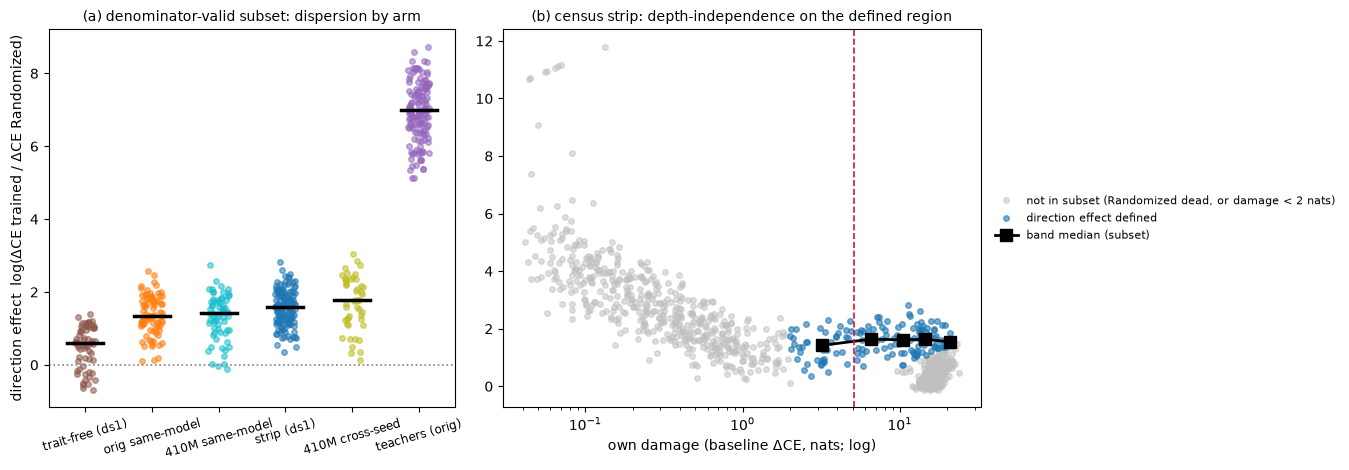

per-arm direction effect on the subset (paper §4.3: 0.59/1.35/1.43/1.60/1.79/6.98; IQR 0.71–1.07; n = 546):
                  median   iqr      n
trait-free (ds1)    0.59  0.89   61.0
orig same-model     1.35  0.71   83.0
410M same-model     1.43  0.79   67.0
strip (ds1)         1.60  0.73  141.0
410M cross-seed     1.79  1.07   47.0
teachers (orig)     6.98  1.06  147.0 
total n = 546; between-arm median spread 6.4 log units
strip band medians, banding 2–cut/cut–9/9–12/12–20/>20 (paper §4.3: 1.42/1.64/1.62/1.63/1.55):
                  x    de   n
band                         
(2.0, 5.123]   3.21  1.42  42
(5.123, 9.0]   6.54  1.64  30
(9.0, 12.0]   10.41  1.62  17
(12.0, 20.0]  14.43  1.63  48
(20.0, inf]   20.90  1.55   4


In [18]:
# Census arms + paired-baseline helper: defined here too, because their original home (the Table 1 +
# Figure 11 cell) is historical and skip-executed since 09-11.
from subliminal_learning.weightspace.deltas import surgery_original_delta_ce
CEN_ARMS = {'strip': ('strip (ds1)', 'pythia-160m-data-seed1'),
            'samemodel': ('orig same-model', 'pythia-160m'),
            'traitfree': ('trait-free (ds1)', 'pythia-160m-data-seed1'),
            'teachers': ('teachers (orig)', 'pythia-160m'),
            'm410same': ('410M same-model', 'pythia-410m'),
            'm410cross': ('410M cross-seed', 'pythia-410m-seed1')}
eps_ = 1e-6  # guard against log(0) only — the ledger's dispersion statistic is the raw ratio, no floor
# The denominator-valid subset (ICLR §3.3): frozen lists of the 08-29 selector campaign —
# census runs whose Randomized variant is below the receiver's anchored cut AND whose
# own damage (the paired original readout, ΔCE) exceeds 2 nats.
SUBV = {}
for a_, (lab_, b_) in CEN_ARMS.items():
    runs_ = set()
    for f_ in sorted(_glob.glob(str(REPO / 'run_logs' / 'surgcen_20260828' / f'sub_{a_}_s*.txt'))):
        runs_ |= {l.strip() for l in open(f_) if l.strip()}
    d_ = pd.concat([read_jsonl(f) for f in sorted(_glob.glob(str(A / f'position_surgery_cen_{a_}_*.jsonl')))],
                   ignore_index=True)  # audit files included — the frame the campaign lists were built from
    c_ = d_.pivot_table(index='run', columns='variant', values='delta_ce', aggfunc='first')
    base_, src_ = surgery_original_delta_ce(d_.to_dict('records'))
    c_['stored'] = pd.Series(base_).reindex(c_.index)
    c_['baseline_src'] = pd.Series(src_).reindex(c_.index)
    c_ = c_[np.isfinite(c_['stored'])]
    c_['member'] = c_.index.isin(runs_)
    c_['cut'] = DCX[b_]
    SUBV[a_] = c_
    n_ = c_.baseline_src.value_counts()
    print(f"{a_}: baseline source paired {int(n_.get('paired', 0))} / "
          f"stored_probe {int(n_.get('stored_probe', 0))} / "
          f"missing {int((pd.Series(src_) == 'missing').sum())}")
print('denominator-valid subset per arm:',
      {a_: int(v.member.sum()) for a_, v in SUBV.items()},
      '| total', sum(int(v.member.sum()) for v in SUBV.values()))
fig, axes = plt.subplots(1, 2, figsize=(13.6, 4.8), gridspec_kw={'width_ratios': [1.15, 1.35]})
order12 = ['traitfree', 'samemodel', 'm410same', 'strip', 'm410cross', 'teachers']
cols12 = {'traitfree': 'tab:brown', 'samemodel': 'tab:orange', 'm410same': 'tab:cyan',
          'strip': 'tab:blue', 'm410cross': 'tab:olive', 'teachers': 'tab:purple'}
rng12 = np.random.default_rng(2)
ax = axes[0]
disp_rows = {}
for i, a_ in enumerate(order12):
    c_ = SUBV[a_][SUBV[a_].member]
    v = np.log(c_.stored.clip(lower=eps_) / c_.rand0.clip(lower=eps_)).dropna()
    disp_rows[CEN_ARMS[a_][0]] = dict(median=float(v.median()),
                                      iqr=float(v.quantile(0.75) - v.quantile(0.25)), n=len(v))
    ax.plot(i + rng12.uniform(-0.16, 0.16, len(v)), v, 'o', ms=4, alpha=0.55, color=cols12[a_])
    ax.plot([i - 0.27, i + 0.27], [v.median()] * 2, '-', color='k', lw=2.5)
ax.axhline(0, color='0.5', ls=':', lw=1.2)
ax.set_xticks(range(6))
ax.set_xticklabels([CEN_ARMS[a_][0] for a_ in order12], rotation=16, fontsize=8.5)
ax.set_ylabel('direction effect  log(ΔCE trained / ΔCE Randomized)')
ax.set_title('(a) denominator-valid subset: dispersion by arm', fontsize=10)
# (b) census strip: statistic vs own damage; subset rule shown; band medians on the subset
cs = SUBV['strip']; cut_ = cs.cut.iloc[0]
de_ = np.log(cs.stored.clip(lower=eps_) / cs.rand0.clip(lower=eps_))
ax = axes[1]
ok = cs.member
ax.plot(cs.stored[~ok], de_[~ok], 'o', ms=4, color='0.75', alpha=0.5,
        label='not in subset (Randomized dead, or damage < 2 nats)')
ax.plot(cs.stored[ok], de_[ok], 'o', ms=4, color='tab:blue', alpha=0.6, label='direction effect defined')
bm = pd.DataFrame({'de': de_[ok], 'x': cs.stored[ok]}).dropna()
bm['band'] = pd.cut(bm.x, [2, cut_, 9, 12, 20, np.inf])
med12 = bm.groupby('band', observed=True).agg(x=('x', 'median'), de=('de', 'median'), n=('de', 'size'))
ax.plot(med12.x, med12.de, 's-', color='k', lw=2, ms=8, label='band median (subset)')
ax.axvline(cut_, color='crimson', ls='--', lw=1.2)
ax.set_xscale('log'); ax.set_xlabel('own damage (baseline ΔCE, nats; log)')
ax.set_title('(b) census strip: depth-independence on the defined region', fontsize=10)
ax.legend(fontsize=8, frameon=False, loc='center left', bbox_to_anchor=(1.01, 0.5))
plt.tight_layout(); fig.savefig(FIGDIR/'fig12_direction_effect.png', dpi=180, bbox_inches='tight'); plt.show()
disp12 = pd.DataFrame(disp_rows).T
print('per-arm direction effect on the subset (paper §4.3: 0.59/1.35/1.43/1.60/1.79/6.98; IQR 0.71–1.07; n = 546):')
print(disp12.round(2).to_string(),
      f"\ntotal n = {int(disp12.n.sum())}; between-arm median spread "
      f"{disp12['median'].max() - disp12['median'].min():.1f} log units")
print('strip band medians, banding 2–cut/cut–9/9–12/12–20/>20 (paper §4.3: 1.42/1.64/1.62/1.63/1.55):')
print(med12.round(2).to_string())


## Figure 6 — §4.3 *The λ-crossing test: per-arm median curves, and crossing sizes vs population θ̂*

**Construction.** CE-primary sources `lambda_crossing_ce_*.jsonl` (ce-wave 08-27: the three
160M arms with the drained 08-26 extension folded in, the ws1/ws2 12-run ladders, and the
two 410M arms), with the KL-era files (`lambda_crossing_{arms,410m}.jsonl`,
`lambda_crossing_ext_*.jsonl`) as fallback for any arm missing a CE re-run. The
intervention is the same λ-rescaling as Figure 2; the *question* differs — Figure 2
established the event is monotone and nearly reversible in size; here each dialed update's
crossing size is a measurement of its arm's tolerance, compared against the independently
fitted population θ̂. **(a, b)** one line per arm: the median λ curve across that arm's
ladders (each ladder interpolated onto a common dose grid), shaded band = bootstrap 95% CI
of the median. The dot marks where the arm's median per-update crossing lands on the cut;
the dashed vertical is the arm's population θ̂, fit from the endpoint fates of independently
trained runs. **These two measurements need not coincide a priori** — one is an eval-time
intervention on single finished updates, the other an observational fit over a population —
and they coincide only if fate is carried by the endpoint update rather than the training
path (Fig 2's near-reversibility; the clamp shows path effects exist) and content is an arm
constant. Dot-on-dashed-line is therefore the substantive finding, not a consistency check.
**θ̂ pins are the 08-27 audit's current-population anchored refits** (strip 0.142 /
same-model 0.150 / trait-free 0.262 / ws1 0.120 / ws2 0.159 / 410M same-model 0.186 /
cross-seed 0.189). The era pins (410M 0.187/0.134, ws 0.113/0.141) are superseded: the
apparent 1.4× 410M same-vs-cross θ̂ gap was estimation error in a pooled logistic over few
deaths and dissolved on the drained population — what remains is a uniform ~1.1–1.2×
offset of both 410M population θ̂s above the per-update crossings, within §4.6's
evaluation-time history range. **How the anchor appears here**: the dead bar is ONE
absolute CE threshold (H_uni = 7.8045 nats); in the plotted excess-over-own-base coordinate
it translates to a per-RECEIVER value Δ_cross = H_uni − ce_base (ds1 5.123 / orig 5.096 /
ws1 5.055 / ws2 5.169; 410M 5.466–5.474 — per receiver, not per arm: strip and trait-free
share the ds1 cut). Every label, crossing, and dot is computed against the run's own
receiver's Δ_cross; ONE cut line is drawn per panel (at the arms' median Δ_cross — the
per-receiver values differ by ≤ 0.11 nats, within line width here), and each crossing dot
sits at its own receiver's exact Δ_cross. **(c)** per-update crossing sizes: median (bar),
bootstrap 95% CI (whisker), pinned θ̂ (star); the declared-cut comparison is printed below.


CE-rerun arms: ['cross-seed(410m)', 'samemodel(410m)', 'samemodel(orig)', 'strip(ds1)', 'traitfree(ds1)', 'ws1', 'ws2']
λ-crossing sources loaded: ['lambda_crossing_arms', 'lambda_crossing_410m', 'lambda_crossing_ext_samemodel', 'lambda_crossing_ext_strip', 'lambda_crossing_ext_traitfree', 'lambda_crossing_ext_ws1', 'lambda_crossing_ext_ws2', 'lambda_crossing_ce_m410cross', 'lambda_crossing_ce_m410same', 'lambda_crossing_ce_samemodel', 'lambda_crossing_ce_strip', 'lambda_crossing_ce_traitfree', 'lambda_crossing_ce_ws1', 'lambda_crossing_ce_ws2']
ladders per arm: {'cross-seed(410m)': 12, 'samemodel(410m)': 12, 'samemodel(orig)': 24, 'strip(ds1)': 24, 'traitfree(ds1)': 24, 'ws1': 12, 'ws2': 12}


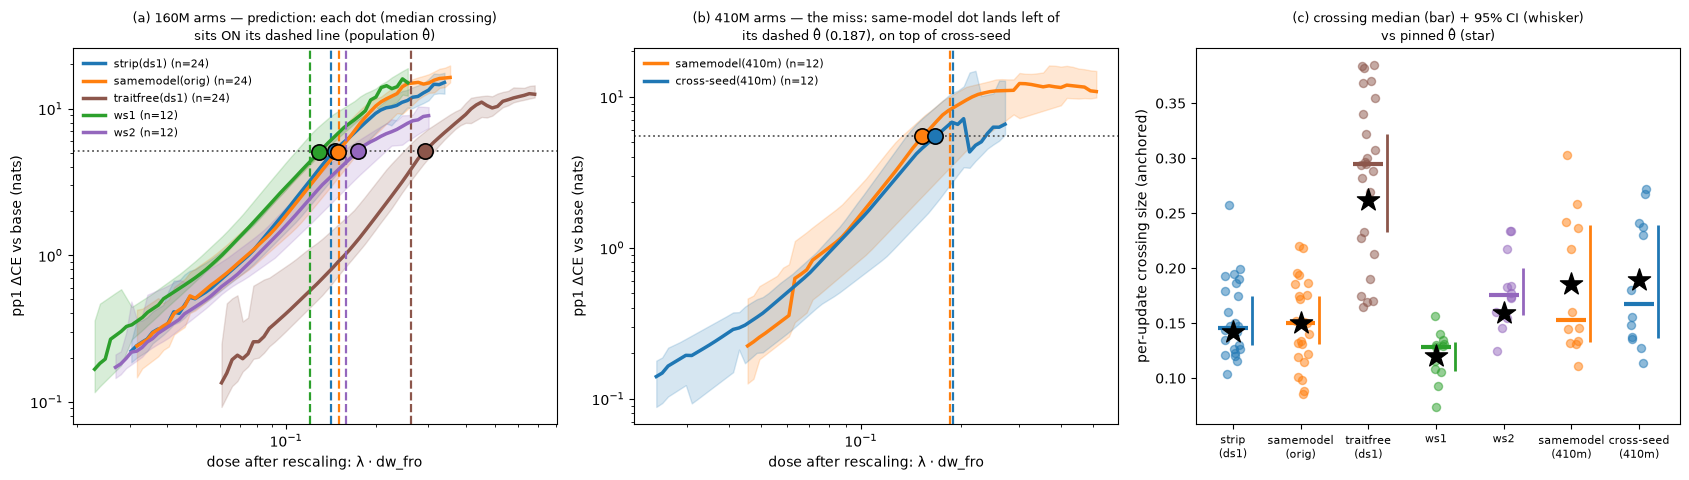

anchored crossing medians: {'cross-seed(410m)': 0.168, 'samemodel(410m)': 0.153, 'samemodel(orig)': 0.15, 'strip(ds1)': 0.146, 'traitfree(ds1)': 0.294, 'ws1': 0.129, 'ws2': 0.175}
θ̂ pins: {'strip(ds1)': 0.142, 'samemodel(orig)': 0.15, 'traitfree(ds1)': 0.262, 'ws1': 0.12, 'ws2': 0.159, 'samemodel(410m)': 0.186, 'cross-seed(410m)': 0.189}
trait-free/strip ratio: 2.02 (predicted ~1.9)
declared 4.0 comparison medians: {'cross-seed(410m)': 0.146, 'samemodel(410m)': 0.137, 'samemodel(orig)': 0.136, 'strip(ds1)': 0.131, 'traitfree(ds1)': 0.267, 'ws1': 0.115, 'ws2': 0.153}


In [19]:
_dose_cache = {}
def dose_of(run):
    if run not in _dose_cache: _dose_cache[run] = pooled_dose(run)
    return _dose_cache[run]
files = [A/'lambda_crossing_arms.jsonl', A/'lambda_crossing_410m.jsonl'] + sorted(A.glob('lambda_crossing_ext_*.jsonl'))
cefiles = sorted(A.glob('lambda_crossing_ce_*.jsonl'))
frames = []
for f in files + cefiles:
    if f.exists() and f.stat().st_size > 0:
        d_ = read_jsonl(f); d_['src'] = f.stem
        d_['is_ce'] = 'delta_ce' in d_.columns
        d_['y'] = d_['delta_ce'] if 'delta_ce' in d_.columns else d_['pile_kl']
        frames.append(d_)
lam = pd.concat(frames, ignore_index=True)
def arm_of(r):
    if '/students/controls/' in r: return 'traitfree(ds1)'
    m = re.search(r'/students/dog/(pythia-[^/]+)/', r)
    return {'pythia-160m': 'samemodel(orig)', 'pythia-160m-data-seed1': 'strip(ds1)',
            'pythia-160m-weight-seed1': 'ws1', 'pythia-160m-weight-seed2': 'ws2',
            'pythia-410m': 'samemodel(410m)', 'pythia-410m-seed1': 'cross-seed(410m)'}[m.group(1)]
lam['arm'] = lam.run.map(arm_of)
BKEY = {'traitfree(ds1)': 'pythia-160m-data-seed1', 'strip(ds1)': 'pythia-160m-data-seed1',
        'samemodel(orig)': 'pythia-160m', 'ws1': 'pythia-160m-weight-seed1',
        'ws2': 'pythia-160m-weight-seed2', 'samemodel(410m)': 'pythia-410m',
        'cross-seed(410m)': 'pythia-410m-seed1'}
lam['cut'] = lam.arm.map(BKEY).map(DCX)
ce_arms = set(lam[lam.is_ce].arm.unique())
lam = pd.concat([lam[lam.arm.isin(ce_arms) & lam.is_ce], lam[~lam.arm.isin(ce_arms)]], ignore_index=True)
present = set(lam.arm.unique())
YLAB6 = KL_LAB if ce_arms >= present else ('pp1 ΔCE (CE-rerun arms) / Pile-KL (legacy arms) vs base (nats)' if ce_arms else 'pp1 Pile-KL vs base (nats)')
print('CE-rerun arms:', sorted(ce_arms) or 'none yet (ce-wave1 pending)')
print('λ-crossing sources loaded:', [fr.src.iloc[0] for fr in frames])
ext_present = sorted(a for a in ('ws1', 'ws2') if a in present)
print('ladders per arm:', lam.groupby('arm').run.nunique().to_dict())
if not ext_present:
    print('extension arms (ws1/ws2): none yet — queue lambda-ext-crossing pending; re-execute after it drains')
# θ̂ pins: current-population anchored refits (08-27 audit; the era pins — 410m 0.187/0.134, ws 0.113/0.141 — were stale)
THETA = {'strip(ds1)': 0.142, 'samemodel(orig)': 0.150, 'traitfree(ds1)': 0.262,
         'ws1': 0.120, 'ws2': 0.159, 'samemodel(410m)': 0.186, 'cross-seed(410m)': 0.189}
LCOL = {'strip(ds1)': 'tab:blue', 'samemodel(orig)': 'tab:orange', 'traitfree(ds1)': 'tab:brown',
        'ws1': 'tab:green', 'ws2': 'tab:purple',
        'samemodel(410m)': 'tab:orange', 'cross-seed(410m)': 'tab:blue'}

def band_panel(ax, arms):
    for a in arms:
        g = lam[lam.arm == a]
        curves_ = []
        for run, gg in g.groupby('run'):
            gg = gg.sort_values('lam')
            x = np.log(gg.lam.values * dose_of(run)); y = np.log(np.maximum(gg.y.values, 1e-3))
            curves_.append((x, y))
        gridlo = float(np.median([c[0].min() for c in curves_])); gridhi = float(np.median([c[0].max() for c in curves_]))
        grid = np.linspace(gridlo, gridhi, 60)
        M = np.full((len(curves_), 60), np.nan)
        for i, (x, y) in enumerate(curves_):
            msk = (grid >= x.min()) & (grid <= x.max())
            M[i, msk] = np.interp(grid[msk], x, y)
        rb = np.random.default_rng(4)
        boots = np.full((400, 60), np.nan)
        for b_ in range(400):
            boots[b_] = np.nanmedian(M[rb.integers(0, len(curves_), len(curves_))], axis=0)
        med = np.exp(np.nanmedian(M, axis=0))
        loB = np.exp(np.nanpercentile(boots, 2.5, axis=0)); hiB = np.exp(np.nanpercentile(boots, 97.5, axis=0))
        cov = (~np.isnan(M)).sum(axis=0) >= max(4, len(curves_) // 2)
        gx = np.exp(grid)
        ax.plot(gx[cov], med[cov], '-', color=LCOL[a], lw=2.5, label=f'{a} (n={len(curves_)})')
        ax.fill_between(gx[cov], loB[cov], hiB[cov], color=LCOL[a], alpha=0.18)
        ax.axvline(THETA[a], color=LCOL[a], ls='--', lw=1.6)
        cut_a = lam[lam.arm == a].cut.iloc[0]
        dm = cc[cc.arm == a].cross.median()
        ax.plot([dm], [cut_a], 'o', color=LCOL[a], ms=11, mec='k', mew=1.2, zorder=5)
    ax.axhline(float(np.median([lam[lam.arm == a].cut.iloc[0] for a in arms])), color='0.35', ls=':', lw=1.3)
    ax.set_xscale('log'); ax.set_yscale('log')
    from matplotlib.ticker import NullFormatter
    ax.xaxis.set_minor_formatter(NullFormatter())
    ax.set_xlabel('dose after rescaling: λ · dw_fro'); ax.set_ylabel(YLAB6)
    ax.legend(fontsize=8, frameon=False, loc='upper left')

def crossings(df_, declared=False):
    rows_ = []
    for run, g in df_.groupby('run'):
        g = g.sort_values('lam')
        cut = DEAD_KL_CUT if declared else g.cut.iloc[0]
        lstar = interp_crossing(list(g.lam.values), list(g.y.values), cut, rising=True)
        if np.isfinite(lstar): rows_.append(dict(arm=g.arm.iloc[0], cross=lstar * dose_of(run)))
    return pd.DataFrame(rows_)
cc = crossings(lam)
arms160 = [a for a in ('strip(ds1)', 'samemodel(orig)', 'traitfree(ds1)', 'ws1', 'ws2') if a in present]
arms410 = [a for a in ('samemodel(410m)', 'cross-seed(410m)') if a in present]
fig, axes = plt.subplots(1, 3, figsize=(17, 4.9))
band_panel(axes[0], arms160)
axes[0].set_title('(a) 160M arms — prediction: each dot (median crossing)\nsits ON its dashed line (population θ̂)', fontsize=9)
band_panel(axes[1], arms410)
axes[1].set_title('(b) 410M arms — the miss: same-model dot lands left of\nits dashed θ̂ (0.187), on top of cross-seed', fontsize=9)
def crossings(df_, declared=False):
    rows_ = []
    for run, g in df_.groupby('run'):
        g = g.sort_values('lam')
        cut = DEAD_KL_CUT if declared else g.cut.iloc[0]
        lstar = interp_crossing(list(g.lam.values), list(g.pile_kl.values), cut, rising=True)
        if np.isfinite(lstar): rows_.append(dict(arm=g.arm.iloc[0], cross=lstar * dose_of(run)))
    return pd.DataFrame(rows_)
cc = crossings(lam)
order = arms160 + arms410
rj = np.random.default_rng(0)
for j, a in enumerate(order):
    v = cc[cc.arm == a].cross.values
    axes[2].scatter(j + rj.uniform(-0.12, 0.12, len(v)), v, s=34, alpha=0.5, color=LCOL[a])
    m, lo, hi = med_ci(v)
    axes[2].hlines(m, j-0.22, j+0.22, color=LCOL[a], lw=3)
    axes[2].vlines(j+0.28, lo, hi, color=LCOL[a], lw=2)
    axes[2].scatter([j], [THETA[a]], marker='*', s=280, color='k', zorder=4)
axes[2].set_xticks(range(len(order)))
axes[2].set_xticklabels([a.replace('(', '\n(') for a in order], fontsize=8)
axes[2].set_ylabel('per-update crossing size (anchored)')
axes[2].set_title('(c) crossing median (bar) + 95% CI (whisker)\nvs pinned θ̂ (star)', fontsize=9)
plt.tight_layout(); fig.savefig(FIGDIR/'fig06_lambda_crossing.png', dpi=180, bbox_inches='tight'); plt.show()
print('anchored crossing medians:', cc.groupby('arm').cross.median().round(3).to_dict())
print('θ̂ pins:', THETA)
if 'traitfree(ds1)' in present and 'strip(ds1)' in present:
    print('trait-free/strip ratio:',
          round(cc[cc.arm=="traitfree(ds1)"].cross.median()/cc[cc.arm=="strip(ds1)"].cross.median(), 2),
          '(predicted ~1.9)')
print('declared 4.0 comparison medians:', crossings(lam, declared=True).groupby('arm').cross.median().round(3).to_dict())

## Figure 7 — §4.3 / §4.4 *The dose map, and size → fate (cross-data-order arm)*

**Construction.** Strip arm throughout (orig-teacher numbers → ds1 receiver, ep20). **(a)**
observed dw_fro vs the single global power-law fit lr^a·α^b·r^c, points colored by α. The
map is *deliberately shown against a straight power law*: the systematic, α-ordered bowing
around the diagonal IS the curvature of §4.4 (the boundary's b-bend inherits it); the global
exponents are the support-weighted average. **(b)** size → fate with the actual data: each
circle is one (lr, α, r) grid cell (its runs' death fraction vs its median size, area ∝
number of runs); the gray rug is every individual run at 0/1 (jittered); the red line is the
run-level logistic fit.

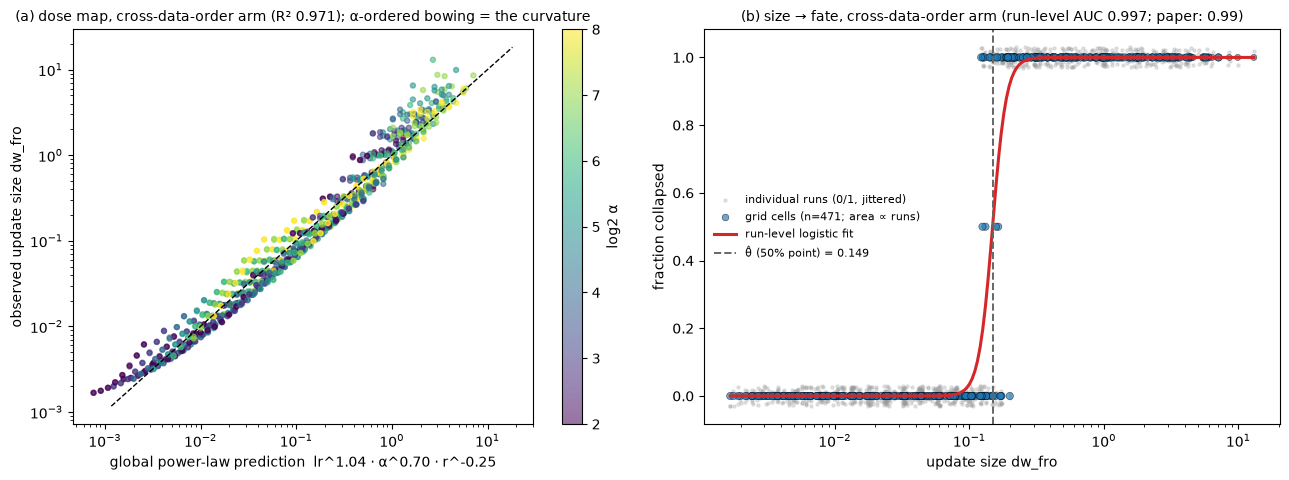

dose map exponents: lr 1.04, α 0.70, r -0.25 (R² 0.971) | run-level dose→fate AUC 0.997


In [20]:
X = sm.add_constant(pd.DataFrame({'llr': np.log(sd.lr), 'la': np.log(sd.alpha), 'lrk': np.log(sd['rank'])}))
fmap = sm.OLS(np.log(sd.dw), X).fit(cov_type='cluster', cov_kwds={'groups': sd.tag})
sd['dw_pred'] = np.exp(fmap.fittedvalues)
auc = roc_auc_score(sd.dead, sd.dw)
lg = sm.Logit(sd.dead.astype(int), sm.add_constant(np.log(sd.dw))).fit(disp=0)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.9))
sc = axes[0].scatter(sd.dw_pred, sd.dw, s=13, alpha=0.55, c=np.log2(sd.alpha), cmap='viridis')
cb = fig.colorbar(sc, ax=axes[0]); cb.set_label('log2 α')
lim = [sd.dw.min()*0.7, sd.dw.max()*1.4]
axes[0].plot(lim, lim, 'k--', lw=1)
axes[0].set_xscale('log'); axes[0].set_yscale('log')
axes[0].set_xlabel(f'global power-law prediction  lr^{fmap.params.llr:.2f} · α^{fmap.params.la:.2f} · r^{fmap.params.lrk:.2f}')
axes[0].set_ylabel('observed update size dw_fro')
axes[0].set_title(f'(a) dose map, cross-data-order arm (R² {fmap.rsquared:.3f}); α-ordered bowing = the curvature', fontsize=10)
cells = sd.groupby('tag').agg(dw=('dw', 'median'), frac=('dead', 'mean'), n=('dead', 'size')).reset_index()
xs = np.geomspace(sd.dw.min(), sd.dw.max(), 200)
rj = np.random.default_rng(2)
axes[1].scatter(sd.dw, sd.dead.astype(float) + rj.uniform(-0.03, 0.03, len(sd)), s=5, color='0.6', alpha=0.25,
                label='individual runs (0/1, jittered)')
axes[1].scatter(cells.dw, cells.frac, s=10 + 9*cells.n, color='tab:blue', alpha=0.65,
                edgecolor='k', lw=0.4, label=f'grid cells (n={len(cells)}; area ∝ runs)')
axes[1].plot(xs, lg.predict(sm.add_constant(np.log(xs))), '-', color='tab:red', lw=2.2, label='run-level logistic fit')
theta50 = np.exp(-lg.params.iloc[0]/lg.params.iloc[1])
axes[1].axvline(theta50, color='0.4', ls='--', lw=1.4, label=f'θ̂ (50% point) = {theta50:.3f}')
axes[1].set_xscale('log'); axes[1].set_xlabel('update size dw_fro'); axes[1].set_ylabel('fraction collapsed')
axes[1].set_title(f'(b) size → fate, cross-data-order arm (run-level AUC {auc:.3f}; paper: 0.99)', fontsize=10)
axes[1].legend(fontsize=8, frameon=False, loc='center left')
plt.tight_layout(); fig.savefig(FIGDIR/'fig07_dose_map_fate.png', dpi=180, bbox_inches='tight'); plt.show()
print(f'dose map exponents: lr {fmap.params.llr:.2f}, α {fmap.params.la:.2f}, r {fmap.params.lrk:.2f} '
      f'(R² {fmap.rsquared:.3f}) | run-level dose→fate AUC {auc:.3f}')

## Figure 8 — §4.4 *[earlier program] Frozen vs learned: share of the full update norm, and the strip component splices*

**Construction.** The update factorizes exactly as ΔW = s·B·A₀ + s·B·ΔA — a *frozen*
component (trained B against the frozen random init A₀) and a *learned* component (trained B
against the trained change ΔA). **(a)** the learned component's share of the **actual full
update norm**, ‖B·ΔA‖_F/‖B·A_final‖_F (pooled over modules; can exceed 1 when the components
cancel), box plots by α over the strip's full-schema runs — learned-dominated at low α,
frozen-dominated at high α: the balance whose motion along α the boundary's b-bend inherits.
**(b)** the strip component splice (`frozen_a_ablation_strip_*`, 8 ranks × 2 seeds over the
whole strip): **trait retention** (excess p(dog) over base prior retained after keeping only
one component; trait-carrying runs, the nors_asks §5.4 readout), box plots by α — the
carrier migrates from the learned to the frozen component as α grows. **(c)** the same
splices read on **pp1 Pile-KL**: full update vs keep-frozen vs keep-learned, box plots by α.
Provenance: earlier-program experiments (A2); the v2 ledger carries only the curvature
statement.

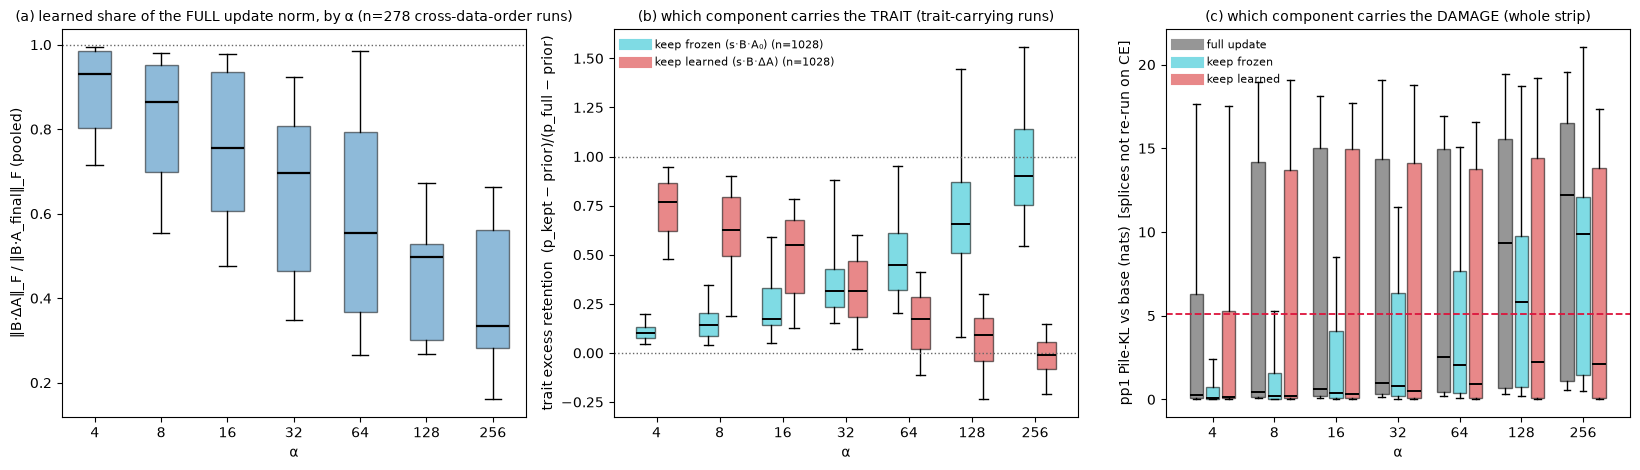

learned share (of full norm) medians by α: {4: 0.93, 8: 0.86, 16: 0.76, 32: 0.7, 64: 0.55, 128: 0.5, 256: 0.33}
trait-carrying splice rows: keep-frozen 1028, keep-learned 1028 (of 1864/1864)


In [21]:
hs = sd.dropna(subset=['dw_frozen', 'dw_learned']).copy()
hs['learned_share'] = hs.dw_learned / hs.dw
def load_strip_splice(which):
    frames_, pb = [], None
    for f in sorted(A.glob(f'frozen_a_ablation_strip_{which}_r*_s*.json')):
        d_ = read_json(f); pb = d_['p_target_base']
        frames_.append(pd.DataFrame(d_['results']))
    return (pd.concat(frames_) if frames_ else pd.DataFrame()), pb
sfz, pb_s = load_strip_splice('frozen')
smv, _ = load_strip_splice('moved')
for fr in (sfz, smv):
    fr['excess_retention'] = (fr.p_target_ablated - pb_s) / (fr.p_target_orig - pb_s)
tcf = sfz[sfz.p_target_orig > 0.02]; tcm = smv[smv.p_target_orig > 0.02]
fig, axes = plt.subplots(1, 3, figsize=(16.5, 4.8))
al = sorted(hs.alpha.unique()); pos = np.arange(len(al), dtype=float)
bp = axes[0].boxplot([hs.loc[hs.alpha == a_, 'learned_share'].values for a_ in al],
                     positions=pos, widths=0.5, whis=(5, 95), showfliers=False,
                     patch_artist=True, medianprops=dict(color='black', lw=1.6))
for b_ in bp['boxes']: b_.set(facecolor='tab:blue', alpha=0.5)
axes[0].axhline(1.0, color='0.4', ls=':', lw=1)
axes[0].set_xticks(pos); axes[0].set_xticklabels(al)
axes[0].set_xlabel('α'); axes[0].set_ylabel('‖B·ΔA‖_F / ‖B·A_final‖_F (pooled)')
axes[0].set_title(f'(a) learned share of the FULL update norm, by α (n={len(hs)} cross-data-order runs)', fontsize=10)
al2 = sorted(set(tcf.alpha) | set(tcm.alpha)); pos2 = np.arange(len(al2), dtype=float)
for lab, frame, color, off in (('keep frozen (s·B·A₀)', tcf, 'tab:cyan', -0.18),
                               ('keep learned (s·B·ΔA)', tcm, 'tab:red', 0.18)):
    data = [frame.loc[frame.alpha == a_, 'excess_retention'].dropna().values for a_ in al2]
    bp = axes[1].boxplot(data, positions=pos2 + off, widths=0.3, whis=(5, 95), showfliers=False,
                         patch_artist=True, medianprops=dict(color='black', lw=1.4))
    for b_ in bp['boxes']: b_.set(facecolor=color, alpha=0.55)
    axes[1].plot([], [], color=color, lw=8, alpha=0.55, label=f'{lab} (n={sum(len(d_) for d_ in data)})')
axes[1].axhline(1.0, color='0.4', ls=':', lw=1); axes[1].axhline(0.0, color='0.4', ls=':', lw=1)
axes[1].set_xticks(pos2); axes[1].set_xticklabels(al2)
axes[1].set_xlabel('α'); axes[1].set_ylabel('trait excess retention  (p_kept − prior)/(p_full − prior)')
axes[1].set_title('(b) which component carries the TRAIT (trait-carrying runs)', fontsize=10)
axes[1].legend(fontsize=8, frameon=False)
for lab, ser_by_a, color, off in (('full update', sfz.groupby('alpha').pile_kl_base_orig, '0.25', -0.26),
                                  ('keep frozen', sfz.groupby('alpha').pile_kl_base_ablated, 'tab:cyan', 0.0),
                                  ('keep learned', smv.groupby('alpha').pile_kl_base_ablated, 'tab:red', 0.26)):
    data = [ser_by_a.get_group(a_).dropna().values if a_ in ser_by_a.groups else np.array([]) for a_ in al2]
    bp = axes[2].boxplot([d_ for d_ in data], positions=pos2 + off, widths=0.22, whis=(5, 95), showfliers=False,
                         patch_artist=True, medianprops=dict(color='black', lw=1.4))
    for b_ in bp['boxes']: b_.set(facecolor=color, alpha=0.55)
    axes[2].plot([], [], color=color, lw=8, alpha=0.55, label=lab)
axes[2].axhline(DC_DS1, color='crimson', ls='--', lw=1.3)
axes[2].set_xticks(pos2); axes[2].set_xticklabels(al2)
axes[2].set_xlabel('α'); axes[2].set_ylabel('pp1 Pile-KL vs base (nats)  [splices not re-run on CE]')
axes[2].set_title('(c) which component carries the DAMAGE (whole strip)', fontsize=10)
axes[2].legend(fontsize=8, frameon=False, loc='upper left')
plt.tight_layout(); fig.savefig(FIGDIR/'fig08_frozen_learned.png', dpi=180, bbox_inches='tight'); plt.show()
print('learned share (of full norm) medians by α:', hs.groupby('alpha').learned_share.median().round(2).to_dict())
print(f'trait-carrying splice rows: keep-frozen {len(tcf)}, keep-learned {len(tcm)} (of {len(sfz)}/{len(smv)})')

## Table 3 — §4.4 *The fits themselves: boundary exponents (full grid + matched cells), dose maps, thresholds*

**Construction.** Self-contained loader over the four §4.4 arms (strip, orig same-model, trait-free,
SGD): per-run `eval/pile_probe.json` (ΔCE primary; ANCHORED unigram cut operative, declared KL > 4
as comparison columns) and `eval/adapter_norms.json` (pooled dose `dw_fro`, module-mean
`(α/r)·‖B·A_final‖_F/‖W₀‖_F`), ep20 cells only. Row units are stated on each table. Estimators:
**3a** `cl.fit_collapse_law` — seed-level logit of P(dead) on [ln lr, ln α, ln r], cluster-robust by
cell, delta-method 95% CIs on b = β_α/β_lr and c = β_r/β_lr — fit per arm on its full grid AND on
the **matched-cell set** (the evaluated (lr, r, α) cells shared by the three AdamW arms; SGD is its
own coordinate and stays out of the matched comparison); **3b** OLS of ln dw_fro on
[ln lr, ln α, ln r] (all exponents free, label-free, cell-clustered SEs); **3c** `cl.theta_dose` —
the logistic 50% crossing θ̂ on ln dw_fro with Mann-Whitney AUC, plus `cl.kstar_logistic` K* in the
arm's own anchored (b, c) coordinate (not comparable across optimizers). **Teachers**: the upstream stage enters as the **dog|orig wide tree only** (4,735 ftseed1 runs
— the one identifiability-adequate teacher support; the narrow 288–450-tag trees are
support-artifacts and are never cited, per `collapse_teachers.ipynb` §3b). In 3a the teacher rows
use the students' 3-term estimator like-for-like (steps pooled, and the ep20-only subset as the
closest match to the students' grid); the teacher-native 4-term law (with log-steps) lives in
`collapse_teachers.ipynb` §3. In 3b the teacher dose map carries the extra steps axis
(steps = 3·ep). In 3c teachers get θ̂ only — the teacher K\* is budget-dependent (K\*(T),
`collapse_teachers.ipynb` §3) and has no single-number row. Teacher label: the pp1 cut of the
teacher's own base. Few-step caveat: teachers train 3–60 optimizer steps vs the students'
12,500 — a two-regime comparison, and the teacher grid was selection-designed, not law-designed.
**OLMo-1B rows (2026-09-09).** The two DataDecide arms (same-model `dd-1b→dd-1b`, cross-seed
`dd-1b→dd-1b-seed2`; teacher `ep10_lr5e-4_r64a128`, ep10 students, one student seed) enter 3a on
the **OLMo nonadaptive set = 432 cells**: 6 lr {1e-4 … 5e-3} × 9 ranks {1 … 256} × 8 α {4 … 512}
(the 56 Pythia (r, α) pairs plus the α=512 and rank-256 rows, all on the same fixed lr ladder, no
K/K* input) — this is the arms' `full grid` — and, as a second support, on the 336-cell subset
that shares the Pythia (r, α) pairs. Their label is the dp1 (Dolma) anchored cut of each receiver; `_decl` is the same
declared KL > 4. They are ep10 and single-seed, so they are not in the matched-cell set, and in
3b/3c their dose rows cover only the 336 core cells that have `adapter_norms.json`.
CSVs:
`table3a_boundary_fits.csv`, `table3b_dose_maps.csv`, `table3c_thresholds.csv`.

In [22]:
# Table 3 loader — per-run rows for the four student arms + the teacher wide tree (~5 min on cold-1)
from subliminal_learning.analysis import collapse_law as cl
from subliminal_learning.param_tags import is_canonical_tag
T3_ARMS = {
    'cross data order': ('students/dog/pythia-160m-data-seed1/teacher-pythia-160m/ep2_lr5e-4_r32a64_tseed1/ex10-20_prefix_n100k',
              'pythia-160m-data-seed1', 'ep20_*/ftseed*'),
    'orig same-model': ('students/dog/pythia-160m/teacher-pythia-160m/ep2_lr5e-4_r32a64_tseed1/ex10-20_prefix_n100k',
                        'pythia-160m', 'ep20_*/ftseed*'),
    'trait-free': ('students/controls/base/pythia-160m-data-seed1/teacher-pythia-160m/ex10-20_prefix_n100k',
                   'pythia-160m-data-seed1', 'ep20_*/ftseed*'),
    'SGD': ('students/sgd/dog/pythia-160m/teacher-pythia-160m/ep2_lr5e-4_r32a64_tseed1/ex10-20_prefix_n100k',
            'pythia-160m', 'ep20_*/ftseed*'),
    'teachers (dog|orig)': ('teachers/dog/pythia-160m', 'pythia-160m', '*/ftseed1'),
    # OLMo-1B (DataDecide) arms, 2026-09-09: ep10 students of the default-seed r64a128 teacher, ftseed 1
    'OLMo-1B same-model': ('students/elephant/DataDecide-dolma1_7-1B-seed-default/teacher-DataDecide-dolma1_7-1B-seed-default/ep10_lr5e-4_r64a128_tseed0/ex10-20_prefix_n100k',
                           'DataDecide-dolma1_7-1B-seed-default', 'ep10_*/ftseed1'),
    'OLMo-1B cross-seed 2': ('students/elephant/DataDecide-dolma1_7-1B-seed-large-aux-2/teacher-DataDecide-dolma1_7-1B-seed-default/ep10_lr5e-4_r64a128_tseed0/ex10-20_prefix_n100k',
                             'DataDecide-dolma1_7-1B-seed-large-aux-2', 'ep10_*/ftseed1'),
}
T3_OLMO = ['OLMo-1B same-model', 'OLMo-1B cross-seed 2']
# the alpha=512 and rank-256 rows of the OLMo nonadaptive set (96 of its 432 cells); ~bext = the 336-cell Pythia-pair subset
OLMO_BEXT = set(read_json(REPO / 'run_logs/dd1b/bext_cells.json')['cells'])
def _t3_load(rel, base, pat, population=None):
    cut = DCX[base]; rows = []
    # Teacher trees carry arm cells beside the canonical ones since 2026-09-14 (`_sgd`, `_noeos`,
    # `_stop{N}` tags): an Adam glob keeps canonical tags only, an SGD glob (pattern `*_sgd/...`)
    # keeps only `_sgd` tags. Student trees are already segregated by directory.
    want_sgd = pat.split('/')[0].endswith('_sgd')
    for pp_p in (OUT/rel).glob(pat + '/eval/pile_probe.json'):
        rd = pp_p.parent.parent
        if rel.startswith('teachers/') and (is_canonical_tag(rd.parent.name) == want_sgd): continue
        if population is not None and f'{rd.parent.name}/{rd.name}' not in population: continue
        try:
            pp = json.loads(pp_p.read_text())
        except Exception:
            continue
        dce, kl = pp.get('delta_ce'), pp.get('kl_base_student')
        prim = dce if (dce is not None and np.isfinite(dce)) else kl
        if prim is None or not np.isfinite(prim): continue
        try:
            dw = pooled_dose(rd)
        except Exception:
            dw = np.nan
        pt = parse_param_tag(rd.parent.name)
        rows.append(dict(student_tag=rd.parent.name, seed=rd.name, ep=int(pt['epochs']),
                         lr=float(pt['lr']), rank=int(pt['rank']), alpha=int(pt['alpha']),
                         dce=prim, kl=kl, dw_fro=dw, dead_anch=int(prim > cut),
                         dead_decl=int((kl if (kl is not None and np.isfinite(kl)) else prim) > DEAD_KL_CUT)))
    df = pd.DataFrame(rows)
    df['cell'] = list(zip(df.lr, df['rank'], df.alpha))
    return df
# cross data order = the designed non-adaptive population only (CDO_POP, defined with Fig 7's loader)
T3 = {k: _t3_load(*v, population=(CDO_POP if k == 'cross data order' else None)) for k, v in T3_ARMS.items()}
T3_ADAM = ['cross data order', 'orig same-model', 'trait-free']
T3_TEACH = 'teachers (dog|orig)'
T3_SHARED = set.intersection(*[set(T3[k].cell) for k in T3_ADAM])
for k, df in T3.items():
    print(f"{k:>20s}: {len(df)} probed runs, {df.student_tag.nunique()} cells, "
          f"{df.dead_anch.sum()} dead (anch) / {df.dead_decl.sum()} (decl); "
          f"finite dose {int(np.isfinite(df.dw_fro).sum())}")
print(f"matched-cell set (evaluated (lr, r, α) shared by the three AdamW student arms): {len(T3_SHARED)} cells")

    cross data order: 932 probed runs, 471 cells, 388 dead (anch) / 397 (decl); finite dose 932
     orig same-model: 597 probed runs, 514 cells, 282 dead (anch) / 300 (decl); finite dose 597
          trait-free: 599 probed runs, 475 cells, 190 dead (anch) / 197 (decl); finite dose 599
                 SGD: 848 probed runs, 848 cells, 367 dead (anch) / 387 (decl); finite dose 383
 teachers (dog|orig): 4808 probed runs, 4808 cells, 1283 dead (anch) / 1341 (decl); finite dose 4808
  OLMo-1B same-model: 432 probed runs, 432 cells, 203 dead (anch) / 207 (decl); finite dose 432
OLMo-1B cross-seed 2: 432 probed runs, 432 cells, 208 dead (anch) / 209 (decl); finite dose 432
matched-cell set (evaluated (lr, r, α) shared by the three AdamW student arms): 458 cells


In [23]:
# Table 3a — boundary-law exponents. Row unit: one arm × support (students: full grid vs matched
# cells; teachers: the wide dog|orig tree, students' 3-term estimator like-for-like, pooled-ep and
# ep20-only supports — the teacher-native 4-term law with log-steps is in collapse_teachers §3).
# Every probed seed-run of the support enters; anchored label operative, '_decl' = declared KL>4.
rows = []
def _fit_row(k, df, support):
    f = cl.fit_collapse_law(df.assign(collapsed=df.dead_anch))
    try:   # declared KL>4 is comparison-only; a singular fit there (e.g. OLMo dp1 subsets) must not block the table
        fd = cl.fit_collapse_law(df.assign(collapsed=df.dead_decl))
    except np.linalg.LinAlgError:
        fd = type('F', (), dict(b=np.nan, c=np.nan))()
    rows.append({'arm': k, 'support': support, 'b': f.b, 'b_lo': f.b_ci[0], 'b_hi': f.b_ci[1],
                 'c': f.c, 'c_lo': f.c_ci[0], 'c_hi': f.c_ci[1], 'b_decl': fd.b, 'c_decl': fd.c,
                 'runs': f.n_runs, 'cells': f.n_cells, 'dead': f.n_dead})
for k in [*T3_ADAM, 'SGD']:
    _fit_row(k, T3[k], 'full grid')
for k in T3_ADAM:
    d = T3[k][T3[k].cell.isin(T3_SHARED)]
    _fit_row(k, d, f'matched ({len(T3_SHARED)} cells)')
# OLMo-1B arms: 'full grid' = the OLMo nonadaptive set (432 cells: 6 lr x 9 ranks x 8 alpha); second row = its
# 336-cell subset on the Pythia (r, alpha) pairs. Single student seed, ep10, dp1 anchored label.
for k in T3_OLMO:
    _fit_row(k, T3[k], 'full grid')
    _fit_row(k, T3[k][~T3[k].student_tag.isin(OLMO_BEXT)], 'Pythia-pair subset (336)')
# Teacher rows: the teacher logit is near-separable, so plain MLE stalls — use the
# ridge-stabilised GLM of collapse_teachers §3 (alpha=1e-3, L2); point ratios only, CIs
# (bootstrap) live in collapse_teachers.
def _ridge_bc(df, col):
    y = df[col].to_numpy()
    X = sm.add_constant(np.c_[np.log(df.lr), np.log(df.alpha), np.log(df['rank'])])
    r = sm.GLM(y, X, family=sm.families.Binomial()).fit_regularized(alpha=1e-3, L1_wt=0.0)
    p = np.asarray(r.params)
    return p[2] / p[1], p[3] / p[1]
def _teach_row(k, df, support):
    b, c_ = _ridge_bc(df, 'dead_anch')
    bd, cd = _ridge_bc(df, 'dead_decl')
    rows.append({'arm': k, 'support': support, 'b': b, 'b_lo': np.nan, 'b_hi': np.nan,
                 'c': c_, 'c_lo': np.nan, 'c_hi': np.nan, 'b_decl': bd, 'c_decl': cd,
                 'runs': len(df), 'cells': int(df.student_tag.nunique()),
                 'dead': int(df.dead_anch.sum())})
tt = T3[T3_TEACH]
_teach_row(T3_TEACH, tt, 'wide tree, all ep (3-term ridge)')
_teach_row(T3_TEACH, tt[tt.ep == 20], 'wide tree, ep20 only (3-term ridge)')
# Same-estimator teacher rows (Angela, 09-01): the ep20 slice on the strip lattice is not near-separable — cl.fit_collapse_law converges — so the teacher
# stage gets the students' estimator, with CIs, at fully matched support.
# Support = the 504-cell teacher nonadaptive set (the strip lattice), selected by its factors, NOT by the
# cross-data-order frame's cells: that frame drops diverged student runs, which would silently remove the
# 33-cell high-dose corner. ep20 and ep5 are both complete (504/504) since the 2026-09-14 fill.
_lat = (tt.lr.apply(lambda v: any(abs(v - x) / x < 1e-9 for x in F1_LAT_LR))
        & tt.alpha.isin([4, 8, 16, 32, 64, 128, 256]) & tt['rank'].isin([1, 2, 4, 8, 16, 32, 64, 128]))
_fit_row(T3_TEACH, tt[_lat & (tt.ep == 20)], "ep20, teacher nonadaptive set (same estimator)")
_fit_row(T3_TEACH, tt[_lat & (tt.ep == 5)], "ep5, teacher nonadaptive set (same estimator)")
t3a = pd.DataFrame(rows)
t3a.to_csv(FIGDIR/'table3a_boundary_fits.csv', index=False)
_fmt = {c: '{:.3f}' for c in ['b','b_lo','b_hi','c','c_lo','c_hi','b_decl','c_decl']}
display(t3a.style.format(_fmt)
        .background_gradient(subset=['b'], cmap='Blues', vmin=0.5, vmax=0.8)
        .background_gradient(subset=['c'], cmap='RdBu', vmin=-0.7, vmax=0.7))
print("Read: on the matched-cell set the three AdamW arms' b agree (overlapping 95% CIs) — the")
print("OLMo-1B (ep10, dp1 label): b~0.50 on the 432-cell set and on its 336 Pythia-pair subset, c near 0 (rank barely protective),")
print("same-model and cross-seed 2 agree -- the alpha exponent is model-invariant at this level, the rank term is not.")
print("apparent full-grid spread is support composition. c agrees between cross data order and same-model but")
print("is ~0 on trait-free (CI spans 0: rank protection is absent on untuned-base data). SGD is its")
print("own coordinate, c ≈ -b. Teacher rows are like-for-like 3-term fits on the wide dog|orig")
print("tree (steps pooled / ep20-only, ridge-stabilised — near-separable logit; bootstrap CIs")
print("in collapse_teachers §3); the steps axis moves to Table 3b.")

,arm,support,b,b_lo,b_hi,c,c_lo,c_hi,b_decl,c_decl,runs,cells,dead
0,cross data order,full grid,0.659,0.604,0.715,-0.164,-0.214,-0.113,0.641,-0.139,932,471,388
1,orig same-model,full grid,0.639,0.588,0.691,-0.149,-0.196,-0.103,0.654,-0.135,597,514,282
2,trait-free,full grid,0.667,0.619,0.715,-0.045,-0.090,-0.001,0.680,-0.049,599,475,190
3,SGD,full grid,0.626,0.577,0.674,-0.661,-0.703,-0.619,0.605,-0.646,848,848,367
4,cross data order,matched (458 cells),0.659,0.604,0.715,-0.164,-0.214,-0.113,0.641,-0.139,913,458,369
5,orig same-model,matched (458 cells),0.682,0.619,0.746,-0.150,-0.195,-0.106,0.676,-0.127,541,458,250
6,trait-free,matched (458 cells),0.667,0.618,0.716,-0.045,-0.090,-0.000,0.680,-0.049,552,458,182
7,OLMo-1B same-model,full grid,0.499,0.472,0.526,-0.059,-0.080,-0.037,0.498,-0.054,432,432,203
8,OLMo-1B same-model,Pythia-pair subset (336),0.490,-1255.448,1256.427,-0.019,-0.019,-0.019,0.490,-0.023,336,336,146
9,OLMo-1B cross-seed 2,full grid,0.507,0.492,0.523,-0.038,-0.050,-0.026,0.504,-0.037,432,432,208


Read: on the matched-cell set the three AdamW arms' b agree (overlapping 95% CIs) — the
OLMo-1B (ep10, dp1 label): b~0.50 on the 432-cell set and on its 336 Pythia-pair subset, c near 0 (rank barely protective),
same-model and cross-seed 2 agree -- the alpha exponent is model-invariant at this level, the rank term is not.
apparent full-grid spread is support composition. c agrees between cross data order and same-model but
is ~0 on trait-free (CI spans 0: rank protection is absent on untuned-base data). SGD is its
own coordinate, c ≈ -b. Teacher rows are like-for-like 3-term fits on the wide dog|orig
tree (steps pooled / ep20-only, ridge-stabilised — near-separable logit; bootstrap CIs
in collapse_teachers §3); the steps axis moves to Table 3b.


### Table 3a-T — teacher boundary exponents across families and optimizers (§4.4 companion)

Row unit: one **teacher** nonadaptive set × epoch budget × optimizer, every family on its own lattice and
anchored label (`DCX[base]`: pp1 for Pythia, dp1 for OLMo, pp1t-qwen25 for Qwen), teacher seed 1 (Pythia) or 0
(OLMo, Qwen). Same 3-term estimator as the student rows (`cl.fit_collapse_law`, cluster-robust 95 % CIs, ratios
$b = \beta_\alpha/\beta_{\mathrm{lr}}$, $c = \beta_r/\beta_{\mathrm{lr}}$). Sets:

- **Pythia-160m Adam** — the 504-cell teacher nonadaptive set (9 lr × 56 pairs), ep5 and ep20 (the same rows as Table 3a).
- **Pythia-160m SGD** — plain SGD (no momentum), 16 one-significant-figure rungs 1e-3…1e2 × 56 pairs, ep5 and ep20 (2026-09-14).
- **OLMo-1B Adam** — the 432-cell teacher set (6 lr × 9 ranks × 8 alphas), ep5/10/20 (2026-09-14).
- **Qwen2.5-1.5B Adam** — the 432-cell teacher set, ep5/10/20, plus the *set + interleave* support at ep10/20
  (four one-significant-figure interleave rungs of the same window, 720 cells): the 432-cell sets are exactly
  separable under the anchored label (a cliff-like family on a ×2–2.5 lattice), so their logit has no point
  estimate; the uniform densification restores one without placing cells relative to any observed crossing.

Columns: `runs`/`cells`/`dead` as in Table 3a; `b`, `c` with CIs (NaN where the logit has no point estimate);
`min_err` = fewest cells a single threshold on $K$ misclassifies over a fine $(b, c)$ grid, and `region_b`,
`region_c` = the $(b, c)$ ranges achieving that minimum or one more — the set-valued readout that exists for
every row and, where a logit exists, overlaps its interval; `bracketed` = (rank, alpha) columns with at least
one alive and one dead rung (edge-limited rows have many unbracketed columns and are flagged in `note`).

In [24]:
# Table 3a-T — teacher boundary exponents, all families × optimizers × epoch budgets (2026-09-15)
_BG = np.round(np.arange(0, 1.501, 0.01), 2); _CG = np.round(np.arange(-1, 0.601, 0.01), 2)
def _minerr_region(df):
    y = df.dead_anch.to_numpy(); L = np.log(df.lr.to_numpy()); A_ = np.log(df.alpha.to_numpy()); R = np.log(df['rank'].to_numpy())
    err = np.full((len(_BG), len(_CG)), 10**6)
    for i, b in enumerate(_BG):
        for j, c_ in enumerate(_CG):
            ys = y[np.argsort(L + b * A_ + c_ * R)]
            db = np.concatenate([[0], np.cumsum(ys)]); aa = (len(ys) - ys.sum()) - np.concatenate([[0], np.cumsum(1 - ys)])
            err[i, j] = int((db + aa).min())
    m = err.min(); ii, jj = np.where(err <= m + 1)
    return int(m), f'[{_BG[ii].min():.2f}, {_BG[ii].max():.2f}]', f'[{_CG[jj].min():+.2f}, {_CG[jj].max():+.2f}]'
def _bracketed(df):
    n = 0
    for _, g in df.groupby(['rank', 'alpha']):
        n += int((g.dead_anch == 0).any() and (g.dead_anch == 1).any())
    return n, df.groupby(['rank', 'alpha']).ngroups
def _on(df, lrs, ranks, alphas):
    return df[df.lr.apply(lambda v: any(abs(v - x) / x < 1e-9 for x in lrs)) & df['rank'].isin(ranks) & df.alpha.isin(alphas)]
trows = []
def _trow(family, optim, ep, support, df):
    row = {'family': family, 'optimizer': optim, 'epochs': ep, 'support': support, 'runs': len(df),
           'cells': int(df.student_tag.nunique()), 'dead': int(df.dead_anch.sum())}
    if df.dead_anch.nunique() < 2 or row['dead'] < 20:
        row['note'] = 'not fitted (< 20 dead)'; trows.append(row); return
    try:
        f = cl.fit_collapse_law(df.assign(collapsed=df.dead_anch))
        row.update(b=f.b, b_lo=f.b_ci[0], b_hi=f.b_ci[1], c=f.c, c_lo=f.c_ci[0], c_hi=f.c_ci[1], converged=f.converged)
    except np.linalg.LinAlgError:
        row['note'] = 'no logit point estimate (classes separable) -- region columns'
    m, rb, rc = _minerr_region(df); row.update(min_err=m, region_b=rb, region_c=rc)
    nb_, nc_ = _bracketed(df); row.update(bracketed=f'{nb_}/{nc_}')
    if nb_ < 0.8 * nc_:
        row['note'] = (row.get('note', '') + '; ' if row.get('note') else '') + 'edge-limited: boundary beyond the lattice for many columns'
    trows.append(row)
_P_R, _P_A = [1, 2, 4, 8, 16, 32, 64, 128], [4, 8, 16, 32, 64, 128, 256]
_X_R, _X_A = [1, 2, 4, 8, 16, 32, 64, 128, 256], [4, 8, 16, 32, 64, 128, 256, 512]
# Pythia-160m: Adam (504-cell set, the Table 3a rows) and SGD (16-rung lattice)
_ptA = T3[T3_TEACH]
for ep in (5, 20):
    _trow('Pythia-160m', 'AdamW', ep, '504-cell set (9 lr)', _on(_ptA[_ptA.ep == ep], F1_LAT_LR, _P_R, _P_A))
_ptS = _t3_load('teachers/dog/pythia-160m', 'pythia-160m', '*_sgd/ftseed1')
_sgd_lrs = [1e-3, 2e-3, 5e-3, 1e-2, 2e-2, 5e-2, 1e-1, 2e-1, 5e-1, 1, 2, 5, 10, 20, 50, 100]
for ep in (5, 20):
    _trow('Pythia-160m', 'SGD', ep, '896-cell set (16 lr)', _on(_ptS[_ptS.ep == ep], _sgd_lrs, _P_R, _P_A))
# OLMo-1B (dd-1b default seed), Adam, 432-cell set
_ot = _t3_load('teachers/elephant/DataDecide-dolma1_7-1B-seed-default', 'DataDecide-dolma1_7-1B-seed-default', '*/ftseed0')
for ep in (5, 10, 20):
    _trow('OLMo-1B', 'AdamW', ep, '432-cell set (6 lr)', _on(_ot[_ot.ep == ep], [1e-4, 2e-4, 5e-4, 1e-3, 2e-3, 5e-3], _X_R, _X_A))
# Qwen2.5-1.5B, Adam, 432-cell set (+ the 4-rung interleave at ep10/20)
_qt = _t3_load('teachers/panda/Qwen2.5-1.5B', 'Qwen2.5-1.5B', '*/ftseed0')
_q_lrs, _q_il = [2e-5, 5e-5, 1e-4, 2e-4, 5e-4, 1e-3], [3e-5, 7e-5, 3e-4, 7e-4]
for ep in (5, 10, 20):
    _trow('Qwen2.5-1.5B', 'AdamW', ep, '432-cell set (6 lr)', _on(_qt[_qt.ep == ep], _q_lrs, _X_R, _X_A))
    if ep in (10, 20):
        _trow('Qwen2.5-1.5B', 'AdamW', ep, 'set + interleave (10 lr, 720 cells)', _on(_qt[_qt.ep == ep], _q_lrs + _q_il, _X_R, _X_A))
t3aT = pd.DataFrame(trows)
t3aT.to_csv(FIGDIR / 'table3a_teacher_fits.csv', index=False)
_fmtT = {c: '{:.3f}' for c in ['b', 'b_lo', 'b_hi', 'c', 'c_lo', 'c_hi']}
display(t3aT.style.format(_fmtT, na_rep='—')
        .background_gradient(subset=['b'], cmap='Blues', vmin=0.3, vmax=0.9)
        .background_gradient(subset=['c'], cmap='RdBu', vmin=-1.0, vmax=1.0)
        .set_caption('Table 3a-T: teacher boundary exponents by family, optimizer and epoch budget (anchored label; same estimator as Table 3a; region = set-valued readout)'))
print("Read: Adam teachers land at b ~0.6-0.65 with c ~ 0 on OLMo and Qwen at ep10/ep20 (Pythia ep20 c -0.12 is the only rank-protection")
print("signal); the ep20 teacher K* sits on each family's student K* in the student coordinate (teacher_nonadaptive_olmo_qwen.ipynb).")
print("Pythia SGD teachers: c ~ -b at ep5 (0.70/-0.71) but rank-dominated at ep20 (0.42/-0.94); every column bracketed on the 16-rung lattice.")
print("ep5 rows of OLMo and Qwen are edge-limited (boundary above the top rung for many columns) -- compare ep10/ep20 only.")


,family,optimizer,epochs,support,runs,cells,dead,b,b_lo,b_hi,c,c_lo,c_hi,converged,min_err,region_b,region_c,bracketed,note
0,Pythia-160m,AdamW,5,504-cell set (9 lr),504,504,165,0.714,0.668,0.761,-0.062,-0.101,-0.023,True,2,"[0.65, 0.75]","[-0.06, -0.01]",56/56,—
1,Pythia-160m,AdamW,20,504-cell set (9 lr),504,504,249,0.657,0.608,0.706,-0.121,-0.157,-0.086,True,5,"[0.55, 0.72]","[-0.17, -0.06]",56/56,—
2,Pythia-160m,SGD,5,896-cell set (16 lr),792,792,328,0.702,0.613,0.791,-0.709,-0.790,-0.628,True,24,"[0.71, 0.77]","[-0.77, -0.73]",56/56,—
3,Pythia-160m,SGD,20,896-cell set (16 lr),748,748,334,0.421,0.311,0.530,-0.938,-1.032,-0.844,True,35,"[0.32, 0.36]","[-0.74, -0.73]",56/56,—
4,OLMo-1B,AdamW,5,432-cell set (6 lr),432,432,90,0.817,0.699,0.934,-0.021,-0.081,0.039,True,11,"[0.84, 1.10]","[-0.12, +0.09]",42/72,edge-limited: boundary beyond the lattice for many columns
5,OLMo-1B,AdamW,10,432-cell set (6 lr),432,432,148,0.578,0.478,0.678,-0.015,-0.094,0.063,True,37,"[0.51, 0.59]","[+0.01, +0.08]",62/72,—
6,OLMo-1B,AdamW,20,432-cell set (6 lr),432,432,204,0.600,0.523,0.677,-0.024,-0.077,0.029,True,16,"[0.48, 0.66]","[-0.04, +0.04]",66/72,—
7,Qwen2.5-1.5B,AdamW,5,432-cell set (6 lr),432,432,70,0.663,0.581,0.745,0.074,0.016,0.131,True,5,"[0.63, 0.71]","[+0.06, +0.10]",39/72,edge-limited: boundary beyond the lattice for many columns
8,Qwen2.5-1.5B,AdamW,10,432-cell set (6 lr),432,432,114,—,—,—,—,—,—,—,1,"[0.59, 0.66]","[-0.04, -0.01]",54/72,no logit point estimate (classes separable) -- region columns; edge-limited: boundary beyond the lattice for many columns
9,Qwen2.5-1.5B,AdamW,10,"set + interleave (10 lr, 720 cells)",720,720,187,0.646,0.615,0.676,-0.028,-0.044,-0.013,True,2,"[0.59, 0.66]","[-0.04, +0.00]",54/72,edge-limited: boundary beyond the lattice for many columns


Read: Adam teachers land at b ~0.6-0.65 with c ~ 0 on OLMo and Qwen at ep10/ep20 (Pythia ep20 c -0.12 is the only rank-protection
signal); the ep20 teacher K* sits on each family's student K* in the student coordinate (teacher_nonadaptive_olmo_qwen.ipynb).
Pythia SGD teachers: c ~ -b at ep5 (0.70/-0.71) but rank-dominated at ep20 (0.42/-0.94); every column bracketed on the 16-rung lattice.
ep5 rows of OLMo and Qwen are edge-limited (boundary above the top rung for many columns) -- compare ep10/ep20 only.


In [25]:
# Table 3b — dose-map fits, ALL exponents free (label-free). Row unit: one arm; every probed run
# with a finite pooled dose enters; OLS of ln dw_fro on [ln lr, ln α, ln r] (+ ln steps for the
# teacher arm, steps = 3·ep — the axis its tree actually varies), cell-clustered SEs.
rows = []
for k, df in T3.items():
    d = df[np.isfinite(df.dw_fro) & (df.dw_fro > 0)]
    cols = [np.log(d.lr), np.log(d.alpha), np.log(d['rank'])]
    if k == T3_TEACH:
        cols.append(np.log(3.0 * d.ep))
    X = sm.add_constant(np.c_[tuple(cols)])
    res = sm.OLS(np.log(d.dw_fro).to_numpy(), X).fit(
        cov_type='cluster', cov_kwds={'groups': d.student_tag.to_numpy()})
    p, ci = np.asarray(res.params), np.asarray(res.conf_int())
    row = {'arm': k, 'lr_exp': p[1], 'lr_lo': ci[1][0], 'lr_hi': ci[1][1],
           'alpha_exp': p[2], 'alpha_lo': ci[2][0], 'alpha_hi': ci[2][1],
           'rank_exp': p[3], 'rank_lo': ci[3][0], 'rank_hi': ci[3][1],
           'steps_exp': p[4] if len(p) > 4 else np.nan,
           'steps_lo': ci[4][0] if len(p) > 4 else np.nan,
           'steps_hi': ci[4][1] if len(p) > 4 else np.nan,
           'R2': res.rsquared, 'n': len(d)}
    rows.append(row)
t3b = pd.DataFrame(rows)
t3b['alpha_norm'] = t3b.alpha_exp / t3b.lr_exp
t3b['rank_norm'] = t3b.rank_exp / t3b.lr_exp
if 'steps_exp' in t3b.columns:
    t3b['steps_norm'] = t3b.steps_exp / t3b.lr_exp

t3b.to_csv(FIGDIR/'table3b_dose_maps.csv', index=False)
display(t3b.style.format({c: '{:.3f}' for c in t3b.columns if c not in ('arm', 'n')}, na_rep='—')
        .background_gradient(subset=['alpha_exp'], cmap='Blues', vmin=0.6, vmax=1.0)
        .background_gradient(subset=['rank_exp'], cmap='RdBu', vmin=-1.0, vmax=1.0))
print("Read: the three AdamW student arms share one map (lr ≈1.0, α ≈0.65–0.70, r ≈−0.22…−0.25,")
print("R² ≥0.93); under SGD the α and r exponents are equal-and-opposite (size rides γ = α/r) —")
print("the optimizer sets the map's form. The teacher stage differs in degree, not form: stronger")
print("α, stronger rank, and an explicit steps term (its tree varies budget; students hold it fixed).")

,arm,lr_exp,lr_lo,lr_hi,alpha_exp,alpha_lo,alpha_hi,rank_exp,rank_lo,rank_hi,steps_exp,steps_lo,steps_hi,R2,n,alpha_norm,rank_norm,steps_norm
0,cross data order,1.041,1.021,1.062,0.696,0.672,0.719,-0.250,-0.272,-0.228,—,—,—,0.971,932,0.668,-0.240,—
1,orig same-model,1.058,1.036,1.080,0.708,0.686,0.730,-0.254,-0.276,-0.231,—,—,—,0.967,597,0.669,-0.240,—
2,trait-free,0.937,0.907,0.968,0.650,0.622,0.677,-0.204,-0.232,-0.176,—,—,—,0.936,599,0.693,-0.218,—
3,SGD,1.038,1.000,1.077,0.979,0.955,1.003,-0.928,-0.956,-0.899,—,—,—,0.964,383,0.943,-0.894,—
4,teachers (dog|orig),0.921,0.917,0.925,0.880,0.875,0.885,-0.445,-0.449,-0.440,0.832,0.824,0.839,0.990,4808,0.955,-0.483,0.903
5,OLMo-1B same-model,1.265,1.241,1.288,0.661,0.643,0.679,-0.085,-0.101,-0.069,—,—,—,0.981,432,0.523,-0.067,—
6,OLMo-1B cross-seed 2,1.251,1.228,1.273,0.651,0.633,0.669,-0.087,-0.103,-0.072,—,—,—,0.981,432,0.520,-0.070,—


Read: the three AdamW student arms share one map (lr ≈1.0, α ≈0.65–0.70, r ≈−0.22…−0.25,
R² ≥0.93); under SGD the α and r exponents are equal-and-opposite (size rides γ = α/r) —
the optimizer sets the map's form. The teacher stage differs in degree, not form: stronger
α, stronger rank, and an explicit steps term (its tree varies budget; students hold it fixed).


### Table 3d — the composition closure audit (§4.4)

Does dose map ∘ tolerance reproduce each arm's fitted c? Per arm (per-run frames
from `intruder_threshold_{arm}.csv` — dose + probe in one row): per-rank tolerance
θ̂(r) = logistic-50% point in log dw_fro within each rank; drift d_r = OLS slope of
log θ̂ on log r; predicted c = (r_dose − d_r)/lr_dose from a per-arm dose OLS on the
same frame; fitted c from Table 3a (students/SGD full grid; teachers the
same-estimator matched row). Closes on the student arms and SGD; fails at the
teacher stage (predicted −0.23 vs fitted −0.10 — dose is a partial mediator
there); borderline at 410M on few deaths.


In [26]:
# Table 3d — composition closure audit
CL_ARMS = {'cross data order': ('strip', 'pythia-160m-data-seed1'),
           'orig same-model': ('samemodel', 'pythia-160m'),
           'trait-free': ('traitfree', 'pythia-160m-data-seed1'),
           'teachers (dog|orig)': ('teachers', 'pythia-160m'),
           '410M same-model': ('m410same', 'pythia-410m'),
           '410M cross-seed': ('m410cross', 'pythia-410m-seed1')}
cl_rows = []
for k, (tag, b_) in CL_ARMS.items():
    d = pd.read_csv(A / f'intruder_threshold_{tag}.csv')
    if tag == 'strip':  # designed cross-data-order population only (leaf = tag/ftseedN)
        d = d[d.leaf.isin(CDO_POP)]
    d = d[~d.diverged.fillna(False) & np.isfinite(d.delta_ce) & (d.dw_fro > 0)].copy()
    d['dead'] = (d.delta_ce > DCX[b_]).astype(int)
    ths = {}
    for r_, g in d.groupby(d['rank'].astype(int)):
        if g.dead.nunique() < 2 or len(g) < 20: continue
        try:
            m_ = sm.Logit(g.dead, sm.add_constant(np.log(g.dw_fro))).fit(disp=0)
        except Exception:
            continue
        th = np.exp(-m_.params.iloc[0] / m_.params.iloc[1])
        if 1e-4 < th < 1: ths[int(r_)] = th
    if len(ths) < 3: continue
    rr_ = np.array(sorted(ths))
    d_r = np.polyfit(np.log(rr_), np.log([ths[x] for x in rr_]), 1)[0]
    cols = ['lr', 'alpha', 'rank'] + (['ep'] if tag == 'teachers' else [])
    if tag == 'teachers':
        d['ep'] = d.leaf.str.extract(r'ep(\d+)_')[0].astype(float)
    dm = sm.OLS(np.log(d.dw_fro), sm.add_constant(np.log(d[cols].astype(float)))).fit()
    cl_rows.append(dict(arm=k, n=len(d), dead=int(d.dead.sum()), n_ranks=len(ths),
                        theta_drift=d_r, lr_dose=dm.params['lr'], r_dose=dm.params['rank'],
                        c_pred=(dm.params['rank'] - d_r) / dm.params['lr']))
t3d = pd.DataFrame(cl_rows)
_cfit = t3a[(t3a.support == 'full grid') | t3a.support.str.startswith('ep20') & t3a.support.str.contains('same estimator')]
t3d['c_fitted'] = t3d.arm.map(_cfit.set_index('arm').c)
t3d.to_csv(FIGDIR/'table3d_closure_audit.csv', index=False)
print('composition closure audit (410M fitted c from the uniform per-arm refit is quoted in prose):')
print(t3d.round(3).to_string(index=False))


composition closure audit (410M fitted c from the uniform per-arm refit is quoted in prose):
                arm   n  dead  n_ranks  theta_drift  lr_dose  r_dose  c_pred  c_fitted
   cross data order 932   388        8       -0.094    1.040  -0.250  -0.150    -0.164
    orig same-model 368   204        7       -0.127    1.040  -0.252  -0.120    -0.149
         trait-free 430   134        8       -0.151    0.918  -0.233  -0.090    -0.045
teachers (dog|orig) 288   126        4       -0.250    0.869  -0.446  -0.226    -0.121
    410M same-model 340    74        6       -0.205    0.969  -0.299  -0.097       NaN
    410M cross-seed 288    27        7       -0.194    0.948  -0.316  -0.129       NaN


### Table 3e — direction-effect structure within arms (§4.3)

Is the direction effect constant within an arm — or structured? Row unit: one **arm**.
Inputs: the census pivots on the frozen denominator-valid lists (`SUBV`, §3.3's 546-run
subset), per-run hyperparameters parsed from the run leaf, the λ-crossing curves (`lam`),
and Table 3d's tolerance drifts. **No epoch axis anywhere**: the teacher tree is restricted
to the students' own 20-epoch schedule. Columns: `R2_hp`/`b_*` = OLS of the direction effect
on (log lr, log α, log r) within the arm (selection: valid-subset members only — excludes
lowest-damage and deepest runs); `resid_sd` = residual scatter at fixed hyperparameters;
`rho_cross` = Spearman of DE vs log per-update λ-crossing dose on the joined runs
(interventional check); `kappa` = OLS slope of log crossing-dose on DE;
`drift_pred = kappa × b_logr` = the content-carried rank drift, to be read against
Table 3d's `theta_drift` (same-arm rows). Aggregation: per-arm fits, no pooling except
the demeaned pooled κ printed below the table.

In [27]:
# Table 3e — direction-effect structure within arms (§4.3). NO epoch axis (teachers: ep20 leaves only).
from scipy import stats as sps
def hp_of_run(run):
    # take the LAST tag: student paths carry the teacher's ep/lr/rXaY tag earlier in the path
    ms = re.findall(r'ep(\d+)_lr([\d.e-]+)_r(\d+)a(\d+)', run)
    return (int(ms[-1][0]), float(ms[-1][1]), int(ms[-1][2]), int(ms[-1][3])) if ms else (np.nan,)*4
LAMARM3E = {'strip': 'strip(ds1)', 'samemodel': 'samemodel(orig)', 'traitfree': 'traitfree(ds1)',
            'm410same': 'samemodel(410m)', 'm410cross': 'cross-seed(410m)'}
cross3e = {}
for a_, la_ in LAMARM3E.items():
    g = lam[lam.arm == la_]; out = {}
    for run, gg in g.groupby('run'):
        gg = gg.sort_values('lam'); cut_ = gg.cut.iloc[0]
        ab, be = gg[gg.y > cut_], gg[gg.y <= cut_]
        if not len(ab) or not len(be): continue
        lo = be[be.lam < ab.lam.min()]
        if not len(lo): continue
        l0, l1 = lo.lam.max(), ab.lam.min()
        d0, d1 = be.set_index('lam').y[l0], ab.set_index('lam').y[l1]
        out[run] = l0 + (cut_ - d0) * (l1 - l0) / (d1 - d0)
    cross3e[a_] = out
rows3e, xk3e, yk3e = [], [], []
for a_ in ['strip', 'samemodel', 'traitfree', 'teachers', 'm410same', 'm410cross']:
    c_ = SUBV[a_][SUBV[a_].member].copy()
    c_['de'] = np.log(c_.stored.clip(lower=eps_) / c_.rand0.clip(lower=eps_))
    hp = pd.DataFrame([hp_of_run(r) for r in c_.index], columns=['ep', 'lr', 'rank', 'alpha'], index=c_.index)
    c_ = c_.join(hp).dropna(subset=['lr', 'de'])
    if a_ == 'teachers':
        c_ = c_[c_.ep == 20]
    X_ = sm.add_constant(pd.DataFrame({'llr': np.log(c_.lr), 'la': np.log(c_.alpha),
                                       'lrk': np.log(c_['rank'])}, index=c_.index))
    f_ = sm.OLS(c_.de, X_).fit()
    j_ = c_[c_.index.isin(cross3e.get(a_, {}))].copy()
    if len(j_):
        j_['cross_dose'] = [cross3e[a_][r] * dose_of(r) for r in j_.index]
        j_ = j_[np.isfinite(j_.cross_dose) & (j_.cross_dose > 0)]
    if len(j_) >= 5:
        rho_, prho_ = sps.spearmanr(j_.de, np.log(j_.cross_dose))
        kap_ = float(np.polyfit(j_.de, np.log(j_.cross_dose), 1)[0])
        xk3e += list(j_.de - j_.de.mean()); yk3e += list(np.log(j_.cross_dose) - np.log(j_.cross_dose).mean())
    else:
        rho_ = prho_ = kap_ = np.nan
    rows3e.append(dict(arm=a_, n=len(c_), R2_hp=f_.rsquared, p_F=f_.f_pvalue,
                       b_loglr=f_.params['llr'], b_logalpha=f_.params['la'], b_logr=f_.params['lrk'],
                       resid_sd=float(np.std(f_.resid)), med_de_r_lo=float(c_[c_['rank'] <= 2].de.median()),
                       med_de_r_hi=float(c_[c_['rank'] >= 64].de.median()),
                       n_join=len(j_), rho_cross=rho_, p_rho=prho_, kappa=kap_,
                       drift_pred=(kap_ * f_.params['lrk']) if np.isfinite(kap_) else np.nan))
T3E = pd.DataFrame(rows3e)
kappa_pooled = float(np.polyfit(xk3e, yk3e, 1)[0])
T3E['drift_pred_pooledk'] = kappa_pooled * T3E.b_logr
_t3d_drift = t3d.set_index(t3d.arm.map({'cross data order': 'strip', 'orig same-model': 'samemodel',
    'trait-free': 'traitfree', 'teachers (dog|orig)': 'teachers',
    '410M same-model': 'm410same', '410M cross-seed': 'm410cross'})).theta_drift
T3E['theta_drift_3d'] = T3E.arm.map(_t3d_drift)
T3E.to_csv(FIGDIR/'table3e_de_structure.csv', index=False)
print('Table 3e — direction-effect structure within arms (teachers = ep20 slice; join = λ-crossing runs):')
print(T3E.round(3).to_string(index=False))
print(f'pooled demeaned kappa = {kappa_pooled:+.3f} (n = {len(xk3e)} joined runs across arms)')


Table 3e — direction-effect structure within arms (teachers = ep20 slice; join = λ-crossing runs):
      arm   n  R2_hp   p_F  b_loglr  b_logalpha  b_logr  resid_sd  med_de_r_lo  med_de_r_hi  n_join  rho_cross  p_rho  kappa  drift_pred  drift_pred_pooledk  theta_drift_3d
    strip 141  0.642 0.000    0.048      -0.036   0.230     0.286        1.093        1.994       6     -1.000   0.00 -0.353      -0.081              -0.092          -0.094
samemodel  83  0.708 0.000    0.020      -0.063   0.304     0.287        0.920        1.858      16     -0.938   0.00 -0.369      -0.112              -0.122          -0.127
traitfree  61  0.828 0.000    0.615       0.280   0.290     0.236       -0.413        1.088      12     -0.958   0.00 -0.469      -0.136              -0.117          -0.151
 teachers  32  0.362 0.005   -0.277      -1.094   0.731     0.706          NaN        7.711       0        NaN    NaN    NaN         NaN              -0.294          -0.250
 m410same  67  0.670 0.000    0.111 

In [28]:
# Table 3c — thresholds. Row unit: one arm × cut (anchored operative first, declared KL>4
# comparison); runs with finite dose. θ̂ = logistic 50% crossing on ln dw_fro (with its
# misclassification err and Mann-Whitney AUC); K* = kstar_logistic on K = lr·α^b·r^c at the arm's
# own full-grid ANCHORED (b, c) from Table 3a. Teachers get θ̂ only (pooled over ep on the wide
# dog|orig tree): the teacher K* is budget-dependent — K*(T), collapse_teachers §3 — so no
# single-number K* row.
rows = []
for k, df in T3.items():
    d = df[np.isfinite(df.dw_fro) & (df.dw_fro > 0)]
    sup = 'full grid' if k != T3_TEACH else 'wide tree, all ep (3-term ridge)'
    fb = t3a[(t3a.arm == k) & (t3a.support == sup)].iloc[0]
    for cutlab, col in (('anchored', 'dead_anch'), ('declared', 'dead_decl')):
        td = cl.theta_dose(d.assign(collapsed=d[col]))
        if k == T3_TEACH:
            ks = {'kstar': np.nan, 'err': np.nan}
        else:
            ks = cl.kstar_logistic(df.assign(collapsed=df[col]), fb.b, fb.c)
        rows.append({'arm': k, 'cut': cutlab, 'theta': td['theta'], 'dose_auc': td['auc'],
                     'dose_err': td['err'], 'kstar_own_bc': ks['kstar'], 'k_err': ks['err'],
                     'n': td['n'], 'dead': td['n_dead']})
t3c = pd.DataFrame(rows)
t3c.to_csv(FIGDIR/'table3c_thresholds.csv', index=False)
display(t3c.style.format({'theta': '{:.4f}', 'dose_auc': '{:.3f}', 'dose_err': '{:.3f}',
                          'kstar_own_bc': '{:.2e}', 'k_err': '{:.3f}'}, na_rep='—')
        .background_gradient(subset=['theta'], cmap='Blues', vmin=0.0, vmax=0.30))
print("Read: θ̂ is the dose at P(dead)=0.5. Trait-free tolerates ~1.8× the cross-data-order dose on the same")
print("ds1 receiver (the data term); cross data order ≈ same-model (shared pool, two receivers); SGD kills at")
print("~3.7× smaller dose than Adam on the same pool; the teacher stage tolerates far less dose")
print("still (few-step regime, pooled over budgets — see collapse_teachers §3c for the per-epoch")
print("ladder). K* is per-arm in its own (b, c) coordinate, not comparable across optimizers.")

,arm,cut,theta,dose_auc,dose_err,kstar_own_bc,k_err,n,dead
0,cross data order,anchored,0.1488,0.997,0.032,8.79e-04,0.021,932,388
1,cross data order,declared,0.1404,0.997,0.034,8.24e-04,0.025,932,397
2,orig same-model,anchored,0.1341,0.993,0.049,8.00e-04,0.035,597,282
3,orig same-model,declared,0.1175,0.992,0.047,7.04e-04,0.035,597,300
4,trait-free,anchored,0.2550,0.987,0.067,2.15e-03,0.028,599,190
5,trait-free,declared,0.2454,0.988,0.062,2.04e-03,0.023,599,197
6,SGD,anchored,0.0383,0.942,0.146,1.01e-01,0.051,383,157
7,SGD,declared,0.0351,0.932,0.162,9.04e-02,0.051,383,166
8,teachers (dog|orig),anchored,0.0121,0.967,0.101,—,—,4808,1283
9,teachers (dog|orig),declared,0.0112,0.965,0.103,—,—,4808,1341


Read: θ̂ is the dose at P(dead)=0.5. Trait-free tolerates ~1.8× the cross-data-order dose on the same
ds1 receiver (the data term); cross data order ≈ same-model (shared pool, two receivers); SGD kills at
~3.7× smaller dose than Adam on the same pool; the teacher stage tolerates far less dose
still (few-step regime, pooled over budgets — see collapse_teachers §3c for the per-epoch
ladder). K* is per-arm in its own (b, c) coordinate, not comparable across optimizers.


## Figure 9 — §4.7 *The two-curve figure (cut-free presentation)*

**Construction.** Orig same-model arm (tier-B run list, fixed teacher cell
`ep2_lr5e-4_r32a64`). x: the K placement coordinate over its calibrated anchor
(K = lr·α^b·r^c / K* on `cl.B_LAW`, `cl.C_LAW`, `cl.KSTAR_CALIBRATED` = the designed cross-data-order fit 0.659/−0.164/8.8e-4 since 2026-09-09 — a display coordinate for run placement, not a fitted
claim of this paper). Geometric K bins (n ≥ 5); per bin the median trait ratio p(dog)/prior
on the held-out test set (green, left axis) and the median pp1 Pile-KL (red, right axis),
2,000-resample bootstrap 95% CIs. Vertical landmark: where binned median ΔCE crosses the
anchored unigram bar Δ_cross(orig). No binary label anywhere.

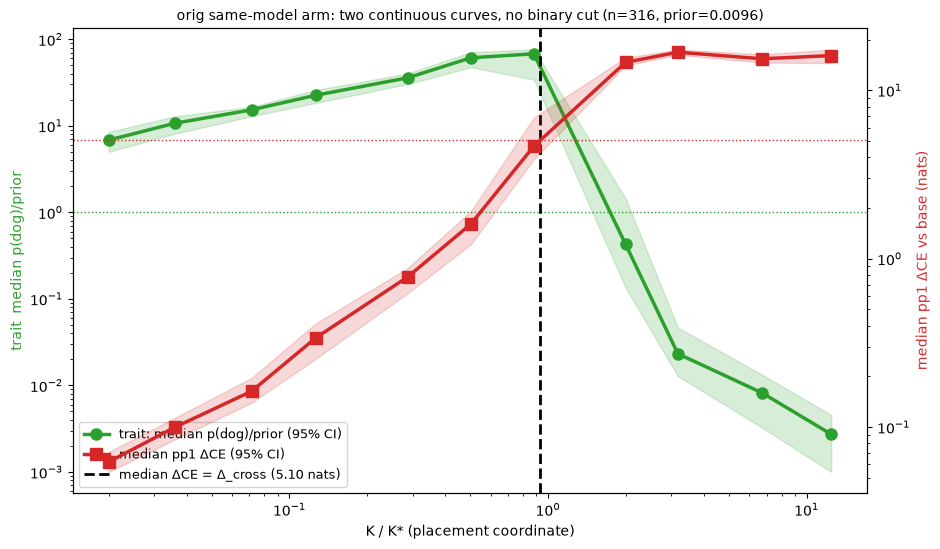

In [29]:
from subliminal_learning.stats import collapse_law as cl
be = read_json(A/'base_eval_original_animal_preference_test.json')
prior = float(np.mean(be['dog']['p_per_prompt']))
B_, C_, KCAL = cl.B_LAW, cl.C_LAW, cl.KSTAR_CALIBRATED   # designed cross-data-order fit (0.659, -0.164, 8.8e-4), 2026-09-09
rows = []
for line in Path(REPO/'run_logs/harvest_20260824/tierb_orig_runs.txt').read_text().splitlines():
    rd = Path(line.strip())
    if not line.strip() or 'ep2_lr5e-4_r32a64' not in str(rd): continue
    try:
        pp_ = json.loads((rd/'eval'/'pile_probe.json').read_text())
        pe = json.loads((rd/'preference_eval.json').read_text())
    except FileNotFoundError: continue
    pt = parse_param_tag(rd.parent.name)
    rows.append(dict(K=pt['lr']*pt['alpha']**B_*pt['rank']**C_/KCAL, kl=pp_.get('delta_ce'),
                     dce=pp_.get('delta_ce'), p=pe.get('sets', {}).get('test', {}).get('p_target')))
tc2 = pd.DataFrame(rows).dropna(); tc2 = tc2[np.isfinite(tc2.kl)]; tc2['ratio'] = tc2.p/prior
gbins = np.geomspace(tc2.K.min()*0.99, tc2.K.max()*1.01, 14)
tc2['bin'] = pd.cut(tc2.K, gbins)
recs = []
for b_, g_ in tc2.groupby('bin', observed=True):
    if len(g_) < 5: continue
    r_m, r_lo, r_hi = med_ci(g_.ratio.values); k_m, k_lo, k_hi = med_ci(g_.kl.values)
    recs.append(dict(K=g_.K.median(), r=r_m, rlo=r_lo, rhi=r_hi, kl=k_m, kllo=k_lo, klhi=k_hi, dce=g_.dce.median(), n=len(g_)))
gg = pd.DataFrame(recs).sort_values('K')
crossK = np.interp(DC_ORIG, gg.dce.values, gg.K.values)
fig, ax1 = plt.subplots(figsize=(9.5, 5.6)); ax2 = ax1.twinx()
ax1.fill_between(gg.K, np.maximum(gg.rlo, 1e-3), gg.rhi, color='tab:green', alpha=0.18)
l1, = ax1.plot(gg.K, gg.r, 'o-', color='tab:green', lw=2.5, ms=8, label='trait: median p(dog)/prior (95% CI)')
ax1.axhline(1.0, color='tab:green', ls=':', lw=1)
ax2.fill_between(gg.K, np.maximum(gg.kllo, 1e-3), gg.klhi, color='tab:red', alpha=0.18)
l2, = ax2.plot(gg.K, gg.kl, 's-', color='tab:red', lw=2.5, ms=8, label='median pp1 ΔCE (95% CI)')
ax2.axhline(DC_ORIG, color='tab:red', ls=':', lw=1)
vl = ax1.axvline(crossK, color='black', ls='--', lw=2)
ax1.set_xscale('log'); ax1.set_yscale('log'); ax2.set_yscale('log')
ax1.set_xlabel('K / K* (placement coordinate)'); ax1.set_ylabel('trait  median p(dog)/prior', color='tab:green')
ax2.set_ylabel('median pp1 ΔCE vs base (nats)', color='tab:red')
ax1.set_title(f'orig same-model arm: two continuous curves, no binary cut (n={len(tc2)}, prior={prior:.4f})', fontsize=10)
ax1.legend(handles=[l1, l2, vl], labels=[l1.get_label(), l2.get_label(), f'median ΔCE = Δ_cross ({DC_ORIG:.2f} nats)'],
           loc='lower left', frameon=True, fontsize=9)
plt.tight_layout(); fig.savefig(FIGDIR/'fig09_two_curves.png', dpi=180, bbox_inches='tight'); plt.show()

## Figure 10 — §4.7 *Trait and damage ride the same directions*

Historical section. Its interpretation and displayed results are superseded by the executed direction-analysis block above. Source code is retained below with execution disabled by default.

In [ ]:
PRIOR_ORIG, PRIOR_DS1 = 0.0096, 0.0133
fig, axes = plt.subplots(1, 3, figsize=(13.5, 4.8), sharey=True)
lo = 3e-4
for ax, a in zip(axes, ['strip(ds1)', 'samemodel(orig)', 'teacher(orig)']):
    g = mm[mm.arm == a]
    for _, r in g.iterrows():
        col = 'tab:red' if r.dead else 'tab:green'
        ax.plot([0, 1], [max(r.orig_p, lo), max(r.randm_p, lo)], '-o', color=col, alpha=0.5, lw=1.1, ms=5)
    ax.axhline(PRIOR_ORIG if 'orig' in a else PRIOR_DS1, color='0.3', ls=':', lw=1.4)
    ax.set_yscale('log'); ax.set_xticks([0, 1]); ax.set_xticklabels(['trained\ndirections', 'randomized\ndirections'])
    ax.set_title(f'{a} (n={len(g)})', fontsize=10)
axes[0].set_ylabel('p(dog) on held-out test prompts')
h = [plt.Line2D([], [], color='tab:red', marker='o', label='collapsed (anchored)'),
     plt.Line2D([], [], color='tab:green', marker='o', label='healthy'),
     plt.Line2D([], [], color='0.3', ls=':', label='base prior')]
axes[2].legend(handles=h, fontsize=9, frameon=False, loc='upper right')
fig.suptitle('randomizing the update directions returns p(dog) to ≤ base prior in every run — healthy or collapsed',
             fontsize=11, y=1.02)
plt.tight_layout(); fig.savefig(FIGDIR/'fig10_trait_deletion.png', dpi=180, bbox_inches='tight'); plt.show()
print('p(dog) medians trained → randomized, by arm × anchored fate (ledger campaign medians are '
      'label-composition-sensitive on the trained side; the deletion endpoints match):')
print(mm[mm.arm.isin(['strip(ds1)', 'samemodel(orig)', 'teacher(orig)'])]
      .groupby(['arm', 'dead']).agg(p_orig=('orig_p', 'median'), p_rand=('randm_p', 'median')).round(4).to_string())

## Figure 13 — §4.7 *Single-direction separability on dead teachers: the damage needs direction 1; the trait rides directions 1–2*

Historical section. Its interpretation and displayed results are superseded by the executed direction-analysis block above. Source code is retained below with execution disabled by default.

In [ ]:
s13 = SELDF['teachers']; cut13 = DCX['pythia-160m']
dd13 = s13[s13.stored > cut13]
V13 = ['top1', 'top2', 'top4', 'rest1', 'rest2', 'rest4']
g13 = dd13[dd13.sel.isin(V13)].groupby('sel')['p_target']
med_ce = dd13[dd13.sel.isin(V13)].groupby('sel')['delta_ce'].median().reindex(V13)
mean_p = g13.mean().reindex(V13); med_p = g13.median().reindex(V13)
aud_t = aud[(aud.variant == 'orig') & aud.run.str.contains('/teachers/')]
orig_ce = float(dd13.groupby('run')['stored'].first().median())
orig_p = float(aud_t[aud_t.run.map(AUD_BASE) > cut13].p_target.mean()) if len(aud_t) else np.nan
labs13 = ['orig\n(trained)'] + V13
ce_v = [orig_ce] + list(med_ce.values); p_v = [orig_p] + list(mean_p.values)
cols13 = ['0.4'] + ['tab:blue'] * 3 + ['tab:orange'] * 3
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.6))
axes[0].bar(range(len(labs13)), ce_v, color=cols13)
axes[0].axhline(cut13, color='crimson', ls='--', lw=1.5)
axes[0].set_xticks(range(len(labs13))); axes[0].set_xticklabels(labs13, fontsize=9)
axes[0].set_ylabel(KL_LAB); axes[0].set_title('(a) damage: median ΔCE, 126 anchored-dead teachers', fontsize=10)
axes[1].bar(range(len(labs13)), np.maximum(p_v, 1e-4), color=cols13)
axes[1].set_yscale('log'); axes[1].axhline(PRIOR_ORIG, color='0.3', ls=':', lw=1.4)
axes[1].set_xticks(range(len(labs13))); axes[1].set_xticklabels(labs13, fontsize=9)
axes[1].set_ylabel('p(dog), mean (log)'); axes[1].set_title('(b) trait: mean p(dog) — the ledger aggregation; dotted = base prior', fontsize=10)
fig.suptitle('Figure 13 — randomize Top-k (blue) vs keep only Top-k trained (Rest-k, orange): '
             'damage and trait separate at single-direction level', fontsize=11, y=1.02)
plt.tight_layout(); fig.savefig(FIGDIR/'fig13_trait_separability.png', dpi=180, bbox_inches='tight'); plt.show()
print(pd.DataFrame({'median ΔCE (nats)': ce_v, 'mean p(dog)': p_v,
                    'median p(dog)': [np.nan] + list(med_p.values)}, index=labs13).round(3).to_string())
print('paper (means): top1 0.4 nats / p 0.91; rest1 27.6 / 0.80; top2 p 0.18; top4 p 0.03')


## Figure 14 + Table 4 — §5.2 *The spectral law's own classes, tested; formation vs fate; s\* vs plain size*

Historical section. Its interpretation and displayed results are superseded by the executed direction-analysis block above. Source code is retained below with execution disabled by default.

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.8), gridspec_kw={'width_ratios': [1.1, 1]})
ax = axes[0]
labels14, sup_r, sub_r, fr14 = [], [], [], []
for a_, (lab_, b_) in SEL_ARMS.items():
    s_ = SELDF[a_]; cut_ = DCX[b_]
    dd = s_[s_.stored > cut_]
    pvv = dd.pivot_table(index='run', columns='sel', values='delta_ce', aggfunc='first')
    if not {'super', 'sub'} <= set(pvv.columns): continue
    labels14.append(lab_)
    sup_r.append(float((pvv['super'].dropna() < cut_).mean()))
    sub_r.append(float((pvv['sub'].dropna() < cut_).mean()))
    nfo = dd.groupby('run')[['n_super', 'n_dirs']].first()
    fr14.append(float((nfo.n_super / nfo.n_dirs).median()))
x14 = np.arange(len(labels14))
ax.bar(x14 - 0.18, sup_r, width=0.36, color='tab:red', label='randomize SUPERcritical pairs (their dangerous class)')
ax.bar(x14 + 0.18, sub_r, width=0.36, color='tab:blue', label='randomize SUBcritical pairs (their safe class)')
for xi, f_ in zip(x14, fr14):
    ax.text(xi, 1.02, f'{f_:.0%} of pairs\nsupercritical', ha='center', fontsize=7, color='0.3')
ax.set_xticks(x14); ax.set_xticklabels(labels14, rotation=12, fontsize=8)
ax.set_ylim(0, 1.2); ax.set_ylabel('revival fraction among anchored-dead runs')
ax.set_title('(a) direction-resolved verdict: the "safe" class carries the damage', fontsize=10)
ax.legend(fontsize=8, frameon=False, loc='upper left')
ax = axes[1]
pos = 0.0; ticks14, tlab14 = [], []
for a_, (lab_, b_) in SEL_ARMS.items():
    sh = pd.read_csv(A/f'shuttleworth_observables_{a_}.csv'); cut_ = DCX[b_]
    sh = sh[~sh['diverged'].fillna(False)]
    sh = sh[np.isfinite(sh['delta_ce'])]
    dead14 = sh['delta_ce'] > cut_
    for msk, col in ((~dead14, 'tab:green'), (dead14, 'tab:red')):
        v = sh.loc[msk, 'nl_t0.5'].clip(lower=0.5)
        ax.plot(pos + rngb.uniform(-0.16, 0.16, len(v)), v, 'o', ms=3, alpha=0.3, color=col)
        ax.plot([pos - 0.28, pos + 0.28], [v.median()] * 2, '-', color='k', lw=2)
        pos += 1.0
    ticks14.append(pos - 1.5); tlab14.append(lab_)
    pos += 0.7
ax.set_yscale('log'); ax.set_xticks(ticks14); ax.set_xticklabels(tlab14, rotation=12, fontsize=8)
ax.set_ylabel('intruder count per run (τ = 0.5; 0 at 0.5)')
ax.set_title('(b) formation vs fate: healthy (green) / dead (red) per arm; black = median', fontsize=10)
plt.tight_layout(); fig.savefig(FIGDIR/'fig14_super_sub_intruders.png', dpi=180, bbox_inches='tight'); plt.show()
AUC_ARMS = {'strip_ds1base': ('strip (ds1-base spectra — the cited scan)', 'pythia-160m-data-seed1'),
            'samemodel': ('orig same-model', 'pythia-160m'),
            'traitfree': ('trait-free (ds1)', 'pythia-160m-data-seed1'),
            'teachers': ('teachers (orig)', 'pythia-160m'),
            'm410same': ('410M same-model', 'pythia-410m'),
            'm410cross': ('410M cross-seed', 'pythia-410m-seed1')}
rows14 = []
for a_, (lab_, b_) in AUC_ARMS.items():
    d_ = pd.read_csv(A/f'intruder_threshold_{a_}.csv'); cut_ = DCX[b_]
    d_ = d_[~d_['diverged'].fillna(False)]
    d_ = d_[np.isfinite(d_['delta_ce']) & np.isfinite(d_['med_logmargin_full']) & np.isfinite(d_['dw_fro'])]
    y = (d_['delta_ce'] > cut_).astype(int)
    if y.nunique() < 2: continue
    rows14.append({'arm': lab_, 'n': len(d_), 'dead': int(y.sum()),
                   'AUC med log(1/s*)': roc_auc_score(y, d_['med_logmargin_full']),
                   'AUC max log(1/s*)': roc_auc_score(y, d_['max_logmargin_full']),
                   'AUC frac supercritical': roc_auc_score(y, d_['frac_super_full']),
                   'AUC dw_fro (plain size)': roc_auc_score(y, d_['dw_fro'])})
t4 = pd.DataFrame(rows14).set_index('arm')
auc_cols = [c for c in t4.columns if c.startswith('AUC')]
sty4 = (t4.style.format({c: '{:.3f}' for c in auc_cols})
        .background_gradient(subset=auc_cols, cmap='Blues', vmin=0.5, vmax=1.0)
        .set_caption('Table 4 — fate classification per arm (row = one arm scan; runs with finite scores; '
                     'anchored dead label on delta_ce): the spectral law\'s own statistic vs plain update size. '
                     '"margin" in the CSVs is repo shorthand for log(1/s*).'))
display(sty4)
t4.to_csv(FIGDIR/'table4_sstar_auc.csv')
print('paper (strip): s* aggregates 0.976–0.985 vs dw_fro 0.993. Teachers: frac-supercritical is near-chance '
      '(their dangerous class is ~empty where collapse is most content-pure) while strength ordering still ranks fate.')


## Figure 15 + Table 5 — §4.4 *The structure of K\*: student base × teacher × trait, with the full-seed arms*

**Construction.** One boundary threshold K\* per (animal × student base ← teacher base | teacher
recipe) slice of the cross-arm design (`analysis.kstar_structure`, the deep-dive
`docs/results/boundary_law_deep_dive.md` §3.5): core65 student cells × the shared top-10 teacher
recipes × every (animal, student base, teacher base) arm with pp1 probes — the four-animal ×
six-base bandext arms, the dog seed2seed factorial (ds/ws/fs student bases ← ds/ws/fs teacher
bases) and the lion fs1 arm. Label = pp1 ΔCE above the *student* base's anchored cut. All slice
K\* are read in ONE coordinate, (b, c) fit freely on the whole population (cell-clustered), so
they are comparable; slices need ≥ 5 dead. **Fig 15**: slice K\* against each factor (black bar =
factor-level median; marker = teacher base). **Table 5**: sequential R² of log K\* — student base
first, then the teacher factors on the residual, then trait on what remains — plus drop-one
partial R² and the per-arm free (b, c) fits.


pile_probe cache: 56216 rows of 88569 cached (548 added, 0 refreshed, 6123 inventory paths without a record, 0 unreadable/kept)


pile_probe cache: 110 rows of 88569 cached (0 added, 0 refreshed, 0 inventory paths without a record, 0 unreadable/kept)


population: 56,215 runs, 103 arms, 1030 slices (583 estimable), student bases ['orig', 'ds1', 'ds2', 'ds3', 'ws1', 'ws2', 'ws3', 'fs1', 'fs2', 'fs3', 'wc1'], teacher bases ['orig', 'ds1', 'ds2', 'ds3', 'ws1', 'ws2', 'ws3', 'fs1', 'fs2', 'fs3', 'wc1']
pooled coordinate: b = 0.573 [0.571, 0.576], c = -0.079 [-0.082, -0.076]  (n = 56,215, dead 6,602)


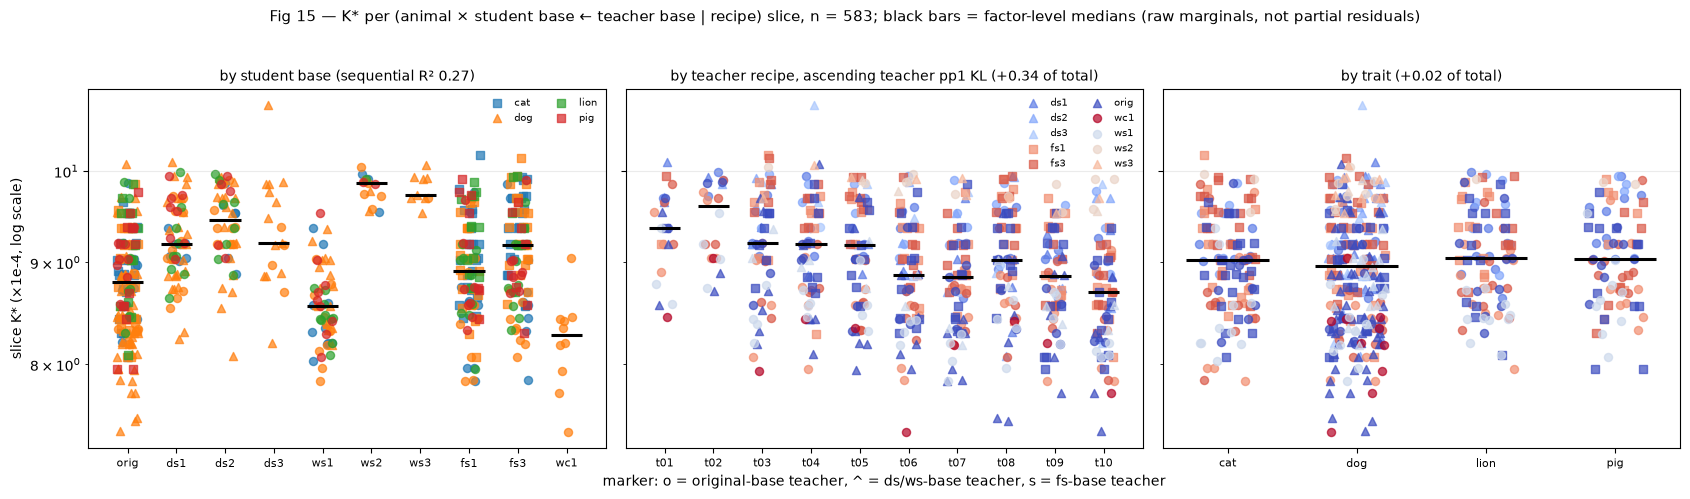


Table 5a — log K* decomposition (row unit: one factor step; sequential order as listed; full additive R² 0.695, sd log K* 0.065):
                 factor  r2_of_remaining  r2_of_total  cumulative_r2  residual_sd  partial_r2_dropone
           student base            0.272        0.272          0.272        0.055               0.378
teacher (base + recipe)            0.466        0.340          0.611        0.040               0.488
         trait (animal)            0.051        0.020          0.631        0.039               0.035
  teacher partial R² split: base 0.256 / recipe 0.232
  factor spans (ratio of level medians): {'sbase': 1.192, 'tbase': 1.172, 'teacher': 1.104, 'animal': 1.009}

Table 5b — per (animal | student base <- teacher base) arm, free (b, c) with cell-clustered 95% CI and K* (×1e-4) in the arm's own vs the pooled coordinate; gate ≥ 10 dead:
            arm   n  dead     b  b_lo  b_hi      c   c_lo   c_hi  kstar_own_x1e4  kstar_pooled_x1e4
  cat|ds1<-orig 560    8

In [30]:
from subliminal_learning.analysis import kstar_structure as ks
KS = ks.run_all(OUT, REPO)
KSF = KS.pop('_frames'); ks_meta, ks_coord, ks_dec = KS['meta'], KS['pooled_coordinate'], KS['decomposition']
print(f"population: {ks_meta['runs']:,} runs, {ks_meta['arms']} arms, {ks_meta['slices']} slices "
      f"({ks_dec['n_slices']} estimable), student bases {ks_meta['student_bases']}, teacher bases {ks_meta['teacher_bases']}")
print(f"pooled coordinate: b = {ks_coord['b']:.3f} [{ks_coord['b_ci'][0]:.3f}, {ks_coord['b_ci'][1]:.3f}], "
      f"c = {ks_coord['c']:.3f} [{ks_coord['c_ci'][0]:.3f}, {ks_coord['c_ci'][1]:.3f}]  (n = {ks_coord['n']:,}, dead {ks_coord['dead']:,})")
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8), sharey=True)
ks.plot_kstar_structure(KSF['slices'], ks_dec, axes, teacher_order=ks_meta['teachers'])
fig.suptitle(f"Fig 15 — K* per (animal × student base ← teacher base | recipe) slice, n = {ks_dec['n_slices']}; "
             "black bars = factor-level medians (raw marginals, not partial residuals)", y=1.03, fontsize=11)
fig.tight_layout(); fig.savefig(FIGDIR/'fig15_kstar_structure.png', dpi=180, bbox_inches='tight'); plt.show()
# Table 5a — sequential (base -> teacher -> trait) and partial R2 of log K*
t5a = pd.DataFrame(ks_dec['sequential'])
t5a['partial_r2_dropone'] = [ks_dec['partial_r2']['sbase'],
                             ks_dec['partial_r2']['tbase'] + ks_dec['partial_r2']['teacher'],
                             ks_dec['partial_r2']['animal']]
print('\nTable 5a — log K* decomposition (row unit: one factor step; sequential order as listed; '
      f"full additive R² {ks_dec['full_r2']:.3f}, sd log K* {ks_dec['sd_logk']:.3f}):")
print(t5a.round(3).to_string(index=False))
print('  teacher partial R² split: base', round(ks_dec['partial_r2']['tbase'], 3), '/ recipe', round(ks_dec['partial_r2']['teacher'], 3))
print('  factor spans (ratio of level medians):', {k: round(v['span'], 3) for k, v in ks_dec['level_spans'].items()})
t5a.to_csv(FIGDIR/'table5a_kstar_decomposition.csv', index=False)
# Table 5b — per-arm free (b, c) + K* (own coordinate and pooled coordinate)
t5b = KSF['arms'].dropna(subset=['kstar_pooled']).copy()
t5b['kstar_own_x1e4'] = t5b.kstar_own * 1e4; t5b['kstar_pooled_x1e4'] = t5b.kstar_pooled * 1e4
print(f"\nTable 5b — per (animal | student base <- teacher base) arm, free (b, c) with cell-clustered 95% CI "
      f"and K* (×1e-4) in the arm's own vs the pooled coordinate; gate ≥ {ks.MIN_DEAD_ARM} dead:")
print(t5b[['arm', 'n', 'dead', 'b', 'b_lo', 'b_hi', 'c', 'c_lo', 'c_hi', 'kstar_own_x1e4', 'kstar_pooled_x1e4']]
      .round(3).to_string(index=False))
t5b.to_csv(FIGDIR/'table5b_arm_free_fits.csv', index=False)
KSF['slices'].to_csv(FIGDIR/'table5c_slice_kstars.csv', index=False)


---
**Provenance.** Artifacts: `position_surgery_ce_*.jsonl` (ce-wave 08-27; KL-era twins
`position_surgery_v2*.jsonl`), the 08-28/29 direction-family campaigns
(`position_surgery_cen_{arm}_s*.jsonl` census + `*_audit.jsonl`,
`position_surgery_sub_{arm}_s*.jsonl` selector endpoints, `position_surgery_subt_{arm}_s*.jsonl`
rotation grid; run lists in `run_logs/surgcen_20260828/`), the prior-work instrument scans
(`intruder_threshold_{arm}.csv`, `shuttleworth_observables_{arm}.csv`),
`lambda_crossing_ce_*.jsonl` (ce-wave; KL-era `lambda_crossing_{arms,410m}.jsonl` +
`lambda_crossing_ext_*.jsonl` as fallback), `lambda_families_ce_*.jsonl` (λ families;
legacy `frozen_a_ablation_{scale,revival,lamstrat*,shellext*,ws1lam}_lam*_pp1.json`),
`frozen_a_ablation_strip_{frozen,moved}_r*_s*.json` (component splices),
`{diffuse,specmatch}_ladder_surgery_*_ce.json`, `trained_direction_ladder_ds1_ce.json`,
`unigram_anchor_pp1.json` (via `probe_io.anchored_dead_cut`),
`base_eval_original_animal_preference_test.json`, the `clamp_students/` tree, and
strip/tier-B run-dir records. Producers are committed under `scripts/`; the
direction-family methods SSOT is `docs/methodology/direction_analysis.md`; analysis homes:
`collapse_surgery_and_sgd.ipynb` (08-24→26 program), `collapse_claims.ipynb` (λ/clamp/
hysteresis era), `intruder_threshold_prior_work.ipynb` (§5.2 prior-work adjudication),
`nors_asks.ipynb` (component splices). Fig 8 renders earlier-program (A2) experiments by
request, provenance-tagged; the spread splice was dropped 08-26 as inconclusive (artifacts
in `spread_ladder_*.json`); the donor-potency sweep is retained on disk but not
claim-bearing and not rendered. Paper: `docs/results/collapse_two_factor_iclr.md`; claim
ledger: `collapse_claims_v2.md`.
